# Causal Bayesian Network trên dữ liệu UCI In-Vehicle Coupon

**Môn:** IT701100, Mô hình đồ thị có xác suất.

**Câu hỏi.** Nếu *mọi* coupon đều được đặt hạn dùng **2 giờ** thay vì **1 ngày**, tỉ lệ tài xế chấp nhận coupon thay đổi bao nhiêu?

Thực nghiệm trên 3 mô hình

| Mô hình | Directed Acyclic Graph - DAG | CPD của Y | So với B0 |
|---|---|---|---|
| **B0** | Hill Climbing | đếm trong dữ liệu, có làm trơn (BDeu) | mô hình gốc |
| **H1** | DAG của B0 | một neural network nhỏ (MLP) | đổi **cách tính xác suất của Y** |
| **H2** | neural network học DAG (NOTEARS-MLP) | tương tự B0 | đổi **cách tìm DAG** |


**Bản này** là bản sao của `04_coupon_simple.ipynb` với **bộ ràng buộc DAG chặt hơn** ở mục 6: mỗi nút chỉ được nhận mũi tên từ một danh sách parents được phép, kèm bảng lý do của từng luật. Mọi phần khác (dữ liệu, cách chia, ba mô hình, ba bảng kết quả) giữ nguyên. Kết quả lưu ở `artifacts/coupon_rules/`.

## Mục lục

1. [Chuẩn bị](#1)
2. [Bài toán](#2)
3. [Dữ liệu](#3)
4. [Chia dữ liệu](#4)
5. [Tính tay trước](#5)
6. [Ràng buộc DAG](#6)
7. [Khảo sát thuật toán](#7)
8. [B0: DAG truyền thống](#8)
9. [H1: xác suất bằng neural network](#9)
10. [H2: DAG bằng neural network](#10)
11. [Chạy 5 lần](#11)
12. [Bảng A: dự đoán](#12)
13. [Bảng B: intervention](#13)
14. [Bảng C: độ tin cậy và chi phí](#14)
15. [Kết luận](#15)

<a id="1"></a>
## 1. Chuẩn bị

**Cách chạy.**

- *Máy cá nhân:* tạo môi trường Python 3.13 (`python3.13 -m venv .venv313`), cài `pip install -r requirements.txt`, rồi chọn Kernel → Restart & Run All. Notebook 04 chạy khoảng 6 phút trên CPU 8 lõi (đo ngày 2026-11-10 trên máy Apple Silicon, không dùng GPU). Lần chạy lưu trong bản này (ngày 2026-11-13) mất khoảng 23 phút vì máy đang bận việc khác (xem Bảng C.4).
- *Google Colab:* chỉ cần tải file notebook này lên.
- *Chạy thử nhanh (khoảng 1 phút):* đặt biến môi trường `COUPON_QUICK=1` trước khi mở notebook, hoặc sửa `QUICK = True` ở ô cấu hình. Khi đó chỉ chạy 2 seed với rất ít lần lặp, số liệu chỉ để kiểm tra code.

In [1]:
import sys, subprocess, os

# Colab chưa có sẵn pgmpy và dowhy nên phải cài; máy cá nhân đã cài qua requirements.txt thì bỏ qua.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pgmpy>=1.1", "dowhy>=0.12", "torch",
                    "scikit-learn", "networkx>=3.3", "matplotlib", "pandas", "numpy", "scipy"], check=True)
print("Đang chạy trên Colab:", IN_COLAB)

Đang chạy trên Colab: False


In [2]:
# ----- Thư viện có sẵn của Python -----
import json, time, hashlib, itertools, functools, platform, random, warnings, logging, io, zipfile, urllib.request
from dataclasses import dataclass, asdict
from pathlib import Path

# ----- Tính toán, bảng số liệu, vẽ hình -----
import numpy as np                      # mảng số
import pandas as pd                     # bảng dữ liệu (DataFrame)
import networkx as nx                   # đồ thị (nút, cạnh)
import matplotlib.pyplot as plt         # vẽ hình
from matplotlib.colors import LinearSegmentedColormap   # tự tạo dải màu cho bản đồ nhiệt
import scipy.stats as st                # kiểm định thống kê (chi-square)
import torch                            # mạng nơ-ron (dùng cho H1 và H2)
import sklearn, pgmpy, dowhy
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, brier_score_loss, log_loss
from IPython.display import display

# ----- pgmpy: mạng Bayes rời rạc -----
from pgmpy.models import DiscreteBayesianNetwork                       # mạng Bayes = DAG + bảng xác suất
from pgmpy.estimators import HillClimbSearch, PC, ExpertKnowledge      # học DAG + khai báo ràng buộc
from pgmpy.estimators import BayesianEstimator                         # học bảng xác suất có làm trơn
from pgmpy.factors.discrete import TabularCPD                          # một bảng xác suất có điều kiện
from pgmpy.inference import VariableElimination                        # tính xác suất trên mạng

# ----- DoWhy: kiểm tra phép can thiệp -----
from dowhy import CausalModel

# Tắt các dòng cảnh báo dài để output gọn, dễ đọc
warnings.filterwarnings("ignore")
logging.getLogger("dowhy").setLevel(logging.ERROR)
logging.getLogger("pgmpy").setLevel(logging.ERROR)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

# ----- Kiểu hình vẽ dùng chung -----
# Mỗi mô hình một màu và một kiểu chấm cố định trong MỌI hình; hai loại hạn coupon cũng vậy.
# (Bộ màu đã được kiểm tra là người mù màu vẫn phân biệt được; kiểu chấm khác nhau là lớp bảo hiểm thứ hai.)
COLOR = {"B0": "#2a78d6", "H1": "#eb6834", "H2": "#1baf7a"}        # xanh dương, cam, xanh ngọc
MARKER = {"B0": "o", "H1": "s", "H2": "D"}                         # tròn, vuông, thoi
ARM_COLOR = {"0": "#6250d6", "1": "#eda100"}                       # hạn 1 ngày: tím; hạn 2 giờ: vàng
ARM_LABEL = {"0": "hạn 1 ngày (T = 0)", "1": "hạn 2 giờ (T = 1)"}
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"             # màu chữ chính, chữ phụ, chữ mờ
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_SOFT, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
                     "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

# Thư mục làm việc: chạy từ thư mục gốc dự án, từ notebooks/ hay trên Colab đều được
if IN_COLAB:
    ROOT = Path("/content/pgm_coupon")
elif Path.cwd().name in ("notebooks", "scripts"):
    ROOT = Path.cwd().parent
else:
    ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "raw" / "coupon"          # nơi để file dữ liệu gốc
OUT = ROOT / "artifacts" / "coupon_rules"          # nơi lưu mọi kết quả của notebook này
RAW_DIR.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# Ghi lại phiên bản thư viện và phần cứng (đề bài yêu cầu báo cáo)
ENV = {"python": sys.version.split()[0], "máy": platform.platform(), "số lõi CPU": os.cpu_count(),
       "GPU (cuda)": torch.cuda.is_available(), "numpy": np.__version__, "pandas": pd.__version__,
       "networkx": nx.__version__, "scikit-learn": sklearn.__version__, "pgmpy": pgmpy.__version__,
       "dowhy": dowhy.__version__, "torch": torch.__version__}
pd.Series(ENV, name="giá trị").to_frame()

/Users/tuanla/workspace/master/probabilistic-graphical-models/.venv313/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


,giá trị
python,3.13.18
máy,macOS-27.0.1-arm64-arm-64bit-Mach-O
số lõi CPU,8
GPU (cuda),False
numpy,2.5.4
pandas,3.1.1
networkx,3.7
scikit-learn,1.9.1
pgmpy,1.1.2
dowhy,0.14


### 1.1 Cấu hình

Centralize configuration

In [3]:
@dataclass(frozen=True) #frozen=True: không cho sửa sau khi tạo
class Config:
    # ----- Dữ liệu -----
    zip_url: str = "https://archive.ics.uci.edu/static/public/603/in+vehicle+coupon+recommendation.zip"
    csv_name: str = "in-vehicle-coupon-recommendation.csv"
    # ----- Chia dữ liệu và số lần chạy -----
    seeds: tuple = (0, 1, 2, 3, 4)          # 5 seed = 5 lần chạy cặp
    split: tuple = (0.70, 0.15, 0.15)       # tỉ lệ TRAIN / VALIDATION / TEST
    # ----- Bảng xác suất (CPD) -----
    ess: float = 5.0                        # độ mạnh làm trơn BDeu (equivalent sample size)
    # ----- B0: Hill Climbing -----
    b0_scores: tuple = ("bic-d", "bdeu", "k2")   # các hàm điểm đem thử
    b0_max_indegree: tuple = (4, 6)              # số cha tối đa của một nút đem thử
    # ----- H1: mạng nơ-ron cho xác suất của Y -----
    h1_hidden: tuple = (32, 16)             # hai lớp ẩn: 32 rồi 16 nơ-ron
    h1_dropout: float = 0.2                 # tắt ngẫu nhiên 20% nơ-ron khi học
    h1_lr: float = 1e-3                     # tốc độ học
    h1_batch: int = 256                     # mỗi bước học dùng 256 dòng
    h1_max_epochs: int = 200                # tối đa 200 lượt duyệt dữ liệu
    h1_patience: int = 10                   # dừng nếu 10 lượt liền VALIDATION không tốt lên
    # ----- H2: NOTEARS-MLP học DAG -----
    h2_hidden: int = 10                     # mỗi nút có một mạng nhỏ với 10 nơ-ron ẩn
    h2_lambda1: float = 0.01                # phạt L1: ép các cạnh yếu về 0 (đồ thị thưa)
    h2_lambda2: float = 0.01                # phạt L2: giữ trọng số nhỏ
    h2_l1_scale_T: float = 0.1              # phạt L1 nhẹ hơn 10 lần cho cạnh đi vào T (giải thích ở mục 10)
    h2_max_outer: int = 20                  # số vòng ngoài tối đa
    h2_inner_steps: int = 100               # số bước tối ưu trong mỗi vòng
    h2_h_tol: float = 1e-5                  # coi là "không còn vòng kín" khi h(A) nhỏ hơn mức này (số thực 32 bit không phân biệt được mức nhỏ hơn)
    h2_rho_max: float = 1e16                # mức phạt vòng kín tối đa
    h2_thresholds: tuple = (0.05, 0.10, 0.15, 0.20, 0.30)   # các ngưỡng giữ cạnh đem thử
    # ----- Độ bất định và kiểm tra -----
    n_boot: int = 100                       # số lần bootstrap để tính khoảng tin cậy 95%
    n_refute: int = 100                     # số lần mô phỏng của mỗi refuter DoWhy
    subset_fraction: float = 0.8            # refuter "data subset" giữ lại 80% dữ liệu
    n_placebo: int = 20                     # số lần xáo trộn T cho placebo tự cài trên chính mô hình


# QUICK = True: chạy thử cực nhanh để kiểm tra code (2 seed, rất ít lần lặp) => smoke test
QUICK = os.environ.get("COUPON_QUICK", "0") == "1"
CFG = Config(seeds=(0, 1), n_boot=5, n_refute=5, n_placebo=3) if QUICK else Config()

# Bốn tầng biến theo thứ tự thời gian (giải thích ở mục 2). Thứ tự trong danh sách này dùng cho mọi bảng và ma trận.
TIERS: dict[str, list[str]] = {
    "respondent": ["habit_match", "age_bin", "income_bin", "gender", "has_children"],                    # người trả lời
    "scenario": ["coupon", "destination", "time_bin", "passenger", "weather", "dist", "direction_same"],  # kịch bản lái xe
    "treatment": ["T"],                                                                                  # hạn coupon
    "outcome": ["Y"],                                                                                    # có nhận coupon không
}
NODES: list[str] = [n for tier in TIERS.values() for n in tier]                          # 14 nút của DAG
TIER_OF: dict[str, int] = {n: k for k, tier in enumerate(TIERS.values()) for n in tier}  # nút → số thứ tự tầng (0..3)
RESP, SCEN = TIERS["respondent"], TIERS["scenario"]
COVARIATES: list[str] = RESP + SCEN       # 12 biến nền: mọi thứ biết được TRƯỚC khi coupon hiện ra
print("QUICK =", QUICK, "| số nút:", len(NODES), "| seeds:", CFG.seeds, "| n_boot:", CFG.n_boot)


def set_seed(seed: int) -> np.random.Generator:
    """Cố định mọi nguồn ngẫu nhiên để chạy lại ra đúng kết quả cũ.

    Tham số: seed — một số nguyên bất kỳ.
    Trả về: bộ sinh số ngẫu nhiên của numpy (dùng cho bootstrap và xáo trộn).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    return np.random.default_rng(seed)


def as_int(col: pd.Series) -> np.ndarray:
    """Đổi một cột chữ "0"/"1" thành số 0/1 để tính trung bình và chấm điểm.

    Tham số: col — cột T hoặc Y (đang lưu dạng chữ vì pgmpy coi mọi biến là phân loại).
    Trả về: mảng số nguyên 0/1.
    """
    return col.astype(int).to_numpy()

QUICK = False | số nút: 14 | seeds: (0, 1, 2, 3, 4) | n_boot: 100


<a id="2"></a>
## 2. Bài toán

**Bối cảnh.** Dữ liệu là một khảo sát trên Amazon Mechanical Turk (Wang và cộng sự, 2017). Người tham gia được cho xem các **tình huống lái xe giả định**: đang đi đâu, mấy giờ, thời tiết thế nào, chở ai; rồi một coupon hiện trên màn hình xe (loại quán, hạn dùng). Họ trả lời có dùng coupon đó không. Mỗi dòng dữ liệu là **một lần hỏi**, mỗi người trả lời khoảng 20 lần.

**Hai biến chính.**

- **T (treatment) = hạn coupon:** T = 0 là hạn **1 ngày** (control group), T = 1 là hạn **2 giờ** (treatment group).
- **Y (outcome, kết quả) = có chấp nhận coupon không:** Y = 1 là có, Y = 0 là không.

**Vì sao chọn T là hạn coupon?** Có thể thay đổi được. Nhà phát hành coupon tự đặt hạn dùng, không tốn chi phí.

**Con số cần tìm (estimand).** Hiệu ứng trung bình của việc đổi hạn (ATE, average treatment effect):

$$\text{ATE} = P(Y{=}1 \mid do(T{=}1)) - P(Y{=}1 \mid do(T{=}0))$$

=> Tỉ lệ chấp nhận *nếu ép mọi coupon có hạn 2 giờ* trừ tỉ lệ chấp nhận *nếu ép mọi coupon có hạn 1 ngày*.

**Vì sao không so sánh thẳng hai nhóm coupon là xong?** Vì hai nhóm không giống nhau từ đầu. Ví dụ đời thường: nếu người khoẻ hay tập gym hơn, thì "người tập gym ít ốm hơn" chưa chắc do gym. Ở đây, loại quán và hoàn cảnh lái xe quyết định coupon được gán hạn nào, và cũng quyết định người ta có thích coupon không.

### 2.1 Glossary

| Term | Ý nghĩa | Ví dụ trong bài |
|---|---|---|
| Variable, node | Một cột dữ liệu, trong bài gọi là *biến*. Trong DAG, mỗi biến là một *nút* (node) | `coupon` = loại quán của coupon |
| State | Các giá trị mà một biến có thể nhận | `weather` nhận Sunny, Rainy hoặc Snowy |
| DAG (Directed Acyclic Graph) | Sơ đồ gồm các nút và **mũi tên một chiều**, không có vòng kín. Mũi tên A → B nghĩa là "A ảnh hưởng trực tiếp đến B" | T → Y: hạn coupon ảnh hưởng đến việc chấp nhận |
| Parents, parent set | Các nút có mũi tên trỏ **thẳng** vào một nút; *parent set* là cả nhóm đó | parents của Y có thể là T, `coupon`, `habit_match` |
| CPD (Conditional Probability Distribution) | Bảng xác suất có điều kiện: với mỗi tổ hợp giá trị của parents, nút nhận từng giá trị với xác suất bao nhiêu | P(Y = 1 khi T = 2 giờ và coupon = Bar) |
| Bayesian Network (BN) | DAG + một CPD cho mỗi nút | cả mô hình B0 |
| Observation vs. intervention, do(·) | *Observation:* nhìn những coupon vốn đã có hạn 2 giờ (dữ liệu như vậy gọi là *observational data*). *Intervention* do(T = 2 giờ): tự tay đặt mọi coupon thành 2 giờ, giữ nguyên mọi thứ khác | hai cách này cho hai con số khác nhau |
| Treatment, control group | *Treatment* là biến ta can thiệp (T). *Treatment group* là nhóm T = 1 (hạn 2 giờ), *control group* là nhóm T = 0 (hạn 1 ngày) | mục 2 |
| Confounder, confounding | *Confounder* là biến ảnh hưởng đến **cả T lẫn Y**; *confounding* là độ lệch mà nó gây ra cho phép so sánh thô | loại quán `coupon` |
| Backdoor path | Đường nối T với Y mà đi vòng qua confounder | T ← coupon → Y |
| Adjustment set | Nhóm biến ta giữ cố định khi so sánh, để chặn mọi backdoor path | so sánh 2 giờ với 1 ngày *trong cùng loại quán* |
| Overlap (positivity) | Trong mỗi nhóm đem so sánh phải có cả coupon 2 giờ lẫn coupon 1 ngày | không có thì không so được |
| Train / validation / test split | Ba phần dữ liệu TRAIN, VALIDATION, TEST: để học, để chọn cấu hình, để chấm điểm cuối | mục 4 |
| Bootstrap, 95% confidence interval (CI 95%) | Lấy mẫu lại dữ liệu nhiều lần để xem kết quả dao động trong khoảng nào; CI 95% là khoảng chứa 95% số kết quả ở giữa | mục 13 |
| Refuter (refutation test) | Phép thử "cố tình phá": làm hỏng dữ liệu một cách có chủ đích rồi xem ước lượng có phản ứng đúng không | mục 14 |
| One-hot encoding | Đổi một biến phân loại thành các cột 0/1 để đưa vào neural network | Sunny → (0, 0, 1) |
| MLP (Multi-Layer Perceptron) | Neural network đơn giản gồm vài lớp nối tiếp | H1 |

<a id="3"></a>
## 3. Dữ liệu

**Mục tiêu.** Tải file gốc từ UCI, xem nó có vấn đề gì, đổi thành 14 biến gọn của bài, và loại các dòng không dùng được.

### 3.1 Download & Metadata

In [4]:
def download_data(folder: Path) -> Path:
    """Tải file zip chính thức của UCI và giải nén file CSV, chỉ khi máy chưa có.

    Tham số: folder — thư mục để file dữ liệu.
    Trả về: đường dẫn tới file CSV.
    """
    csv_path = folder / CFG.csv_name
    if not csv_path.exists():
        print("Đang tải dữ liệu từ UCI ...")
        content = urllib.request.urlopen(CFG.zip_url, timeout=120).read()
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            z.extract(CFG.csv_name, folder)
    return csv_path


RAW_CSV = download_data(RAW_DIR)
# sha256 là "dấu vân tay" của file: file đổi một ký tự thì dãy này đổi, nhờ đó biết chắc đang dùng đúng phiên bản dữ liệu
SOURCE = {"bộ dữ liệu": "In-Vehicle Coupon Recommendation", "UCI ID": 603, "DOI": "10.24432/C5GS4P", "giấy phép": "CC BY 4.0",
          "file": CFG.csv_name, "sha256": hashlib.sha256(RAW_CSV.read_bytes()).hexdigest(), "ngày tải": "2026-11-06",
          "trích dẫn": "Wang, Rudin, Doshi-Velez, Liu, Klampfl, MacNeille (2017). JMLR 18(70):1-37."}
pd.Series(SOURCE, name="giá trị").to_frame()

,giá trị
bộ dữ liệu,In-Vehicle Coupon Recommendation
UCI ID,603
DOI,10.24432/C5GS4P
giấy phép,CC BY 4.0
file,in-vehicle-coupon-recommendation.csv
sha256,d47897367f5a12a31dece0f4e42d7bd9da76d7016b568d...
ngày tải,2026-11-06
trích dẫn,"Wang, Rudin, Doshi-Velez, Liu, Klampfl, MacNei..."


### 3.2 Dataset understanding

Trước khi dùng phải biết dữ liệu có bao nhiêu dòng, cột nào bị thiếu, cột nào vô dụng.

In [5]:
def load_raw(path: Path) -> pd.DataFrame:
    """Đọc file CSV gốc, giữ mọi cột ở dạng chữ đúng như UCI ghi.

    Tham số: path — đường dẫn file CSV.
    Trả về: bảng 12.684 dòng, thêm cột row_id (số thứ tự dòng, để về sau truy lại được từng dòng).
    """
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)     # keep_default_na=False: ô trống giữ là chuỗi rỗng ""
    raw = raw.rename(columns={"passanger": "passenger"})          # file gốc viết sai chính tả tên cột này
    raw.insert(0, "row_id", np.arange(len(raw)))
    return raw


def audit_raw(raw: pd.DataFrame) -> pd.DataFrame:
    """Với mỗi cột của file gốc: có bao nhiêu giá trị khác nhau, bao nhiêu ô trống.

    Tham số: raw — bảng từ load_raw().
    Trả về: bảng mỗi dòng là một cột của file gốc.
    """
    rows = []
    for col in raw.columns:
        if col == "row_id":
            continue
        rows.append({"cột": col, "số giá trị khác nhau": raw[col].nunique(), "số ô trống": int((raw[col] == "").sum())})
    return pd.DataFrame(rows)


raw = load_raw(RAW_CSV)
AUDIT = audit_raw(raw)
n_dup = int(raw.drop(columns="row_id").duplicated().sum())
print(f"File gốc: {len(raw)} dòng, {raw.shape[1] - 1} cột, {n_dup} dòng trùng hoàn toàn với một dòng khác.")
print(f"Tỉ lệ chấp nhận coupon (Y = 1): {(raw['Y'] == '1').mean():.3f} | tỉ lệ coupon hạn 2 giờ: {(raw['expiration'] == '2h').mean():.3f}")
AUDIT.T

File gốc: 12684 dòng, 26 cột, 74 dòng trùng hoàn toàn với một dòng khác.
Tỉ lệ chấp nhận coupon (Y = 1): 0.568 | tỉ lệ coupon hạn 2 giờ: 0.441


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
cột,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,car,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
số giá trị khác nhau,3,4,3,3,5,5,2,2,8,5,2,6,25,9,6,6,6,6,6,6,1,2,2,2,2,2
số ô trống,0,0,0,0,0,0,0,0,0,0,0,0,0,0,12576,107,217,151,130,189,0,0,0,0,0,0


**Kết quả.** Bốn cột gốc bị bỏ: `car` (gần như trống hoàn toàn), `toCoupon_GEQ5min` (chỉ có một giá trị), `direction_opp` (ngược với `direction_same`), `temperature` (gần trùng với `weather`). Các dòng trùng hoàn toàn được giữ lại vì hai người khác nhau vẫn có thể có cùng hồ sơ và cùng câu trả lời.

### 3.3 Đổi thành 14 biến của bài

Hai việc:</br>
(1) gộp các mức quá chi tiết lại cho gọn, ví dụ 5 khung giờ thành sáng, chiều, tối; </br>
(2) tạo lại mã người trả lời `resp_id`. File gốc không có cột này, nhưng các dòng của cùng một người nằm **liền nhau** và có cùng 13 cột thông tin cá nhân, nên cứ thấy thông tin cá nhân đổi là sang người mới.

CPD của một nút to theo cấp số nhân với số mức của parents, nên gộp mức giúp mỗi ô của bảng có đủ dữ liệu.

In [6]:
# 13 cột mô tả người trả lời trong file gốc (dùng để nhận ra "đổi sang người mới")
PERSON_COLS = ["gender", "age", "maritalStatus", "has_children", "education", "occupation", "income", "car",
               "Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]
# Loại quán của coupon → cột "tần suất đến loại quán đó" tương ứng trong file gốc
HABIT_COL_OF = {"Bar": "Bar", "Coffee House": "CoffeeHouse", "Carry out & Take away": "CarryAway",
                "Restaurant(<20)": "RestaurantLessThan20", "Restaurant(20-50)": "Restaurant20To50"}


def make_resp_id(raw: pd.DataFrame) -> pd.Series:
    """Đánh số người trả lời: các dòng liền nhau có cùng 13 cột cá nhân được coi là một người.

    Tham số: raw — bảng gốc.
    Trả về: cột resp_id (0, 1, 2, ...) cùng độ dài với raw.
    """
    key = raw[PERSON_COLS].astype(str).agg("|".join, axis=1)        # ghép 13 cột thành một chuỗi "chữ ký" của người
    is_new_person = key.ne(key.shift(fill_value="__start__"))       # True ở dòng mà chữ ký khác dòng ngay trên
    return (is_new_person.cumsum() - 1).rename("resp_id")           # cộng dồn số lần "đổi người" → mã người


def recode(raw: pd.DataFrame) -> pd.DataFrame:
    """Đổi bảng gốc thành 14 biến của bài, kèm row_id và resp_id.

    Tham số: raw — bảng gốc.
    Trả về: bảng cùng số dòng; habit_match có thể trống nếu người đó không khai tần suất đến loại quán của coupon.
    """
    d = pd.DataFrame({"row_id": raw["row_id"].astype(int), "resp_id": make_resp_id(raw).astype(int)})
    # ----- Tầng 2: kịch bản lái xe -----
    d["coupon"] = raw["coupon"]
    d["destination"] = raw["destination"]
    d["time_bin"] = raw["time"].map({"7AM": "morning", "10AM": "morning", "2PM": "afternoon", "6PM": "evening", "10PM": "evening"})
    d["passenger"] = raw["passenger"]
    d["weather"] = raw["weather"]
    # Quãng đường tới quán: file gốc có hai cột cờ (>= 15 phút, >= 25 phút) → gộp thành một biến 3 mức
    d["dist"] = np.select([raw["toCoupon_GEQ25min"] == "1", raw["toCoupon_GEQ15min"] == "1"], ["25+", "15-25"], default="<15")
    d["direction_same"] = raw["direction_same"]
    # ----- Tầng 3 và 4: treatment và outcome -----
    d["T"] = (raw["expiration"] == "2h").astype(int).astype(str)     # hạn 1 ngày → "0", hạn 2 giờ → "1"
    d["Y"] = raw["Y"].astype(str)
    # ----- Tầng 1: người trả lời -----
    # habit_match: với mỗi dòng, lấy tần suất người đó đến ĐÚNG loại quán của coupon ở dòng đó
    habit_col = raw["coupon"].map(HABIT_COL_OF)
    habit_raw = pd.Series([raw.at[i, c] for i, c in zip(raw.index, habit_col)], index=raw.index)
    d["habit_match"] = habit_raw.map({"never": "low", "less1": "low", "1~3": "mid", "4~8": "high", "gt8": "high"})
    d["age_bin"] = raw["age"].map({"below21": "<26", "21": "<26", "26": "26-35", "31": "26-35",
                                   "36": "36-50", "41": "36-50", "46": "36-50", "50plus": "50+"})
    d["income_bin"] = raw["income"].map({"Less than $12500": "<37.5k", "$12500 - $24999": "<37.5k", "$25000 - $37499": "<37.5k",
                                         "$37500 - $49999": "37.5-75k", "$50000 - $62499": "37.5-75k", "$62500 - $74999": "37.5-75k",
                                         "$75000 - $87499": "75k+", "$87500 - $99999": "75k+", "$100000 or More": "75k+"})
    d["gender"] = raw["gender"]
    d["has_children"] = raw["has_children"]
    return d


df_all = recode(raw)
rows_per_person = df_all.groupby("resp_id").size()
print(f"Tìm được {rows_per_person.shape[0]} người trả lời; mỗi người có từ {rows_per_person.min()} đến {rows_per_person.max()} dòng "
      f"(phổ biến nhất: {rows_per_person.mode().iloc[0]} dòng).")
df_all.head(3)

Tìm được 587 người trả lời; mỗi người có từ 6 đến 34 dòng (phổ biến nhất: 22 dòng).


,row_id,resp_id,coupon,destination,time_bin,passenger,weather,dist,direction_same,T,Y,habit_match,age_bin,income_bin,gender,has_children
0,0,0,Restaurant(<20),No Urgent Place,afternoon,Alone,Sunny,<15,0,0,1,high,<26,37.5-75k,Female,1
1,1,0,Coffee House,No Urgent Place,morning,Friend(s),Sunny,<15,0,1,0,low,<26,37.5-75k,Female,1
2,2,0,Carry out & Take away,No Urgent Place,morning,Friend(s),Sunny,15-25,0,1,1,NaN,<26,37.5-75k,Female,1


### 3.4 Loại dòng không dùng được

Hai loại dòng bị loại, và phải ghi rõ số dòng trước và sau mỗi bước (*eligibility flow*):

1. **Coupon quán Bar khi đang đi làm (Work):** trong dữ liệu, nhóm này **không có** coupon hạn 2 giờ nào. Không có gì để so sánh nên vi phạm overlap (G4).
2. **Thiếu `habit_match`:** người đó không khai tần suất đến loại quán của coupon.

In [7]:
def eligibility(d: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Loại các dòng không dùng được và ghi lại số dòng trước, sau mỗi bước.

    Tham số: d — bảng đã mã hoá từ recode().
    Trả về: (bảng còn lại đã đánh lại chỉ số dòng, bảng tóm tắt các bước loại).
    """
    flow = [{"bước": "file UCI gốc", "số dòng loại": 0, "còn lại": len(d)}]
    keep = pd.Series(True, index=d.index)
    # Bước 1: nhóm Bar × Work không có coupon 2 giờ nào
    bar_work = (d["coupon"] == "Bar") & (d["destination"] == "Work")
    print(f"Nhóm Bar × Work: {int(bar_work.sum())} dòng, trong đó {int((d.loc[bar_work, 'T'] == '1').sum())} dòng hạn 2 giờ.")
    keep &= ~bar_work
    flow.append({"bước": "loại Bar × Work (không có coupon 2 giờ)", "số dòng loại": int(bar_work.sum()), "còn lại": int(keep.sum())})
    # Bước 2: thiếu habit_match
    no_habit = keep & d["habit_match"].isna()
    keep &= ~no_habit
    flow.append({"bước": "loại dòng thiếu habit_match", "số dòng loại": int(no_habit.sum()), "còn lại": int(keep.sum())})
    out = d.loc[keep].reset_index(drop=True)
    assert out[NODES].isna().sum().sum() == 0, "vẫn còn ô trống trong 14 biến"
    return out, pd.DataFrame(flow)


df, FLOW = eligibility(df_all)
print(f"Dữ liệu dùng cho bài: {len(df)} dòng của {df['resp_id'].nunique()} người. "
      f"Tỉ lệ Y = 1: {as_int(df['Y']).mean():.3f}; tỉ lệ T = 1 (hạn 2 giờ): {as_int(df['T']).mean():.3f}.")
FLOW

Nhóm Bar × Work: 487 dòng, trong đó 0 dòng hạn 2 giờ.
Dữ liệu dùng cho bài: 12037 dòng của 580 người. Tỉ lệ Y = 1: 0.577; tỉ lệ T = 1 (hạn 2 giờ): 0.458.


,bước,số dòng loại,còn lại
0,file UCI gốc,0,12684
1,loại Bar × Work (không có coupon 2 giờ),487,12197
2,loại dòng thiếu habit_match,160,12037


### 3.5 Variable dictionary

"Chứng minh thư" của 14 biến: có những mức nào, mỗi mức bao nhiêu dòng, thuộc tầng nào.

In [8]:
def variable_dictionary(d: pd.DataFrame) -> pd.DataFrame:
    """Lập từ điển biến: số mức, từng mức có bao nhiêu dòng, tầng thời gian và vai trò trong DAG.

    Tham số: d — dữ liệu sau eligibility().
    Trả về: bảng 14 dòng, mỗi dòng một biến.
    """
    tier_name = ["1. người trả lời (trước T)", "2. kịch bản (trước T)", "3. treatment", "4. outcome"]
    role = ["có thể → Y; cấm → T", "có thể → T và → Y", "hạn coupon: 0 = 1 ngày, 1 = 2 giờ", "1 = chấp nhận coupon"]
    rows = []
    for col in NODES:
        counts = d[col].value_counts()
        rows.append({"biến": col, "số mức": len(counts), "mức = số dòng": ", ".join(f"{k} = {v}" for k, v in counts.items()),
                     "tầng": tier_name[TIER_OF[col]], "vai trò": role[TIER_OF[col]]})
    return pd.DataFrame(rows)


VARDICT = variable_dictionary(df)
VARDICT.to_csv(OUT / "variable_dictionary.csv", index=False)
with pd.option_context("display.max_colwidth", 120):
    display(VARDICT)

,biến,số mức,mức = số dòng,tầng,vai trò
0,habit_match,3,"low = 4925, mid = 3750, high = 3362",1. người trả lời (trước T),có thể → Y; cấm → T
1,age_bin,4,"26-35 = 4342, <26 = 3033, 36-50 = 2956, 50+ = 1706",1. người trả lời (trước T),có thể → Y; cấm → T
2,income_bin,3,"<37.5k = 4621, 37.5-75k = 4116, 75k+ = 3300",1. người trả lời (trước T),có thể → Y; cấm → T
3,gender,2,"Female = 6193, Male = 5844",1. người trả lời (trước T),có thể → Y; cấm → T
4,has_children,2,"0 = 7073, 1 = 4964",1. người trả lời (trước T),có thể → Y; cấm → T
5,coupon,5,"Coffee House = 3924, Restaurant(<20) = 2759, Carry out & Take away = 2371, Bar = 1513, Restaurant(20-50) = 1470",2. kịch bản (trước T),có thể → T và → Y
6,destination,3,"No Urgent Place = 6184, Home = 3197, Work = 2656",2. kịch bản (trước T),có thể → T và → Y
7,time_bin,3,"evening = 5166, morning = 4894, afternoon = 1977",2. kịch bản (trước T),có thể → T và → Y
8,passenger,4,"Alone = 6748, Friend(s) = 3249, Partner = 1054, Kid(s) = 986",2. kịch bản (trước T),có thể → T và → Y
9,weather,3,"Sunny = 9635, Snowy = 1305, Rainy = 1097",2. kịch bản (trước T),có thể → T và → Y


<a id="4"></a>
## 4. Chia dữ liệu

**Mục tiêu.** Chia dữ liệu thành ba phần, dùng chung cho cả ba mô hình.

**Ý tưởng.** Hình dung việc ôn thi:

| Phần | Tỉ lệ | Giống như | Dùng để |
|---|---|---|---|
| TRAIN | 70% | sách để học | học DAG, học CPD, huấn luyện neural network |
| VALIDATION | 15% | đề thi thử | chọn cấu hình (hàm điểm nào, ngưỡng nào, dừng học lúc nào) |
| TEST | 15% | đề thi thật, chỉ mở **một** lần | chấm điểm cuối cùng |

Hai điểm quan trọng:

- **Chia theo người.** Một người trả lời khoảng 20 dòng và các câu trả lời của họ giống nhau. Nếu dòng của cùng một người nằm ở cả TRAIN lẫn TEST thì mô hình "biết trước đề", điểm bị ảo (giả định G6).
- **Chia 5 lần với 5 seed.** Mỗi seed cho một cách chia. Trong một lần chạy, B0, H1, H2 dùng **đúng cùng** ba phần dữ liệu, nên khác biệt giữa chúng là do phương pháp chứ không do may rủi khi chia. Đề bài gọi đây là *paired runs* (chạy cặp).

In [9]:
def make_split(d: pd.DataFrame, seed: int) -> dict[str, list[int]]:
    """Chia NGƯỜI trả lời thành TRAIN / VALIDATION / TEST rồi trả về row_id của từng phần.

    Tham số: d — dữ liệu đủ điều kiện; seed — hạt giống ngẫu nhiên của lần chia này.
    Trả về: dict {"train": [row_id...], "val": [...], "test": [...]}.
    """
    # 1) Với mỗi người: tỉ lệ chấp nhận coupon của họ. Xếp người thành 3 nhóm (ít nhận, vừa, hay nhận)
    #    để ba phần dữ liệu có tỉ lệ ba kiểu người như nhau (chia "có phân tầng").
    person = d.assign(y=as_int(d["Y"])).groupby("resp_id")["y"].mean().rename("y_rate").to_frame()
    person["group3"] = pd.qcut(person["y_rate"].rank(method="first"), 3, labels=["lo", "mid", "hi"])
    # 2) Chia danh sách NGƯỜI: tách TRAIN trước, phần còn lại chia đôi thành VALIDATION và TEST
    f_train, f_val, f_test = CFG.split
    p_train, p_rest = train_test_split(person.index, test_size=1 - f_train, stratify=person["group3"], random_state=seed)
    p_val, p_test = train_test_split(p_rest, test_size=f_test / (f_val + f_test), stratify=person.loc[p_rest, "group3"], random_state=seed)
    # 3) Đổi danh sách người thành danh sách dòng
    split = {}
    for name, people in (("train", p_train), ("val", p_val), ("test", p_test)):
        split[name] = d.loc[d["resp_id"].isin(people), "row_id"].astype(int).tolist()
    return split


def get_split(d: pd.DataFrame, split: dict[str, list[int]]) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Lấy ba bảng TRAIN, VALIDATION, TEST theo danh sách row_id.

    Tham số: d — dữ liệu đủ điều kiện; split — kết quả của make_split().
    Trả về: (train, val, test), mỗi bảng gồm row_id, resp_id và 14 biến.
    """
    cols = ["row_id", "resp_id"] + NODES
    parts = []
    for name in ("train", "val", "test"):
        parts.append(d[d["row_id"].isin(set(split[name]))][cols].reset_index(drop=True))
    return parts[0], parts[1], parts[2]


SPLITS: dict[int, dict] = {seed: make_split(df, seed) for seed in CFG.seeds}
# Thứ tự các mức của từng biến, cố định cho MỌI mô hình (đề bài: "keep the same coding in every model and split")
STATES: dict[str, list[str]] = {col: sorted(df[col].unique()) for col in NODES}
json.dump({str(s): sp for s, sp in SPLITS.items()}, open(OUT / "splits.json", "w"))
json.dump({"NODES": NODES, "STATES": STATES}, open(OUT / "states.json", "w"), ensure_ascii=False, indent=1)

train0, val0, test0 = get_split(df, SPLITS[0])     # seed 0 dùng cho mọi ví dụ minh hoạ ở các mục 5–10
rows = []
for seed in CFG.seeds:
    tr, va, te = get_split(df, SPLITS[seed])
    rows.append({"seed": seed, "dòng TRAIN": len(tr), "dòng VAL": len(va), "dòng TEST": len(te),
                 "người TRAIN": tr["resp_id"].nunique(), "người VAL": va["resp_id"].nunique(), "người TEST": te["resp_id"].nunique(),
                 "Y=1 TRAIN": as_int(tr["Y"]).mean(), "Y=1 TEST": as_int(te["Y"]).mean()})
pd.DataFrame(rows).round(3)

,seed,dòng TRAIN,dòng VAL,dòng TEST,người TRAIN,người VAL,người TEST,Y=1 TRAIN,Y=1 TEST
0,0,8394,1819,1824,405,87,88,0.576,0.575
1,1,8440,1784,1813,405,87,88,0.576,0.595
2,2,8372,1834,1831,405,87,88,0.581,0.577
3,3,8399,1842,1796,405,87,88,0.577,0.571
4,4,8368,1830,1839,405,87,88,0.577,0.577


**kết quả.** Mỗi dòng của bảng là một cách chia. Ba cột "người" cộng lại bằng tổng số người, và không người nào xuất hiện ở hai phần. Tỉ lệ Y = 1 của TRAIN và TEST gần nhau nhờ chia có phân tầng.

<a id="5"></a>
## 5. Tính tay trước

**Mục tiêu.** Trước khi dùng mô hình nào, tự tính bằng vài phép đếm để hiểu </br>
(a) so sánh thô sai ở đâu </br>
(b) "điều chỉnh" nghĩa là gì. Mọi con số ở mục này tính trên TRAIN của seed 0.

### 5.1 So sánh thô

Lấy tỉ lệ chấp nhận của các coupon hạn 2 giờ trừ tỉ lệ chấp nhận của các coupon hạn 1 ngày. Đây là điều ai cũng làm đầu tiên, và nó **chưa phải** hiệu ứng nhân quả.

In [10]:
def naive_difference(data: pd.DataFrame) -> dict:
    """So sánh thô: tỉ lệ chấp nhận ở nhóm hạn 2 giờ trừ nhóm hạn 1 ngày, CHƯA điều chỉnh gì.

    Tham số: data — bảng có cột T và Y.
    Trả về: dict gồm risk_1d (tỉ lệ nhận khi hạn 1 ngày), risk_2h (khi hạn 2 giờ) và diff = risk_2h − risk_1d.
    """
    y = as_int(data["Y"])
    is_2h = (data["T"] == "1").to_numpy()
    return {"risk_1d": float(y[~is_2h].mean()), "risk_2h": float(y[is_2h].mean()), "diff": float(y[is_2h].mean() - y[~is_2h].mean())}


NAIVE0 = naive_difference(train0)
print(f"Hạn 1 ngày: {NAIVE0['risk_1d']:.3f} | hạn 2 giờ: {NAIVE0['risk_2h']:.3f} | hiệu: {NAIVE0['diff']:+.3f}")

Hạn 1 ngày: 0.643 | hạn 2 giờ: 0.496 | hiệu: -0.147


**Kết quả.** Trên TRAIN của seed 0, coupon hạn 1 ngày được chấp nhận 64,3%, coupon hạn 2 giờ chỉ 49,6%, thấp hơn 14,7%. Con số này mới là **tương quan**. Nó chỉ đúng là hiệu ứng của hạn coupon khi hai nhóm coupon giống nhau về mọi mặt khác, và mục 5.2 cho thấy điều đó không đúng.

### 5.2 Vì sao so sánh thô chưa đủ

Chia dữ liệu theo **loại quán** rồi nhìn hai cột: `p_2h` (trong nhóm này bao nhiêu phần coupon có hạn 2 giờ) và tỉ lệ chấp nhận. Nếu loại quán làm thay đổi **cả hai** thì nó là confounder: hai nhóm coupon 2 giờ và 1 ngày có "thành phần loại quán" khác nhau, nên khác biệt giữa chúng lẫn cả ảnh hưởng của loại quán.

,coupon,n_1d,n_2h,p_2h,acc_1d,acc_2h,diff,share
0,Bar,733,312,0.299,0.434,0.404,-0.030,0.124
1,Carry out & Take away,1019,635,0.384,0.782,0.677,-0.105,0.197
2,Coffee House,1223,1525,0.555,0.578,0.432,-0.146,0.327
3,Restaurant(20-50),652,372,0.363,0.512,0.274,-0.238,0.122
4,Restaurant(<20),934,989,0.514,0.832,0.592,-0.240,0.229


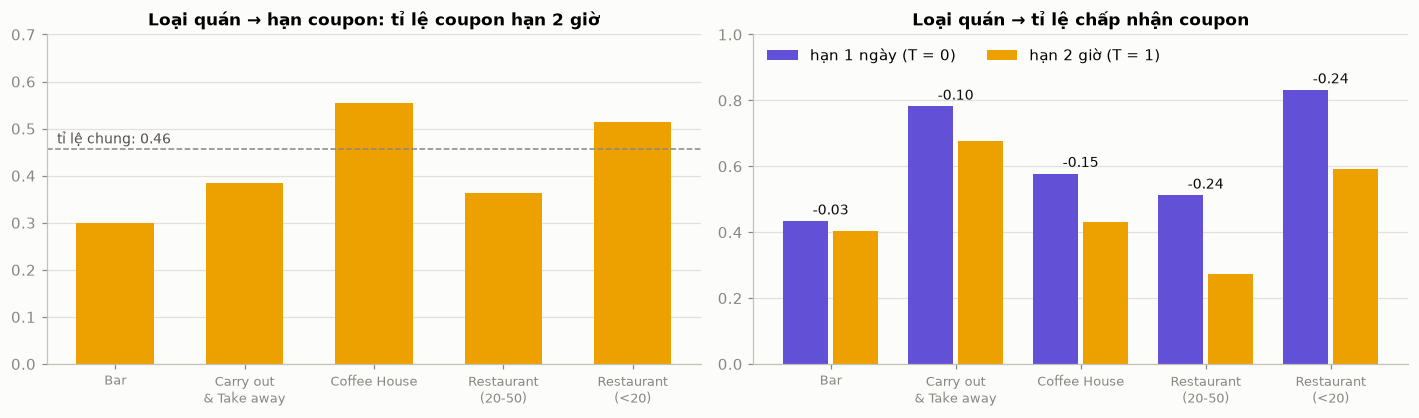

In [11]:
def group_table(data: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    """Chia dữ liệu thành các nhóm theo `by`; trong từng nhóm so sánh coupon 2 giờ với coupon 1 ngày.

    Tham số: data — bảng có cột T, Y và các cột trong `by`; by — danh sách biến dùng để chia nhóm.
    Trả về: bảng mỗi dòng một nhóm, gồm:
        n_1d, n_2h     số dòng hạn 1 ngày, hạn 2 giờ trong nhóm
        p_2h           tỉ lệ coupon hạn 2 giờ trong nhóm
        acc_1d, acc_2h tỉ lệ chấp nhận khi hạn 1 ngày, khi hạn 2 giờ
        diff           acc_2h − acc_1d (hiệu ứng của hạn coupon TRONG nhóm này)
        share          nhóm này chiếm bao nhiêu phần của dữ liệu
    """
    t = data.assign(y=as_int(data["Y"]))
    n = t.groupby(by + ["T"]).size().unstack("T", fill_value=0)       # đếm số dòng theo nhóm × T
    acc = t.groupby(by + ["T"])["y"].mean().unstack("T")              # tỉ lệ chấp nhận theo nhóm × T
    out = pd.DataFrame({"n_1d": n["0"], "n_2h": n["1"]})
    out["p_2h"] = out["n_2h"] / (out["n_1d"] + out["n_2h"])
    out["acc_1d"] = acc["0"]
    out["acc_2h"] = acc["1"]
    out["diff"] = out["acc_2h"] - out["acc_1d"]
    out["share"] = (out["n_1d"] + out["n_2h"]) / len(t)
    return out.reset_index()


def plot_by_coupon(table: pd.DataFrame) -> None:
    """Vẽ bảng theo loại quán thành hai hình cột: (trái) loại quán → hạn coupon, (phải) loại quán → tỉ lệ chấp nhận.

    Tham số: table — kết quả của group_table(data, ["coupon"]).
    """
    labels = [c.replace(" & ", "\n& ").replace("(", "\n(") for c in table["coupon"]]     # xuống dòng cho nhãn dài
    x = np.arange(len(table))
    overall_2h = table["n_2h"].sum() / (table["n_1d"].sum() + table["n_2h"].sum())
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.9))
    # Trái: trong mỗi loại quán, bao nhiêu phần coupon có hạn 2 giờ
    left.bar(x, table["p_2h"], width=0.6, color=ARM_COLOR["1"])
    left.axhline(overall_2h, color=MUTED, linewidth=1, linestyle="--")
    left.text(-0.45, overall_2h + 0.012, f"tỉ lệ chung: {overall_2h:.2f}", color=INK_SOFT, ha="left", fontsize=9)
    left.set_title("Loại quán → hạn coupon: tỉ lệ coupon hạn 2 giờ")
    left.set_ylim(0, 0.7)
    # Phải: tỉ lệ chấp nhận theo loại quán, tách theo hạn; con số trên mỗi cặp cột là chênh lệch (2 giờ − 1 ngày)
    right.bar(x - 0.2, table["acc_1d"], width=0.36, color=ARM_COLOR["0"], label=ARM_LABEL["0"])
    right.bar(x + 0.2, table["acc_2h"], width=0.36, color=ARM_COLOR["1"], label=ARM_LABEL["1"])
    for i, row in table.reset_index(drop=True).iterrows():
        right.text(i, max(row["acc_1d"], row["acc_2h"]) + 0.02, f"{row['diff']:+.2f}", color=INK, ha="center", fontsize=9)
    right.set_title("Loại quán → tỉ lệ chấp nhận coupon")
    right.set_ylim(0, 1.0)
    right.legend(loc="upper left", ncol=2)
    for ax in (left, right):
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=8.5)
        ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(OUT / "confounding_by_coupon.png")


BY_COUPON = group_table(train0, ["coupon"])
plot_by_coupon(BY_COUPON)
BY_COUPON.round(3)

**Kết quả.**

- *Hình trái:* tỉ lệ coupon hạn 2 giờ thay đổi mạnh theo loại quán, từ 30% (Bar) đến 56% (Coffee House). Vậy loại quán ảnh hưởng đến T.
- *Hình phải:* tỉ lệ chấp nhận cũng thay đổi mạnh theo loại quán. Với hạn 1 ngày: 43% ở Bar, 83% ở Restaurant(<20). Vậy loại quán ảnh hưởng đến Y.
- Loại quán ảnh hưởng cả T lẫn Y nên là **confounder**. Trong DAG, nó tạo ra backdoor path T ← coupon → Y.
- Con số trên mỗi cặp cột là `diff` (2 giờ trừ 1 ngày) **trong cùng một loại quán**. Nó âm ở cả 5 loại quán, từ −0,03 (Bar) đến −0,24 (hai loại nhà hàng).

### 5.3 Điều chỉnh bằng tay

**Ý tưởng.** So sánh 2 giờ với 1 ngày **trong cùng một loại quán** (cột `diff`), khi đó loại quán không còn là confounder. Rồi gộp các loại quán lại theo tỉ trọng của chúng (cột `share`):

$$\text{ATE (điều chỉnh theo coupon)} = \sum_{c} P(\text{coupon}=c)\,\big[P(Y{=}1 \mid T{=}1, c) - P(Y{=}1 \mid T{=}0, c)\big]$$

Đây chính là **công thức điều chỉnh backdoor** ở dạng đơn giản nhất. Ba mô hình B0, H1, H2 làm đúng việc này, chỉ khác là điều chỉnh theo nhiều biến cùng lúc và dùng mô hình để tính xác suất trong từng nhóm.

Thử thêm một bước: điều chỉnh theo cả `coupon` lẫn `destination`. Bảng thứ hai cũng là **kiểm tra overlap**: mỗi nhóm phải có đủ cả coupon 2 giờ lẫn coupon 1 ngày (cột `n_1d`, `n_2h`).

In [12]:
ate_by_coupon = float((BY_COUPON["diff"] * BY_COUPON["share"]).sum())
BY_COUPON_DEST = group_table(train0, ["coupon", "destination"])
ate_by_coupon_dest = float((BY_COUPON_DEST["diff"] * BY_COUPON_DEST["share"]).sum())
smallest_arm = int(BY_COUPON_DEST[["n_1d", "n_2h"]].min().min())
print(f"Hiệu thô:                                   {NAIVE0['diff']:+.4f}")
print(f"Điều chỉnh theo coupon:                     {ate_by_coupon:+.4f}")
print(f"Điều chỉnh theo coupon và destination:      {ate_by_coupon_dest:+.4f}")
print(f"Overlap: {len(BY_COUPON_DEST)} nhóm coupon × destination, nhóm nhỏ nhất của một loại hạn có {smallest_arm} dòng.")
BY_COUPON_DEST.round(3)

Hiệu thô:                                   -0.1468
Điều chỉnh theo coupon:                     -0.1563
Điều chỉnh theo coupon và destination:      -0.1589
Overlap: 14 nhóm coupon × destination, nhóm nhỏ nhất của một loại hạn có 100 dòng.


,coupon,destination,n_1d,n_2h,p_2h,acc_1d,acc_2h,diff,share
0,Bar,Home,243,102,0.296,0.506,0.363,-0.143,0.041
1,Bar,No Urgent Place,490,210,0.300,0.398,0.424,0.026,0.083
2,Carry out & Take away,Home,312,152,0.328,0.804,0.776,-0.028,0.055
3,Carry out & Take away,No Urgent Place,353,297,0.457,0.827,0.704,-0.123,0.077
4,Carry out & Take away,Work,354,186,0.344,0.718,0.554,-0.164,0.064
5,Coffee House,Home,301,342,0.532,0.445,0.269,-0.176,0.077
6,Coffee House,No Urgent Place,686,773,0.530,0.638,0.534,-0.104,0.174
7,Coffee House,Work,236,410,0.635,0.572,0.376,-0.196,0.077
8,Restaurant(20-50),Home,322,133,0.292,0.491,0.226,-0.265,0.054
9,Restaurant(20-50),No Urgent Place,142,139,0.495,0.585,0.388,-0.196,0.033


**Kết quả.**

- Hiệu thô là −0,147. Điều chỉnh theo loại quán cho −0,156, thêm điểm đến cho −0,159. Hiệu ứng **âm hơn** sau khi điều chỉnh, tức so sánh thô đã đánh giá nhẹ tác động của hạn 2 giờ.
- Lý do đọc được từ bảng ở 5.2: coupon hạn 1 ngày chiếm phần lớn ở Bar và Restaurant(20-50) (cột `p_2h` thấp), hai loại quán vốn ít được chấp nhận. Nhóm 1 ngày vì thế trông kém hơn thực chất, và khoảng cách thô bị thu hẹp.
- Overlap đạt: cả 14 nhóm loại quán × điểm đến đều có ít nhất 100 dòng cho mỗi loại hạn. Chỉ có 14 nhóm chứ không phải 15 vì nhóm Bar × Work đã bị loại ở mục 3.4.
- Cột `diff` âm ở 13/14 nhóm; riêng Bar × No Urgent Place xấp xỉ 0 (+0,026).

Các mô hình ở mục 8–10 sẽ cho ATE từ −0,14 đến −0,17 trên seed này, cùng cỡ với phép tính tay. Đây là một phép kiểm tra chéo hữu ích: mô hình phức tạp không nên cho kết quả khác xa một phép tính đơn giản mà ta hiểu rõ.

### 5.4 Hạn coupon phụ thuộc biến nào?

Kiểm tra giả định G1 bằng **kiểm định chi-square**: với từng biến, hỏi "tỉ lệ coupon 2 giờ có khác nhau giữa các mức của biến này không?". Cách đọc: `p-value` nhỏ (dưới 0,05) nghĩa là có liên hệ với T; `biên độ` = chênh lệch lớn nhất của tỉ lệ coupon 2 giờ giữa các mức.

In [13]:
def t_dependence_table(train: pd.DataFrame) -> pd.DataFrame:
    """Với từng biến nền: T (hạn coupon) có liên hệ với biến đó không?

    Tham số: train — tập TRAIN.
    Trả về: bảng mỗi dòng một biến, gồm p-value của kiểm định chi-square và biên độ của P(T = 1) giữa các mức.
    """
    rows = []
    for col in COVARIATES:
        crosstab = pd.crosstab(train[col], train["T"])              # bảng đếm: mức của biến × T
        chi2, p_value, _, _ = st.chi2_contingency(crosstab)
        p_2h = train.assign(t=as_int(train["T"])).groupby(col)["t"].mean()   # tỉ lệ coupon 2 giờ ở từng mức
        rows.append({"biến": col, "tầng": "người trả lời" if col in RESP else "kịch bản", "p-value": p_value,
                     "P(T=1) thấp nhất": p_2h.min(), "P(T=1) cao nhất": p_2h.max(), "biên độ": p_2h.max() - p_2h.min()})
    return pd.DataFrame(rows).sort_values(["tầng", "biên độ"], ascending=[True, False]).reset_index(drop=True)


def format_p_value(p: float) -> str:
    """Viết p-value cho dễ đọc: rất nhỏ thì ghi "< 0.001", còn lại ghi 3 chữ số thập phân.

    Tham số: p — p-value.
    Trả về: chuỗi để hiển thị, ví dụ "< 0.001" hoặc "0.030".
    """
    if p < 0.001:
        return "< 0.001"
    return f"{p:.3f}"


TDEP = t_dependence_table(train0)
TDEP.style.format({"p-value": format_p_value, "P(T=1) thấp nhất": "{:.3f}", "P(T=1) cao nhất": "{:.3f}", "biên độ": "{:.3f}"})

,biến,tầng,p-value,P(T=1) thấp nhất,P(T=1) cao nhất,biên độ
0,coupon,kịch bản,< 0.001,0.299,0.555,0.256
1,weather,kịch bản,< 0.001,0.301,0.540,0.239
2,time_bin,kịch bản,< 0.001,0.349,0.495,0.145
3,passenger,kịch bản,< 0.001,0.418,0.529,0.111
4,dist,kịch bản,< 0.001,0.413,0.517,0.105
5,direction_same,kịch bản,< 0.001,0.447,0.491,0.044
6,destination,kịch bản,0.030,0.435,0.469,0.034
7,age_bin,người trả lời,0.179,0.447,0.475,0.028
8,habit_match,người trả lời,0.123,0.443,0.467,0.024
9,income_bin,người trả lời,0.338,0.447,0.464,0.018


**Kết quả.** Cả 7 biến kịch bản đều liên hệ với T (p-value dưới 0,05). Mạnh nhất là loại quán: tỉ lệ coupon 2 giờ chênh nhau tới 0,26 giữa các loại quán. Cả 5 biến của người trả lời đều **không** cho thấy liên hệ với T (p-value trên 0,05, biên độ dưới 0,03). Dữ liệu vì thế phù hợp với giả định G1: hạn coupon được gán theo kịch bản chứ không theo người. Đây là cơ sở của luật 8 ở mục 6. Lưu ý: kiểm định chi-square coi các dòng là độc lập, trong khi mỗi người trả lời nhiều dòng, nên p-value ở đây chỉ để tham khảo.

<a id="6"></a>
## 6. Ràng buộc DAG

**Mục tiêu.** Viết ra, cho **từng nút**, những nút nào được phép trỏ vào nó (*parents được phép*) và vì sao; mọi mũi tên khác đều bị cấm. Sau đó viết một hàm kiểm tra tự động cho mọi DAG mà thuật toán sinh ra.

**Ý tưởng.** Thuật toán học DAG chỉ nhìn số liệu. Khi hai biến có liên hệ, số liệu **không** cho biết mũi tên đi chiều nào, nên thuật toán có thể vẽ "hành khách → thời tiết" (chở bạn làm trời mưa) hay "có con → tuổi", vô lý. Ta đưa hiểu biết của mình vào bằng một câu hỏi cho từng cặp nút: *nếu tự tay đổi A thì B có đổi theo không?* Nếu chắc chắn không, cấm mũi tên A → B.

Ba loại lý do được dùng:

- **Nút gốc (ngoại sinh):** không biến nào trong bài làm đổi được thời tiết, tuổi hay giới tính, nên ba nút này không nhận mũi tên nào. Chúng vẫn được trỏ **đi**.
- **Thứ tự thời gian:** cái có sau không gây ra cái có trước. Tình huống lái xe có trước coupon, coupon có trước hạn dùng T, T có trước câu trả lời Y.
- **Cách dữ liệu được tạo:** tình huống và coupon do bảng hỏi đưa ra, không do người trả lời chọn; `habit_match` được **tính từ** loại quán của coupon (mục 3.3).

Lưu ý: "nút gốc" khác với "biến can thiệp được". Yêu cầu can thiệp được chỉ áp cho treatment T (mục 2). Thời tiết không can thiệp được nên không thể làm treatment, nhưng nó vẫn có thể là **nguyên nhân** của biến khác.

Ô code dưới đây khai báo bộ luật trong danh sách `RULES` và in ra **bảng lý do**. Luật 1–9 nói mỗi nút được nhận mũi tên từ đâu; luật 10 và 11 là hai yêu cầu chung cho cả đồ thị.

In [14]:
# Mỗi luật là một dict: áp cho những nút nào, các nút đó ĐƯỢC PHÉP nhận mũi tên từ đâu, vì sao, và ví dụ cạnh bị cấm.
# Nút nào không có trong "parents" thì bị cấm trỏ vào các nút của luật đó.
RULES: list[dict] = [
    {"luật": 1, "nút": ["weather", "age_bin", "gender"], "parents": [],
     "lý do": "Nút gốc (ngoại sinh): không biến nào trong bài làm đổi được thời tiết, tuổi hay giới tính.",
     "ví dụ cạnh bị cấm": "passenger → weather; has_children → age_bin"},
    {"luật": 2, "nút": ["has_children", "income_bin"], "parents": ["age_bin", "gender", "has_children", "income_bin"],
     "lý do": "Có con và thu nhập có thể phụ thuộc tuổi, giới tính; giữa hai biến này chiều nào cũng có lý nên để thuật toán chọn. "
              "Một tình huống lái xe giả định không làm đổi hoàn cảnh của người trả lời.",
     "ví dụ cạnh bị cấm": "habit_match → income_bin; coupon → has_children"},
    {"luật": 3, "nút": ["time_bin", "destination"], "parents": ["weather", "time_bin", "destination", "passenger"],
     "lý do": "Bối cảnh chuyến đi (mấy giờ, đi đâu, chở ai) có trước coupon và có thể phụ thuộc thời tiết. "
              "Coupon và quãng đường tới quán không quyết định ngược lại chuyến đi.",
     "ví dụ cạnh bị cấm": "coupon → time_bin; dist → destination"},
    {"luật": 4, "nút": ["passenger"], "parents": ["weather", "time_bin", "destination", "has_children"],
     "lý do": "Như luật 3, thêm has_children: hành khách là trẻ em (Kid(s)) gần như chỉ xuất hiện ở người có con.",
     "ví dụ cạnh bị cấm": "dist → passenger; gender → passenger"},
    {"luật": 5, "nút": ["coupon"], "parents": ["weather", "time_bin", "destination", "passenger"],
     "lý do": "Coupon hiện ra trong một tình huống đã có sẵn và do bảng hỏi đưa ra, không do người trả lời chọn.",
     "ví dụ cạnh bị cấm": "habit_match → coupon; direction_same → coupon"},
    {"luật": 6, "nút": ["habit_match"], "parents": ["age_bin", "gender", "income_bin", "has_children", "coupon"],
     "lý do": "habit_match là tần suất người đó đến ĐÚNG loại quán của coupon (mục 3.3), nên nó phụ thuộc loại quán và đặc điểm của người, "
              "không phụ thuộc thời tiết hay chuyến đi.",
     "ví dụ cạnh bị cấm": "weather → habit_match; time_bin → habit_match"},
    {"luật": 7, "nút": ["dist", "direction_same"], "parents": ["weather", "time_bin", "destination", "coupon", "dist", "direction_same"],
     "lý do": "Quãng đường và hướng tới quán do điểm đến và quán của coupon quyết định; thời tiết và giờ giấc có thể làm đổi thời gian lái xe.",
     "ví dụ cạnh bị cấm": "passenger → dist; habit_match → direction_same"},
    {"luật": 8, "nút": ["T"], "parents": SCEN,
     "lý do": "Hạn coupon do bảng hỏi gán theo kịch bản, không theo người trả lời (giả định G1, đã kiểm ở mục 5.4).",
     "ví dụ cạnh bị cấm": "gender → T; habit_match → T"},
    {"luật": 9, "nút": ["Y"], "parents": COVARIATES + ["T"],
     "lý do": "Câu trả lời đến sau cùng nên mọi biến đều có thể ảnh hưởng đến nó. Y không nằm trong parents của nút nào, nên Y không trỏ đi đâu.",
     "ví dụ cạnh bị cấm": "(không cấm cạnh nào đi vào Y)"},
]
REQUIRED: list[tuple[str, str]] = [("T", "Y")]                       # luật 10: cạnh bắt buộc


def allowed_parents() -> dict[str, list[str]]:
    """Đổi RULES thành dict {nút: các nút được phép trỏ vào nó}.

    Trả về: dict có đủ 14 nút; một nút không bao giờ là parent của chính nó.
    """
    allowed = {}
    for rule in RULES:
        for node in rule["nút"]:
            allowed[node] = [p for p in rule["parents"] if p != node]
    return allowed


def rules_table() -> pd.DataFrame:
    """Lập bảng lý do của bộ luật, mỗi dòng một luật.

    Trả về: bảng gồm số luật, nút áp dụng, parents được phép, số mũi tên bị cấm, ví dụ cạnh bị cấm và lý do.
    """
    rows = []
    for rule in RULES:
        n_banned = 0
        for node in rule["nút"]:                                     # mỗi nút có 13 nút khác; trừ đi số parents được phép
            n_banned += len(NODES) - 1 - len(ALLOWED_PARENTS[node])
        rows.append({"luật": rule["luật"], "áp cho nút": ", ".join(rule["nút"]),
                     "parents được phép": ", ".join(rule["parents"]) if rule["parents"] else "(không có)",
                     "số cạnh bị cấm": n_banned, "ví dụ cạnh bị cấm": rule["ví dụ cạnh bị cấm"], "lý do": rule["lý do"]})
    rows.append({"luật": 10, "áp cho nút": "T, Y", "parents được phép": "bắt buộc có T → Y", "số cạnh bị cấm": 0,
                 "ví dụ cạnh bị cấm": "(DAG thiếu cạnh T → Y)",
                 "lý do": "Câu hỏi của bài là T ảnh hưởng Y bao nhiêu; thiếu cạnh này thì mô hình mặc định hiệu ứng bằng 0."})
    rows.append({"luật": 11, "áp cho nút": "mọi nút", "parents được phép": "không tạo vòng kín", "số cạnh bị cấm": 0,
                 "ví dụ cạnh bị cấm": "time_bin → destination → time_bin", "lý do": "Định nghĩa của DAG."})
    return pd.DataFrame(rows)


ALLOWED_PARENTS: dict[str, list[str]] = allowed_parents()
RULE_OF: dict[str, int] = {node: rule["luật"] for rule in RULES for node in rule["nút"]}       # nút → số của luật quản nút đó
assert sorted(ALLOWED_PARENTS) == sorted(NODES), "mỗi nút phải thuộc đúng một luật"

RULES_TABLE = rules_table()
RULES_TABLE.to_csv(OUT / "rules_table.csv", index=False)
print(f"Tổng số mũi tên bị cấm: {RULES_TABLE['số cạnh bị cấm'].sum()} trên {len(NODES) * (len(NODES) - 1)} mũi tên có thể vẽ giữa 14 nút.")
RULES_TABLE.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal", "vertical-align": "top"})

Tổng số mũi tên bị cấm: 127 trên 182 mũi tên có thể vẽ giữa 14 nút.


luật,áp cho nút,parents được phép,số cạnh bị cấm,ví dụ cạnh bị cấm,lý do
1,"weather, age_bin, gender",(không có),39,passenger → weather; has_children → age_bin,"Nút gốc (ngoại sinh): không biến nào trong bài làm đổi được thời tiết, tuổi hay giới tính."
2,"has_children, income_bin","age_bin, gender, has_children, income_bin",20,habit_match → income_bin; coupon → has_children,"Có con và thu nhập có thể phụ thuộc tuổi, giới tính; giữa hai biến này chiều nào cũng có lý nên để thuật toán chọn. Một tình huống lái xe giả định không làm đổi hoàn cảnh của người trả lời."
3,"time_bin, destination","weather, time_bin, destination, passenger",20,coupon → time_bin; dist → destination,"Bối cảnh chuyến đi (mấy giờ, đi đâu, chở ai) có trước coupon và có thể phụ thuộc thời tiết. Coupon và quãng đường tới quán không quyết định ngược lại chuyến đi."
4,passenger,"weather, time_bin, destination, has_children",9,dist → passenger; gender → passenger,"Như luật 3, thêm has_children: hành khách là trẻ em (Kid(s)) gần như chỉ xuất hiện ở người có con."
5,coupon,"weather, time_bin, destination, passenger",9,habit_match → coupon; direction_same → coupon,"Coupon hiện ra trong một tình huống đã có sẵn và do bảng hỏi đưa ra, không do người trả lời chọn."
6,habit_match,"age_bin, gender, income_bin, has_children, coupon",8,weather → habit_match; time_bin → habit_match,"habit_match là tần suất người đó đến ĐÚNG loại quán của coupon (mục 3.3), nên nó phụ thuộc loại quán và đặc điểm của người, không phụ thuộc thời tiết hay chuyến đi."
7,"dist, direction_same","weather, time_bin, destination, coupon, dist, direction_same",16,passenger → dist; habit_match → direction_same,Quãng đường và hướng tới quán do điểm đến và quán của coupon quyết định; thời tiết và giờ giấc có thể làm đổi thời gian lái xe.
8,T,"coupon, destination, time_bin, passenger, weather, dist, direction_same",6,gender → T; habit_match → T,"Hạn coupon do bảng hỏi gán theo kịch bản, không theo người trả lời (giả định G1, đã kiểm ở mục 5.4)."
9,Y,"habit_match, age_bin, income_bin, gender, has_children, coupon, destination, time_bin, passenger, weather, dist, direction_same, T",0,(không cấm cạnh nào đi vào Y),"Câu trả lời đến sau cùng nên mọi biến đều có thể ảnh hưởng đến nó. Y không nằm trong parents của nút nào, nên Y không trỏ đi đâu."
10,"T, Y",bắt buộc có T → Y,0,(DAG thiếu cạnh T → Y),Câu hỏi của bài là T ảnh hưởng Y bao nhiêu; thiếu cạnh này thì mô hình mặc định hiệu ứng bằng 0.


**Cách đọc bảng.** Mỗi dòng trả lời ba câu hỏi: luật áp cho nút nào, nút đó được nhận mũi tên từ đâu, và vì sao. Cột `số cạnh bị cấm` đếm số mũi tên đi **vào** các nút của luật mà bị loại. Ví dụ luật 1: ba nút gốc, mỗi nút có 13 nút khác có thể trỏ vào, không nút nào được phép, nên cấm 3 × 13 = 39 mũi tên.

Ba luật (4, 5, 6) dựa vào cách dữ liệu được tạo, nên ô dưới đây kiểm lại bằng số liệu: người trả lời có thật sự **không liên hệ** với tình huống mà bảng hỏi đưa ra không? Thước đo là **Cramér's V**: 0 nghĩa là hai biến độc lập, 1 nghĩa là biết biến này thì biết chắc biến kia.

In [15]:
def cramers_v(data: pd.DataFrame, a: str, b: str) -> float:
    """Độ mạnh liên hệ giữa hai biến phân loại (Cramér's V), tính từ thống kê chi-square.

    Tham số: data — bảng dữ liệu; a, b — tên hai cột.
    Trả về: một số từ 0 (độc lập) đến 1 (biến này quyết định hoàn toàn biến kia).
    """
    crosstab = pd.crosstab(data[a], data[b])                         # bảng đếm: mức của a × mức của b
    chi2 = st.chi2_contingency(crosstab)[0]
    return float(np.sqrt(chi2 / (len(data) * (min(crosstab.shape) - 1))))


def association_table(data: pd.DataFrame, row_vars: list[str], col_vars: list[str]) -> pd.DataFrame:
    """Bảng Cramér's V giữa hai nhóm biến.

    Tham số: data — bảng dữ liệu; row_vars — các biến làm dòng; col_vars — các biến làm cột.
    Trả về: bảng số, ô [r, c] là Cramér's V giữa biến r và biến c.
    """
    table = pd.DataFrame(index=row_vars, columns=col_vars, dtype=float)
    for r in row_vars:
        for c in col_vars:
            table.loc[r, c] = cramers_v(data, r, c)
    return table


print("Cramér's V giữa biến của người trả lời (dòng) và biến kịch bản (cột), trên TRAIN của seed 0:")
display(association_table(train0, RESP, SCEN).round(3))
print("Tỉ lệ từng loại hành khách, tách theo người trả lời có con (1) hay không (0):")
display(pd.crosstab(train0["has_children"], train0["passenger"], normalize="index").round(3))

Cramér's V giữa biến của người trả lời (dòng) và biến kịch bản (cột), trên TRAIN của seed 0:


,coupon,destination,time_bin,passenger,weather,dist,direction_same
habit_match,0.318,0.047,0.026,0.051,0.023,0.019,0.051
age_bin,0.017,0.027,0.018,0.088,0.035,0.033,0.037
income_bin,0.027,0.014,0.023,0.072,0.030,0.022,0.015
gender,0.016,0.005,0.005,0.040,0.026,0.004,0.001
has_children,0.044,0.035,0.034,0.367,0.022,0.092,0.037


Tỉ lệ từng loại hành khách, tách theo người trả lời có con (1) hay không (0):


passenger,Alone,Friend(s),Kid(s),Partner
has_children,,,,
0,0.592,0.286,0.001,0.121
1,0.529,0.242,0.194,0.035


**Cách đọc kết quả.**

- Hầu hết các ô dưới 0,06: đặc điểm của người trả lời gần như không liên hệ với tình huống được đưa ra. Số liệu khớp với ý "tình huống và coupon do bảng hỏi đưa ra, không do người chọn", là cơ sở để các luật 3, 5 và 7 không nhận mũi tên từ người trả lời.
- Hai ngoại lệ rõ ràng, và bộ luật dành riêng cho mỗi ngoại lệ một cạnh được phép. `habit_match` với `coupon` (0,318): `habit_match` được tính từ loại quán của coupon, nên luật 6 cho phép `coupon → habit_match`. `has_children` với `passenger` (0,367): hành khách Kid(s) chiếm 19,4% số dòng của người có con nhưng chỉ 0,1% ở người không có con, nên luật 4 cho phép `has_children → passenger`.
- Vài ô ở mức 0,07–0,09 (`age_bin` và `income_bin` với `passenger`, `has_children` với `dist`) nhỏ hơn hẳn hai ngoại lệ trên. Bộ luật không cho chúng cạnh trực tiếp, nhưng chúng vẫn có đường gián tiếp đi qua `has_children → passenger`.
- Như ở mục 5.4, chi-square coi các dòng là độc lập trong khi mỗi người trả lời nhiều dòng, nên các con số này chỉ để tham khảo.

Từ `RULES` suy ra ba thứ dùng cho phần còn lại của bài: danh sách cạnh cấm `FORBIDDEN` (cho `pgmpy`), ma trận `MASK` (cho neural network) và hàm kiểm tra `check_dag`.

In [16]:
def forbidden_edges() -> list[tuple[str, str]]:
    """Liệt kê mọi mũi tên bị cấm: u → v bị cấm khi u không nằm trong parents được phép của v (luật 1–9).

    Trả về: danh sách các cặp (nút đi, nút đến).
    """
    banned = []
    for u in NODES:
        for v in NODES:
            if u != v and u not in ALLOWED_PARENTS[v]:
                banned.append((u, v))
    return banned


FORBIDDEN: list[tuple[str, str]] = forbidden_edges()

# Thứ tự thời gian suy ra từ bộ luật: 6 lớp. Mũi tên được phép chỉ đi từ lớp trên xuống lớp dưới hoặc nằm trong cùng một lớp.
LAYERS: list[list[str]] = [
    ["age_bin", "gender", "weather"],                                        # lớp 0: nút gốc
    ["income_bin", "has_children", "passenger", "destination", "time_bin"],  # lớp 1: hoàn cảnh của người và của chuyến đi
    ["coupon"],                                                              # lớp 2: coupon hiện ra
    ["habit_match", "dist", "direction_same"],                               # lớp 3: các biến phụ thuộc vào coupon
    ["T"],                                                                   # lớp 4: hạn coupon
    ["Y"],                                                                   # lớp 5: câu trả lời
]
LAYER_OF: dict[str, int] = {n: k for k, layer in enumerate(LAYERS) for n in layer}       # nút → số thứ tự lớp (0..5)
for v in NODES:                                                              # kiểm tra: không luật nào cho phép mũi tên đi ngược lớp
    for p in ALLOWED_PARENTS[v]:
        assert LAYER_OF[p] <= LAYER_OF[v], f"{p} → {v} đi ngược lớp"

# ExpertKnowledge là cách pgmpy nhận "hiểu biết chuyên gia": cạnh cấm, cạnh bắt buộc, thứ tự thời gian
EXPERT = ExpertKnowledge(forbidden_edges=FORBIDDEN, required_edges=REQUIRED, temporal_order=LAYERS)


def allowed_mask() -> np.ndarray:
    """Tạo mask cho H2: ma trận 14 × 14 gồm 0 và 1.

    Quy ước: MASK[i, j] = 1 nếu mũi tên NODES[i] → NODES[j] được phép, = 0 nếu bị cấm (đường chéo luôn = 0).
    Trả về: mảng numpy 14 × 14.
    """
    banned = set(FORBIDDEN)
    mask = np.ones((len(NODES), len(NODES)), dtype=np.float32)
    for i, u in enumerate(NODES):
        for j, v in enumerate(NODES):
            if i == j or (u, v) in banned:
                mask[i, j] = 0.0
    return mask


MASK = allowed_mask()


def check_dag(edges: list[tuple[str, str]]) -> list[str]:
    """Kiểm tra một DAG theo 11 luật ở trên.

    Tham số: edges — danh sách mũi tên (nút đi, nút đến).
    Trả về: danh sách các lỗi tìm thấy (mỗi lỗi một câu). Danh sách RỖNG nghĩa là DAG hợp lệ.
    """
    graph = nx.DiGraph(edges)
    graph.add_nodes_from(NODES)
    problems = []
    for u, v in graph.edges():
        if u not in ALLOWED_PARENTS[v]:                    # luật 1–9: u không được phép trỏ vào v
            problems.append(f"luật {RULE_OF[v]}: {u} → {v} bị cấm ({v} không được nhận mũi tên từ {u})")
    for u, v in REQUIRED:
        if not graph.has_edge(u, v):
            problems.append(f"luật 10: thiếu cạnh bắt buộc {u} → {v}")
    if not nx.is_directed_acyclic_graph(graph):
        problems.append("luật 11: đồ thị có vòng kín")
    return problems


print(f"Có {len(NODES) * (len(NODES) - 1)} mũi tên có thể vẽ giữa 14 nút; {len(FORBIDDEN)} bị cấm, còn {int(MASK.sum())} được phép.")
print("Thử một DAG tốt :", check_dag([("weather", "coupon"), ("coupon", "habit_match"), ("coupon", "T"), ("T", "Y"), ("coupon", "Y")]))
print("Thử một DAG lỗi :")
for problem in check_dag([("passenger", "weather"), ("habit_match", "coupon"), ("gender", "T"), ("Y", "dist")]):
    print("  -", problem)

Có 182 mũi tên có thể vẽ giữa 14 nút; 127 bị cấm, còn 55 được phép.
Thử một DAG tốt : []
Thử một DAG lỗi :
  - luật 1: passenger → weather bị cấm (weather không được nhận mũi tên từ passenger)
  - luật 5: habit_match → coupon bị cấm (coupon không được nhận mũi tên từ habit_match)
  - luật 8: gender → T bị cấm (T không được nhận mũi tên từ gender)
  - luật 7: Y → dist bị cấm (dist không được nhận mũi tên từ Y)
  - luật 10: thiếu cạnh bắt buộc T → Y


**Kết quả.** DAG tốt trả về danh sách rỗng `[]`. DAG lỗi trả về từng câu mô tả lỗi, kèm số của luật bị vi phạm. Từ đây về sau, mọi DAG phải qua `check_dag` trước khi được dùng.

Hàm vẽ dưới đây xếp nút theo 6 lớp của `LAYERS` (trên cùng là ba nút gốc, dưới cùng là Y) nên mũi tên hợp lệ luôn đi **xuống** hoặc đi **ngang**. Màu của nút vẫn theo 4 tầng ở mục 1.1.

In [17]:
def draw_dag(edges: list[tuple[str, str]], title: str) -> None:
    """Vẽ DAG với nút xếp theo 6 lớp của LAYERS, tô màu theo 4 tầng; mũi tên T → Y tô đỏ.

    Tham số: edges — danh sách mũi tên; title — tiêu đề hình.
    """
    graph = nx.DiGraph(edges)
    graph.add_nodes_from(NODES)
    # Toạ độ: mỗi lớp một hàng ngang; lớp 1 có 5 nút nên so le lên xuống cho đỡ chồng nhãn.
    # Hàng của coupon lệch sang trái, hàng của T lệch sang phải để mũi tên không chạy xuyên qua các nút nằm giữa.
    layer_shift = [0.0, 0.0, -1.1, 0.0, 1.1, 0.0]
    pos = {}
    for k, layer in enumerate(LAYERS):
        for i, node in enumerate(layer):
            x = (i - (len(layer) - 1) / 2) * 2.2 + layer_shift[k]
            y = (len(LAYERS) - 1 - k) * 1.5 + (0.5 if (k == 1 and i % 2) else 0)
            pos[node] = (x, y)
    tier_colors = ["#cfe2f3", "#fff2cc", "#f9cb9c", "#b6d7a8"]      # xanh: người; vàng: kịch bản; cam: T; lục: Y
    _, ax = plt.subplots(figsize=(13, 9.5))
    nx.draw_networkx_nodes(graph, pos, node_color=[tier_colors[TIER_OF[n]] for n in graph.nodes], node_size=2700, edgecolors="#444", ax=ax)
    nx.draw_networkx_labels(graph, pos, labels={n: n.replace("_", "\n") for n in graph.nodes}, font_size=8.5, ax=ax)
    other_edges = [e for e in graph.edges if e != ("T", "Y")]
    nx.draw_networkx_edges(graph, pos, edgelist=other_edges, arrowsize=14, node_size=2700, width=1.1, edge_color="#666",
                           connectionstyle="arc3,rad=0.12", ax=ax)
    if graph.has_edge("T", "Y"):
        nx.draw_networkx_edges(graph, pos, edgelist=[("T", "Y")], arrowsize=20, node_size=2700, width=3, edge_color="#e34948", ax=ax)
    ax.set_title(title)
    ax.axis("off")

<a id="7"></a>
## 7. Khảo sát thuật toán

**Mục tiêu.** Xem trong các thư viện phổ biến có những thuật toán nào cho hai việc: </br>
(1) tìm DAG (*học cấu trúc*) </br>
(2) điền CPD (*học tham số*); rồi chọn cái hợp với bài.

### 7.1 Học cấu trúc (tìm DAG)

| Nhóm | Thuật toán | Thư viện | Ý tưởng bằng lời thường | Nhận ràng buộc? | Dùng trong bài |
|---|---|---|---|---|---|
| Dựa trên điểm | Hill Climbing, Tabu | `pgmpy.HillClimbSearch`; bnlearn (R) `hc`, `tabu` | Bắt đầu từ đồ thị rỗng; mỗi bước thử thêm, bớt hoặc đảo một mũi tên, giữ thay đổi làm **điểm** tăng nhiều nhất; dừng khi hết cải thiện | có: `ExpertKnowledge` | **B0** (thử 3 hàm điểm) |
| Dựa trên điểm | GES | `pgmpy.GES`, causal-learn | Thêm cạnh tham lam rồi bớt cạnh tham lam | chưa nhận trong pgmpy 1.1 | không |
| Dựa trên kiểm định | PC | `pgmpy.PC`, causal-learn, bnlearn `pc.stable` | Bắt đầu từ đồ thị đầy đủ; xoá cạnh giữa hai biến nếu kiểm định thấy chúng độc lập (có điều kiện) | có | chạy thử ở mục 8.2 |
| Lai | MMHC | `pgmpy.MmhcEstimator`, bnlearn `mmhc` | Dùng kiểm định để khoanh vùng, rồi Hill Climbing trong vùng đó | hạn chế | không |
| Cây | Chow-Liu, TAN | `pgmpy.TreeSearch` | Chỉ cho phép đồ thị dạng cây | không | không (quá đơn giản) |
| Neural network | NOTEARS (tuyến tính, MLP), DAG-GNN, GOLEM, DAGMA | mã nguồn `xunzheng/notears`, `fishmoon1234/DAG-GNN`; hoặc tự cài bằng PyTorch | Biến bài toán "thử từng mũi tên" thành bài toán tối ưu liên tục: học trọng số, kèm một hình phạt bắt đồ thị không có vòng | qua mask | **H2** (NOTEARS-MLP) |

**Hàm điểm** là cách chấm một DAG: DAG khớp dữ liệu thì điểm cao, nhưng DAG nhiều mũi tên bị trừ điểm (để tránh vẽ thừa). BIC trừ điểm nặng tay nên cho DAG thưa; BDeu và K2 nhẹ tay hơn nên cho DAG dày hơn. Không biết trước cái nào hợp, nên mục 8.2 thử cả ba và để VALIDATION quyết định.

### 7.2 Học tham số (điền CPD)

| Phương pháp | Thư viện | Công thức cho một ô | Nhận xét |
|---|---|---|---|
| Maximum Likelihood (MLE) | `pgmpy.MaximumLikelihoodEstimator`; bnlearn `bn.fit(method="mle")` | số dòng có Y = 1 trong ô ÷ số dòng của ô | Ô có 3 dòng mà cả 3 đều nhận coupon thì cho xác suất 100%: quá tự tin. Ô không có dòng nào thì không tính được |
| Bayes có làm trơn: BDeu, K2, Dirichlet | `pgmpy.BayesianEstimator`; bnlearn `method="bayes"` | (số dòng Y = 1 + α) ÷ (số dòng của ô + 2α) | Cộng thêm α "dòng ảo" cho mỗi kết quả vào mỗi ô trước khi chia. Ô nhiều dữ liệu gần như không đổi; ô trống nhận xác suất 50% thay vì không tính được. **Dùng cho B0 và H2** |
| EM | `pgmpy.ExpectationMaximization` | lặp: đoán giá trị thiếu → ước lượng lại | Chỉ cần khi dữ liệu có ô trống; bài này không còn ô trống |
| Neural network | PyTorch, Keras | mạng nhận giá trị của parents, trả ra xác suất | Các ô "na ná nhau" chia sẻ thông tin cho nhau. **Dùng cho H1** |

Với BDeu, α = ESS ÷ (số mức của nút × số tổ hợp giá trị của parents). ESS (*equivalent sample size*) là tổng số dòng ảo chia đều cho cả bảng; bài này dùng ESS = 5, một mức làm trơn **rất nhẹ**: bảng càng nhiều ô thì mỗi ô càng nhận ít dòng ảo.

Ô code dưới đây định nghĩa các hàm fit dùng cho cả bài, rồi **tự tính tay** một CPD để thấy MLE và BDeu khác nhau ở đâu, và kiểm tra rằng tính tay trùng với `pgmpy`.
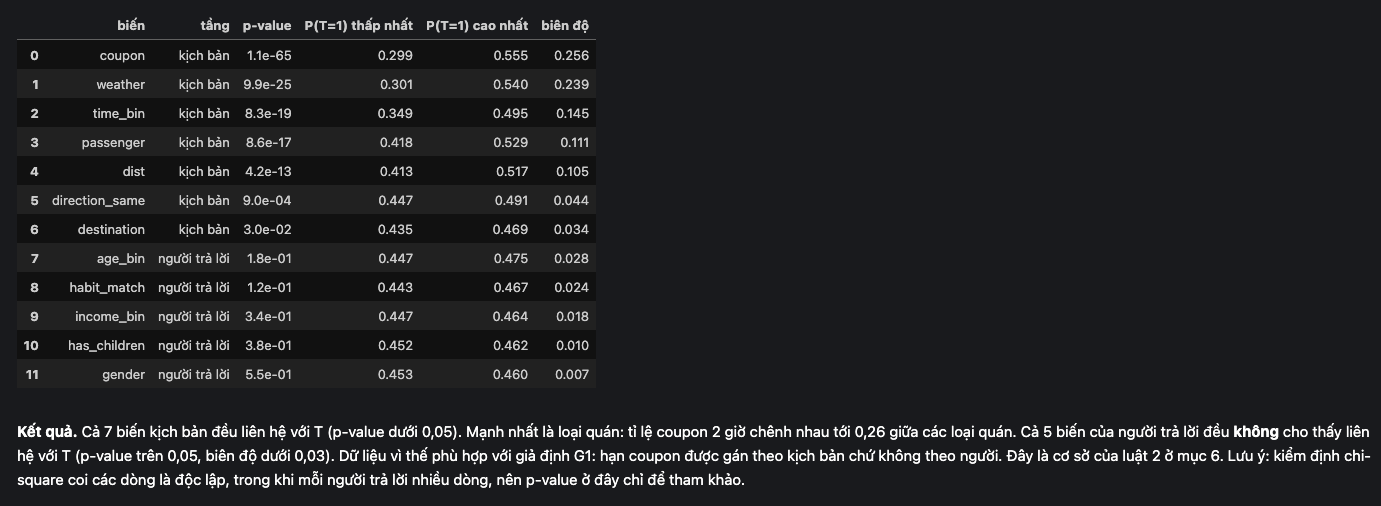

In [18]:
def fit_bn(edges: list[tuple[str, str]], data: pd.DataFrame) -> DiscreteBayesianNetwork:
    """Tạo mạng Bayes từ một DAG và điền mọi bảng xác suất bằng BDeu.

    Tham số: edges — các mũi tên của DAG; data — dữ liệu để đếm (luôn là TRAIN).
    Trả về: mạng Bayes đã có đủ bảng xác suất cho 14 nút, đã qua check_model() của pgmpy.
    """
    bn = DiscreteBayesianNetwork(edges)
    bn.add_nodes_from(NODES)                                  # nút không có mũi tên nào vẫn phải nằm trong mạng
    estimator = BayesianEstimator(bn, data[NODES], state_names=STATES)
    bn.add_cpds(*estimator.get_parameters(prior_type="BDeu", equivalent_sample_size=CFG.ess))
    assert bn.check_model()                                   # pgmpy tự kiểm: mỗi cột của mỗi bảng cộng lại bằng 1
    return bn


def cpd_to_frame(cpd: TabularCPD) -> pd.DataFrame:
    """Đổi một bảng xác suất của pgmpy thành bảng pandas dễ đọc.

    Tham số: cpd — bảng xác suất của một nút.
    Trả về: bảng mỗi dòng là một tổ hợp (giá trị của nút, giá trị của các cha), cột p là xác suất.
    """
    cols = list(cpd.variables)                                # nút đứng đầu, sau đó là các cha
    combos = list(itertools.product(*[cpd.state_names[v] for v in cols]))
    out = pd.DataFrame(combos, columns=cols)
    out["p"] = np.asarray(cpd.values, dtype=float).reshape(-1)
    return out


def cpd_to_y_table(cpd: TabularCPD) -> pd.DataFrame:
    """Rút gọn bảng xác suất của Y: chỉ giữ dòng Y = 1 (vì P(Y = 0) = 1 − P(Y = 1)).

    Tham số: cpd — bảng xác suất của nút Y.
    Trả về: "bảng Y": mỗi dòng là một tổ hợp giá trị của các cha của Y, cột p1 = xác suất chấp nhận coupon.
    """
    frame = cpd_to_frame(cpd)
    frame = frame[frame["Y"] == "1"].drop(columns="Y").rename(columns={"p": "p1"})
    return frame.reset_index(drop=True)


def y_table_of(bn: DiscreteBayesianNetwork) -> pd.DataFrame:
    """Lấy "bảng Y" = P(Y = 1 | cha của Y) của một mạng Bayes đã fit.

    Tham số: bn — mạng đã fit.
    Trả về: bảng gồm các cột cha của Y và cột p1.
    """
    return cpd_to_y_table(bn.get_cpds("Y"))


def cpd_by_hand(data: pd.DataFrame, parents: list[str]) -> pd.DataFrame:
    """Tự tính bảng P(Y = 1 | parents) bằng phép đếm, theo hai cách MLE và BDeu.

    Tham số: data — dữ liệu để đếm; parents — danh sách cha của Y.
    Trả về: bảng mỗi dòng là một ô (một tổ hợp giá trị của cha): n = số dòng, n1 = số dòng Y = 1, mle, bdeu.
    """
    cells = pd.DataFrame(list(itertools.product(*[STATES[p] for p in parents])), columns=parents)   # mọi ô có thể có
    counts = data.assign(y=as_int(data["Y"])).groupby(parents)["y"].agg(n="size", n1="sum").reset_index()
    out = cells.merge(counts, on=parents, how="left").fillna({"n": 0, "n1": 0})
    alpha = CFG.ess / (2 * len(cells))                        # số dòng ảo mỗi ô = ESS ÷ (2 mức của Y × số ô)
    out["mle"] = out["n1"] / out["n"]                         # ô trống → 0 ÷ 0 → NaN (không tính được)
    out["bdeu"] = (out["n1"] + alpha) / (out["n"] + 2 * alpha)
    return out


# Ví dụ 1: Y chỉ có 2 cha → 10 ô, ô nào cũng nhiều dữ liệu → MLE và BDeu gần như trùng nhau
HAND_SMALL = cpd_by_hand(train0, ["T", "coupon"])
bn_small = fit_bn([("T", "Y"), ("coupon", "Y")], train0)
check = HAND_SMALL.merge(y_table_of(bn_small), on=["T", "coupon"])
assert np.allclose(check["bdeu"], check["p1"]), "tính tay khác pgmpy"
print("Tính tay BDeu trùng khớp với pgmpy trên cả 10 ô.")
display(HAND_SMALL.round(4))

# Ví dụ 2: Y có 5 cha → 270 ô. Bảng hỏi không dùng mọi tổ hợp kịch bản, nên rất nhiều ô KHÔNG có dòng nào
HAND_BIG = cpd_by_hand(train0, ["T", "coupon", "destination", "time_bin", "weather"])
print(f"Với 5 cha: {len(HAND_BIG)} ô, trong đó {int((HAND_BIG['n'] == 0).sum())} ô trống và "
      f"{int(((HAND_BIG['n'] > 0) & (HAND_BIG['n'] < 20)).sum())} ô có dưới 20 dòng. Ba ô trống và năm ô ít dữ liệu nhất:")
pd.concat([HAND_BIG[HAND_BIG["n"] == 0].head(3), HAND_BIG[HAND_BIG["n"] > 0].sort_values("n").head(5)]).round(3)

Tính tay BDeu trùng khớp với pgmpy trên cả 10 ô.


,T,coupon,n,n1,mle,bdeu
0,0,Bar,733,318,0.4338,0.4339
1,0,Carry out & Take away,1019,797,0.7821,0.7820
2,0,Coffee House,1223,707,0.5781,0.5781
3,0,Restaurant(20-50),652,334,0.5123,0.5123
4,0,Restaurant(<20),934,777,0.8319,0.8317
5,1,Bar,312,126,0.4038,0.4040
6,1,Carry out & Take away,635,430,0.6772,0.6770
7,1,Coffee House,1525,659,0.4321,0.4322
8,1,Restaurant(20-50),372,102,0.2742,0.2745
9,1,Restaurant(<20),989,585,0.5915,0.5915


Với 5 cha: 270 ô, trong đó 189 ô trống và 8 ô có dưới 20 dòng. Ba ô trống và năm ô ít dữ liệu nhất:


,T,coupon,destination,time_bin,weather,n,n1,mle,bdeu
0,0,Bar,Home,afternoon,Rainy,0.0,0.0,NaN,0.500
1,0,Bar,Home,afternoon,Snowy,0.0,0.0,NaN,0.500
2,0,Bar,Home,afternoon,Sunny,0.0,0.0,NaN,0.500
269,1,Restaurant(<20),Work,morning,Sunny,4.0,1.0,0.250,0.251
39,0,Carry out & Take away,No Urgent Place,evening,Rainy,9.0,8.0,0.889,0.888
11,0,Bar,No Urgent Place,afternoon,Sunny,12.0,4.0,0.333,0.334
255,1,Restaurant(<20),No Urgent Place,evening,Rainy,13.0,9.0,0.692,0.692
105,0,Restaurant(20-50),Work,morning,Rainy,13.0,7.0,0.538,0.538


**Cách đọc kết quả.**

- *Bảng 10 ô:* ô nào cũng có hàng trăm dòng nên `mle` và `bdeu` chỉ khác nhau ở chữ số thứ tư. Khi dữ liệu nhiều, làm trơn gần như không có tác dụng.
- *Bảng 270 ô:* ở ô trống, MLE là `NaN` (chia 0 cho 0, không tính được) còn BDeu trả về 0,5, tức "không biết gì thì coi như năm ăn năm thua". Ở ô ít dữ liệu, hai cách vẫn gần nhau vì ESS = 5 là mức làm trơn rất nhẹ.
- *Bài học:* cho Y càng nhiều parents thì bảng càng nhiều ô, mỗi ô càng ít dữ liệu, và ô trống chỉ nhận con số 0,5 vô thưởng vô phạt. Đây là lý do H1 thử một neural network: mạng học quy luật chung nên đoán được cho cả những ô chưa từng thấy (mục 9).

=<a id="8"></a>
## 8. B0: DAG truyền thống

**Mục tiêu.** Xây mô hình gốc B0 và đi qua **toàn bộ** quy trình một lần, thật chậm, trên seed 0. H1 và H2 về sau dùng lại đúng các bước này.

| Bước | Việc | Câu hỏi được trả lời |
|---|---|---|
| 8.1 | Hill Climbing đề xuất vài DAG, VALIDATION chọn một | sơ đồ nhân quả trông thế nào? |
| 8.2 | Điền CPD | trong từng hoàn cảnh, xác suất chấp nhận coupon là bao nhiêu? |
| 8.3 | Hỏi DoWhy | với sơ đồ này, có tính được hiệu ứng nhân quả không, và phải điều chỉnh theo biến nào? |
| 8.4 | Dự đoán Y trên TEST | mô hình đoán giỏi đến đâu? (Bảng A) |
| 8.5 | Intervention do(T) | đổi hạn coupon thì tỉ lệ chấp nhận đổi bao nhiêu? (Bảng B) |

### 8.1 Học DAG

**Ý tưởng.** Hill Climbing giống như leo đồi trong sương mù: đứng ở một DAG, thử mọi thay đổi nhỏ (thêm, bớt, đảo một mũi tên), bước sang DAG có **điểm** cao nhất, lặp lại đến khi không còn bước nào đi lên. Ràng buộc ở mục 6 được truyền vào qua `expert_knowledge`, nên thuật toán không bao giờ thử các mũi tên bị cấm.

Ta chưa biết hàm điểm nào và giới hạn số parents nào hợp với dữ liệu, nên cho chạy 6 cấu hình (3 hàm điểm × 2 giới hạn số parents) và để **VALIDATION** chọn:

1. tiêu chí chính: **log-loss của Y** trên VALIDATION, càng thấp càng tốt (DAG nào cho Y parent set dự đoán Y tốt nhất);
2. nếu hoà: **log-likelihood của cả mạng** trên VALIDATION, càng cao càng tốt (DAG nào mô tả toàn bộ 14 biến tốt nhất).

*Log-loss* là điểm phạt cho dự đoán xác suất: đoán 90% mà đúng thì phạt ít, đoán 90% mà sai thì phạt nặng. Số càng nhỏ càng tốt.

In [19]:
def log_likelihood(bn: DiscreteBayesianNetwork, data: pd.DataFrame) -> float:
    """Độ khớp của CẢ mạng với dữ liệu: trung bình mỗi dòng của log(xác suất mạng gán cho dòng đó).

    Tham số: bn — mạng đã fit; data — dữ liệu để chấm.
    Trả về: một số âm; càng gần 0 thì mạng mô tả dữ liệu càng tốt.
    """
    total = 0.0
    for node in NODES:                                     # xác suất của một dòng = tích xác suất của từng nút → log thì thành tổng
        frame = cpd_to_frame(bn.get_cpds(node))
        cols = [c for c in frame.columns if c != "p"]      # nút đó và các cha của nó
        p = data[cols].merge(frame, on=cols, how="left")["p"].to_numpy()     # tra bảng xác suất cho từng dòng
        total += np.log(np.clip(p, 1e-12, None)).sum()
    return float(total / len(data))


def predict_y(y_table: pd.DataFrame, data: pd.DataFrame) -> np.ndarray:
    """Dự đoán P(Y = 1) cho từng dòng bằng cách TRA "bảng Y".

    Tham số: y_table — bảng gồm các cột cha của Y và cột p1; data — bảng có đủ các cột cha của Y.
    Trả về: mảng xác suất, mỗi dòng của data một số.
    """
    parents = [c for c in y_table.columns if c != "p1"]
    merged = data[parents].merge(y_table, on=parents, how="left")       # ghép theo giá trị của các cha
    assert merged["p1"].notna().all(), "có tổ hợp giá trị của cha không có trong bảng"
    return merged["p1"].to_numpy()


def hc_candidates(train: pd.DataFrame) -> dict[str, list[tuple[str, str]]]:
    """Chạy Hill Climbing với từng cặp (hàm điểm, số cha tối đa) trong Config.

    Tham số: train — tập TRAIN.
    Trả về: dict {tên cấu hình: danh sách mũi tên của DAG tìm được}.
    """
    candidates = {}
    for score in CFG.b0_scores:
        for max_parents in CFG.b0_max_indegree:
            dag = HillClimbSearch(train[NODES]).estimate(scoring_method=score, max_indegree=max_parents,
                                                         expert_knowledge=EXPERT, show_progress=False)
            candidates[f"HC {score}, tối đa {max_parents} cha"] = sorted(dag.edges())
    return candidates


def pc_candidate(train: pd.DataFrame) -> list[tuple[str, str]]:
    """Chạy thuật toán PC (dựa trên kiểm định độc lập) với cùng bộ ràng buộc, để so sánh với Hill Climbing.

    Tham số: train — tập TRAIN.
    Trả về: danh sách mũi tên; T → Y được thêm vào nếu PC không tự tìm ra (luật 10).
    """
    dag = PC(train[NODES]).estimate(ci_test="chi_square", return_type="dag", significance_level=0.01, expert_knowledge=EXPERT,
                                    enforce_expert_knowledge=True, show_progress=False, n_jobs=1)
    edges = set(dag.edges())
    edges.add(("T", "Y"))
    return sorted(edges)


def score_candidates(candidates: dict[str, list[tuple[str, str]]], train: pd.DataFrame, val: pd.DataFrame) -> pd.DataFrame:
    """Chấm từng DAG ứng viên trên VALIDATION rồi xếp hạng (dùng chung cho B0 và H2).

    Tham số: candidates — dict {tên: danh sách mũi tên}; train — để điền bảng xác suất; val — để chấm.
    Trả về: bảng xếp hạng; DÒNG ĐẦU là DAG được chọn.
            Thứ tự ưu tiên: DAG hợp lệ → log-loss của Y thấp nhất → log-likelihood cả mạng cao nhất.
    """
    y_val = as_int(val["Y"])
    rows = []
    for name, edges in candidates.items():
        bn = fit_bn(edges, train)
        rows.append({"ứng viên": name, "hợp lệ": len(check_dag(edges)) == 0, "số cạnh": len(edges),
                     "cha của Y": ", ".join(sorted(bn.get_parents("Y"))), "cha của T": ", ".join(sorted(bn.get_parents("T"))),
                     "val log-loss Y": log_loss(y_val, predict_y(y_table_of(bn), val)), "val LL cả mạng": log_likelihood(bn, val)})
    ranking = pd.DataFrame(rows)
    ranking["key"] = ranking["val log-loss Y"].round(6)          # làm tròn để hai DAG có cùng bộ cha của Y được coi là hoà
    ranking = ranking.sort_values(["hợp lệ", "key", "val LL cả mạng"], ascending=[False, True, False], kind="stable")
    return ranking.drop(columns="key").reset_index(drop=True)


start = time.time()
CAND0 = hc_candidates(train0)
t_hc = time.time() - start
start = time.time()
CAND0_WITH_PC = dict(CAND0)
CAND0_WITH_PC["PC chi-square, mức 0,01"] = pc_candidate(train0)
t_pc = time.time() - start
RANK0 = score_candidates(CAND0_WITH_PC, train0, val0)
print(f"Thời gian: 6 lần Hill Climbing {t_hc:.1f} giây; 1 lần PC {t_pc:.1f} giây.")
with pd.option_context("display.max_colwidth", 90):
    display(RANK0.round(4))

Thời gian: 6 lần Hill Climbing 3.4 giây; 1 lần PC 0.1 giây.


,ứng viên,hợp lệ,số cạnh,cha của Y,cha của T,val log-loss Y,val LL cả mạng
0,"HC k2, tối đa 6 cha",True,41,"T, coupon, destination, direction_same, habit_match, time_bin","coupon, destination, dist, passenger, time_bin, weather",0.5708,-10.2488
1,"HC k2, tối đa 4 cha",True,35,"T, coupon, destination, habit_match","coupon, destination, dist, weather",0.5803,-10.2714
2,"HC bdeu, tối đa 6 cha",True,34,"T, coupon, habit_match","coupon, destination, dist, passenger, time_bin, weather",0.5907,-10.0436
3,"HC bdeu, tối đa 4 cha",True,31,"T, coupon, habit_match","coupon, destination, dist, weather",0.5907,-10.2213
4,"HC bic-d, tối đa 4 cha",True,28,"T, coupon, habit_match","coupon, destination, dist, weather",0.5907,-10.4318
5,"HC bic-d, tối đa 6 cha",True,28,"T, coupon, habit_match","coupon, destination, dist, weather",0.5907,-10.4318
6,"PC chi-square, mức 0,01",True,6,T,,0.6650,-12.0360


**Kết quả.** Mỗi dòng là một DAG ứng viên, dòng đầu là DAG tốt nhất theo VALIDATION. Nhìn cột `cha của Y`: các hàm điểm khác nhau cho Y số parents khác nhau, và điều đó quyết định `val log-loss Y`. PC được chạy một lần ở đây để so sánh giữa hai họ thuật toán; với bộ luật này nó chỉ giữ được 6 cạnh, Y chỉ còn parent là T, nên xếp cuối bảng. Trong 5 lần chạy chính (mục 11) chỉ dùng 6 cấu hình Hill Climbing.

Từ đây, mỗi mô hình được gói trong một "hộp" `Model`. Điểm đáng nhớ: sau khi học xong, **mọi phép tính về Y chỉ cần `y_table`**, tức bảng P(Y = 1 | parents của Y).

DAG được chọn: HC k2, tối đa 6 cha | 41 cạnh | lỗi ràng buộc: []
Cha của Y: T, coupon, destination, direction_same, habit_match, time_bin
Cha của T: coupon, destination, dist, passenger, time_bin, weather


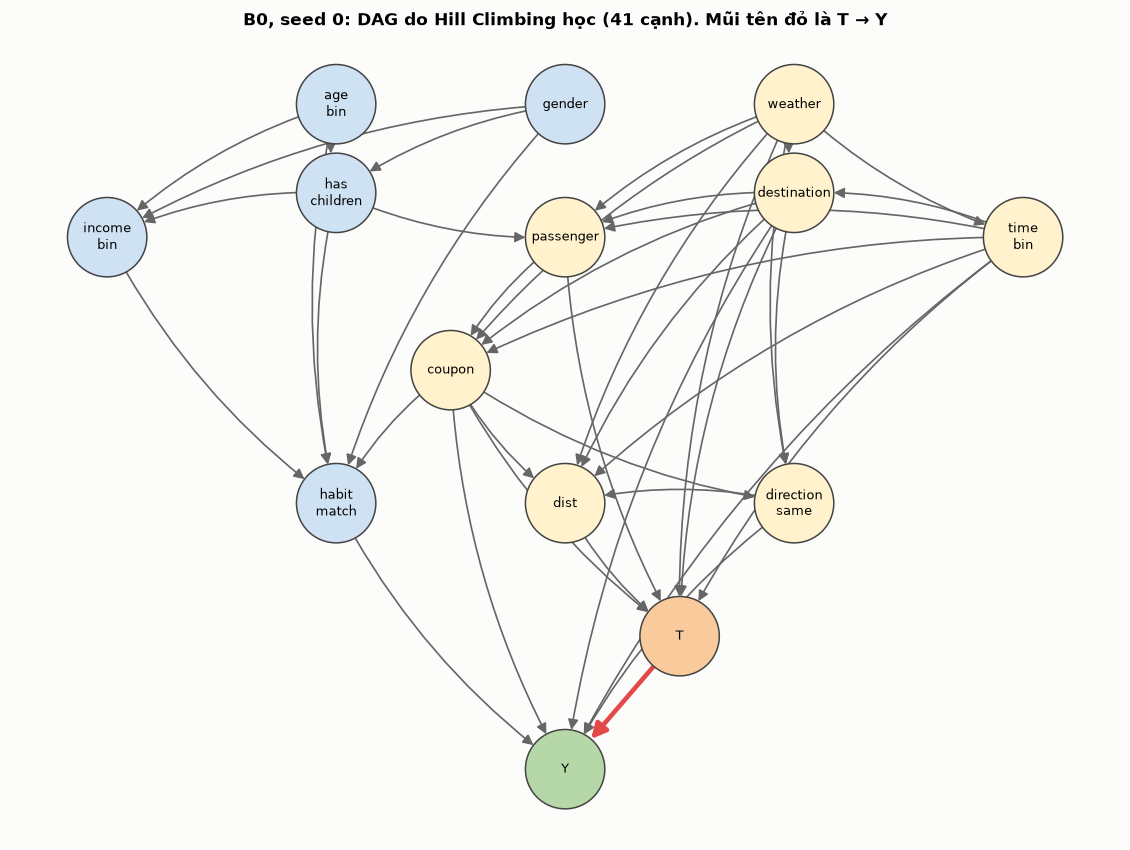

In [20]:
@dataclass
class Model:
    """Một mô hình đã học xong (B0, H1 hoặc H2). Chỉ là hộp chứa dữ liệu, không có phương thức."""
    name: str                       # "B0", "H1" hoặc "H2"
    edges: list                     # các mũi tên của DAG
    bn: DiscreteBayesianNetwork     # mạng Bayes đầy đủ: DAG + 14 bảng xác suất
    y_parents: list                 # các cha của Y
    y_table: pd.DataFrame           # "bảng Y": P(Y = 1 | cha của Y), dùng cho cả dự đoán lẫn can thiệp
    fit_seconds: float              # thời gian học (giây)
    info: dict                      # thông tin phụ: bảng xếp hạng ứng viên, lịch sử học, ma trận kề...


def build_b0(train: pd.DataFrame, val: pd.DataFrame) -> Model:
    """Xây B0: Hill Climbing đề xuất DAG → VALIDATION chọn → điền bảng xác suất bằng BDeu.

    Tham số: train, val — tập TRAIN và VALIDATION của một seed.
    Trả về: Model tên "B0".
    """
    start = time.time()
    candidates = hc_candidates(train)
    ranking = score_candidates(candidates, train, val)
    chosen = ranking.iloc[0]["ứng viên"]
    edges = candidates[chosen]
    assert check_dag(edges) == [], check_dag(edges)          # DAG được chọn phải qua đủ 11 luật của mục 6
    bn = fit_bn(edges, train)
    table = y_table_of(bn)
    parents = [c for c in table.columns if c != "p1"]
    return Model("B0", edges, bn, parents, table, time.time() - start, {"ranking": ranking, "chosen": chosen})


B0_0 = build_b0(train0, val0)
print(f"DAG được chọn: {B0_0.info['chosen']} | {len(B0_0.edges)} cạnh | lỗi ràng buộc: {check_dag(B0_0.edges)}")
print("Cha của Y:", ", ".join(sorted(B0_0.y_parents)))
print("Cha của T:", ", ".join(sorted(B0_0.bn.get_parents("T"))))
draw_dag(B0_0.edges, f"B0, seed 0: DAG do Hill Climbing học ({len(B0_0.edges)} cạnh). Mũi tên đỏ là T → Y")
plt.savefig(OUT / "dag_b0_seed0.png")

**Cách đọc hình.** Sáu hàng từ trên xuống là sáu lớp của `LAYERS`: nút gốc, hoàn cảnh của người và của chuyến đi, coupon, các biến phụ thuộc vào coupon, T, Y. Màu cho biết nhóm biến: người trả lời (xanh), kịch bản (vàng), T (cam), Y (lục). Lớp thứ hai có 5 nút nên được vẽ so le thành hai hàng sát nhau. Mũi tên chỉ đi từ lớp trên xuống lớp dưới, hoặc nối hai nút cùng lớp. Không có mũi tên nào đi vào `weather`, `age_bin`, `gender` (luật 1), và không có mũi tên nào từ nút xanh vào T (luật 8). Hai điều cần nhìn: **mũi tên nào đi vào T** (cái gì quyết định hạn coupon) và **mũi tên nào đi vào Y** (cái gì quyết định việc chấp nhận). Biến nào trỏ vào cả hai thì là confounder.

### 8.2 CPD của Y

`fit_bn` đã điền 14 CPD bằng BDeu (mục 7.2). Bảng quan trọng nhất là của Y. Hàm dưới đây xoay bảng đó cho dễ đọc: mỗi dòng là một **hoàn cảnh** (một tổ hợp giá trị của parents khác T), hai cột là xác suất chấp nhận khi hạn 1 ngày và khi hạn 2 giờ.

In [21]:
def effect_by_cell(y_table: pd.DataFrame) -> pd.DataFrame:
    """Xoay "bảng Y": mỗi dòng là một hoàn cảnh, đặt cạnh nhau xác suất chấp nhận khi hạn 1 ngày và khi hạn 2 giờ.

    Tham số: y_table — bảng gồm các cột cha của Y và cột p1.
    Trả về: bảng gồm các cha khác T, p_1d, p_2h và diff = p_2h − p_1d (hiệu ứng của hạn coupon trong hoàn cảnh đó).
    """
    others = [c for c in y_table.columns if c not in ("T", "p1")]
    one_day = y_table[y_table["T"] == "0"].drop(columns="T").rename(columns={"p1": "p_1d"})
    two_hours = y_table[y_table["T"] == "1"].drop(columns="T").rename(columns={"p1": "p_2h"})
    wide = one_day.merge(two_hours, on=others) if others else one_day.merge(two_hours, how="cross")
    wide["diff"] = wide["p_2h"] - wide["p_1d"]
    return wide


def cells_with_counts(y_table: pd.DataFrame, train: pd.DataFrame) -> pd.DataFrame:
    """Ghép bảng hoàn cảnh với số dòng TRAIN của từng hoàn cảnh, để biết con số nào đáng tin.

    Tham số: y_table — "bảng Y" của mô hình; train — tập TRAIN.
    Trả về: bảng của effect_by_cell() thêm cột n_1d, n_2h (số dòng TRAIN hạn 1 ngày, hạn 2 giờ), xếp từ hoàn cảnh nhiều dữ liệu nhất.
    """
    others = [c for c in y_table.columns if c not in ("T", "p1")]
    counts = group_table(train, others)[others + ["n_1d", "n_2h"]]
    cells = effect_by_cell(y_table).merge(counts, on=others, how="left").fillna({"n_1d": 0, "n_2h": 0})
    cells[["n_1d", "n_2h"]] = cells[["n_1d", "n_2h"]].astype(int)
    cells["n"] = cells["n_1d"] + cells["n_2h"]
    return cells.sort_values("n", ascending=False).drop(columns="n").reset_index(drop=True)


CELLS_B0 = cells_with_counts(B0_0.y_table, train0)
both_arms = CELLS_B0[(CELLS_B0["n_1d"] > 0) & (CELLS_B0["n_2h"] > 0)]         # hoàn cảnh có dữ liệu cho CẢ hai loại hạn
n_empty = int((CELLS_B0["n_1d"] == 0).sum() + (CELLS_B0["n_2h"] == 0).sum())
print(f"Bảng Y của B0 có {len(B0_0.y_table)} ô = {len(CELLS_B0)} hoàn cảnh × 2 loại hạn; {n_empty} ô không có dòng TRAIN nào (BDeu cho 0,5).")
print(f"{len(both_arms)} hoàn cảnh có dữ liệu cho cả hai loại hạn; trong đó {int((both_arms['diff'] < 0).sum())} hoàn cảnh "
      f"có xác suất chấp nhận khi hạn 2 giờ THẤP hơn khi hạn 1 ngày.")
print("Sáu hoàn cảnh nhiều dữ liệu nhất, rồi bốn hoàn cảnh ít dữ liệu nhất (trong số có đủ hai loại hạn):")
pd.concat([both_arms.head(6), both_arms.tail(4)]).round(3)

Bảng Y của B0 có 540 ô = 270 hoàn cảnh × 2 loại hạn; 351 ô không có dòng TRAIN nào (BDeu cho 0,5).
90 hoàn cảnh có dữ liệu cho cả hai loại hạn; trong đó 73 hoàn cảnh có xác suất chấp nhận khi hạn 2 giờ THẤP hơn khi hạn 1 ngày.
Sáu hoàn cảnh nhiều dữ liệu nhất, rồi bốn hoàn cảnh ít dữ liệu nhất (trong số có đủ hai loại hạn):


,coupon,destination,direction_same,habit_match,time_bin,p_1d,p_2h,diff,n_1d,n_2h
0,Coffee House,No Urgent Place,0,low,morning,0.523,0.480,-0.043,128,204
1,Coffee House,No Urgent Place,0,low,afternoon,0.399,0.344,-0.055,148,128
2,Restaurant(20-50),Home,0,low,evening,0.364,0.146,-0.218,140,82
3,Coffee House,Home,0,low,evening,0.218,0.115,-0.103,78,139
4,Bar,No Urgent Place,0,low,morning,0.278,0.032,-0.246,176,31
5,Restaurant(<20),No Urgent Place,0,mid,evening,0.831,0.806,-0.025,71,134
94,Restaurant(20-50),No Urgent Place,0,high,afternoon,0.799,0.749,-0.050,5,4
95,Restaurant(20-50),No Urgent Place,0,high,evening,0.995,0.429,-0.567,1,7
96,Bar,Home,0,high,evening,0.714,0.995,0.281,7,1
98,Restaurant(20-50),No Urgent Place,0,high,morning,0.998,0.334,-0.665,3,3


**Cách đọc kết quả.** Mỗi dòng là một hoàn cảnh. `p_1d` và `p_2h` là xác suất chấp nhận coupon theo bảng Y khi hạn 1 ngày và khi hạn 2 giờ; `diff = p_2h − p_1d` là hiệu ứng của hạn 2 giờ **trong riêng hoàn cảnh đó**; `n_1d`, `n_2h` là số dòng TRAIN mà bảng dựa vào.

- Ở seed 0, bảng Y có 540 ô nhưng 351 ô không có dòng TRAIN nào. Bảng đếm chỉ đáng tin ở những ô có dữ liệu, và đây chính là chỗ H1 (mục 9) sẽ thử làm tốt hơn.
- Trong 90 hoàn cảnh có dữ liệu cho cả hai loại hạn, 73 hoàn cảnh có `diff` âm. Hạn 2 giờ làm giảm tỉ lệ chấp nhận ở **phần lớn** hoàn cảnh chứ không chỉ ở vài hoàn cảnh cá biệt.
- Bốn dòng cuối cho thấy mặt trái: hoàn cảnh chỉ có vài dòng thì `diff` nhảy rất mạnh. Vì vậy ta không đọc từng ô riêng lẻ mà lấy **trung bình trên cả nhóm TEST** (mục 8.5).

### 8.3 DoWhy: tính được hiệu ứng không?

**Ý tưởng.** Có DAG rồi vẫn phải hỏi: *từ observational data, có tính được P(Y | do(T)) không?* Bước này gọi là **nhận diện** (identification) và chỉ dựa vào hình dạng của DAG, chưa đụng đến con số nào. DoWhy trả lời tự động: nó tìm một **backdoor adjustment set**, tức nhóm biến mà khi giữ cố định sẽ chặn mọi backdoor path T ← ... → Y.

Mô hình của ta thì điều chỉnh theo **parents của Y (trừ T)**. Lý do: Y không trỏ đi đâu, nên mọi backdoor path đều phải đi **vào** Y qua một parent của Y; giữ cố định tất cả parents đó là chặn hết. Hàm `backdoor_ok` kiểm tra lại điều này bằng `networkx` cho cả hai tập (tập của DoWhy và tập của mô hình).

In [22]:
def to_dowhy_frame(data: pd.DataFrame) -> pd.DataFrame:
    """Đổi dữ liệu sang dạng DoWhy cần: T và Y là số 0/1, các biến còn lại là kiểu phân loại (category).

    Tham số: data — bảng có 14 biến ở dạng chữ.
    Trả về: bảng 14 cột.
    """
    out = data[NODES].copy()
    out["T"] = as_int(data["T"])
    out["Y"] = as_int(data["Y"])
    for col in COVARIATES:
        out[col] = pd.Categorical(out[col], categories=STATES[col])
    return out


def dowhy_identify(edges: list[tuple[str, str]], data: pd.DataFrame) -> tuple:
    """Đưa DAG cho DoWhy và hỏi: hiệu ứng của T lên Y có nhận diện được không?

    Tham số: edges — các mũi tên của DAG; data — dữ liệu (DoWhy cần để biết tên cột).
    Trả về: (mô hình nhân quả của DoWhy, estimand = công thức nhận diện kèm tập điều chỉnh backdoor).
            DoWhy báo lỗi nếu không nhận diện được.
    """
    dot = "digraph { " + "; ".join(f'"{u}" -> "{v}"' for u, v in edges) + "; }"     # DAG viết theo cú pháp DOT
    model = CausalModel(data=to_dowhy_frame(data), treatment="T", outcome="Y", graph=dot)
    estimand = model.identify_effect(proceed_when_unidentifiable=False)
    return model, estimand


def backdoor_ok(edges: list[tuple[str, str]], adjust: list[str]) -> bool:
    """Tự kiểm tra tiêu chuẩn backdoor cho một tập điều chỉnh bằng networkx.

    Hai điều kiện: (1) không biến nào trong `adjust` là hậu quả của T;
                   (2) xoá các mũi tên đi RA từ T, rồi giữ cố định `adjust`, thì T và Y bị tách rời (d-separated).
    Tham số: edges — các mũi tên của DAG; adjust — tập điều chỉnh cần kiểm tra.
    Trả về: True nếu `adjust` chặn được mọi đường cửa sau.
    """
    graph = nx.DiGraph(edges)
    graph.add_nodes_from(NODES)
    after_T = nx.descendants(graph, "T")
    for z in adjust:
        if z in after_T:
            return False
    graph.remove_edges_from(list(graph.out_edges("T")))        # bỏ đường nhân quả T → ..., chỉ còn lại đường cửa sau
    return bool(nx.is_d_separator(graph, {"T"}, {"Y"}, set(adjust)))


_, ESTIMAND_B0 = dowhy_identify(B0_0.edges, train0)
adjust_dowhy = sorted(ESTIMAND_B0.get_backdoor_variables())
adjust_model = sorted(p for p in B0_0.y_parents if p != "T")
print("Tập điều chỉnh DoWhy chọn       :", adjust_dowhy, "| chặn hết cửa sau:", backdoor_ok(B0_0.edges, adjust_dowhy))
print("Tập điều chỉnh mô hình dùng     :", adjust_model, "| chặn hết cửa sau:", backdoor_ok(B0_0.edges, adjust_model))
print("Không điều chỉnh gì (so sánh thô):", [], "| chặn hết cửa sau:", backdoor_ok(B0_0.edges, []))
print()
print(str(ESTIMAND_B0))

Tập điều chỉnh DoWhy chọn       : ['coupon', 'destination', 'direction_same', 'habit_match', 'time_bin'] | chặn hết cửa sau: True
Tập điều chỉnh mô hình dùng     : ['coupon', 'destination', 'direction_same', 'habit_match', 'time_bin'] | chặn hết cửa sau: True
Không điều chỉnh gì (so sánh thô): [] | chặn hết cửa sau: False

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
 d                                                               
────(E[Y|direction_same,coupon,habit_match,destination,time_bin])
d[T]                                                             
Estimand assumption 1, Unconfoundedness: If U→{T} and U→Y then P(Y|T,direction_same,coupon,habit_match,destination,time_bin,U) = P(Y|T,direction_same,coupon,habit_match,destination,time_bin)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adj

**Cách đọc kết quả.** Dòng `Estimand name: backdoor` kèm một biểu thức nghĩa là DoWhy **nhận diện được** hiệu ứng bằng điều chỉnh backdoor. Biểu thức đọc là "mức thay đổi của Y theo T, sau khi giữ cố định các biến đứng sau dấu gạch đứng". Các mục `iv` (biến công cụ) và `frontdoor` để trống là bình thường: DAG này không có cấu trúc để dùng hai cách đó. Mục `general_adjustment` đưa ra thêm một adjustment set hợp lệ khác (parents của T), tức là có nhiều hơn một cách điều chỉnh đúng. Dòng "không điều chỉnh gì" trả về `False`: đó là lý do so sánh thô ở mục 5.1 chưa phải hiệu ứng nhân quả.

### 8.4 Dự đoán Y

**Ý tưởng.** Với mỗi dòng của TEST, tra bảng Y theo giá trị thật của parents → được xác suất chấp nhận coupon. So với câu trả lời thật bằng 4 chỉ số của Bảng A:

| Chỉ số | Đo cái gì | Tốt khi |
|---|---|---|
| AUROC | Lấy ngẫu nhiên một dòng "có nhận" và một dòng "không nhận": mô hình cho dòng "có nhận" xác suất cao hơn trong bao nhiêu phần trăm trường hợp? 0,5 = đoán mò, 1 = hoàn hảo | cao |
| macro-F1 | Đổi xác suất thành nhãn có/không bằng một ngưỡng, rồi chấm độ đúng cho cả hai nhãn, lấy trung bình. Ngưỡng được chọn trên **VALIDATION** | cao |
| Brier | Trung bình của (xác suất dự đoán − kết quả thật)². Đo xác suất có "đúng cỡ" không | thấp |
| Log loss | Giống Brier nhưng phạt rất nặng khi tự tin mà sai | thấp |

In [23]:
def best_f1_threshold(y: np.ndarray, p: np.ndarray) -> float:
    """Tìm ngưỡng đổi xác suất thành nhãn 0/1 cho macro-F1 cao nhất (chỉ gọi trên VALIDATION).

    Tham số: y — nhãn thật 0/1; p — xác suất dự đoán.
    Trả về: ngưỡng trong khoảng 0,05 đến 0,95.
    """
    grid = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y, (p >= thr).astype(int), average="macro") for thr in grid]
    return float(grid[int(np.argmax(scores))])


def prediction_metrics(y: np.ndarray, p: np.ndarray, threshold: float) -> dict:
    """Bốn chỉ số dự đoán của Bảng A.

    Tham số: y — nhãn thật 0/1; p — xác suất dự đoán; threshold — ngưỡng đã chọn trên VALIDATION.
    Trả về: dict gồm auroc, macro_f1, brier, log_loss.
    """
    return {"auroc": roc_auc_score(y, p), "macro_f1": f1_score(y, (p >= threshold).astype(int), average="macro"),
            "brier": brier_score_loss(y, p), "log_loss": log_loss(y, p)}


def evaluate_prediction(model: Model, val: pd.DataFrame, test: pd.DataFrame) -> dict:
    """Chấm khả năng dự đoán Y của một mô hình trên TEST.

    Tham số: model — mô hình đã học; val — để chọn ngưỡng F1; test — để chấm.
    Trả về: dict 4 chỉ số và ngưỡng đã dùng.
    """
    threshold = best_f1_threshold(as_int(val["Y"]), predict_y(model.y_table, val))
    metrics = prediction_metrics(as_int(test["Y"]), predict_y(model.y_table, test), threshold)
    metrics["threshold"] = threshold
    return metrics


PRED_B0 = evaluate_prediction(B0_0, val0, test0)
base_rate = as_int(train0["Y"]).mean()
print(f"Mốc so sánh: nếu luôn đoán bằng tỉ lệ chung {base_rate:.3f} thì AUROC = 0,5 và Brier = {brier_score_loss(as_int(test0['Y']), np.full(len(test0), base_rate)):.4f}.")
pd.DataFrame([PRED_B0], index=["B0, seed 0"]).round(4)

Mốc so sánh: nếu luôn đoán bằng tỉ lệ chung 0.576 thì AUROC = 0,5 và Brier = 0.2444.


,auroc,macro_f1,brier,log_loss,threshold
"B0, seed 0",0.7201,0.6786,0.2093,0.6175,0.5


**Cách đọc kết quả.** So với mốc "luôn đoán bằng tỉ lệ chung" in ở dòng đầu: AUROC của B0 khoảng 0,72 (mốc 0,5) và Brier khoảng 0,209 (mốc 0,244), tức mô hình có học được quy luật nhưng còn xa mức hoàn hảo. Điều này hợp lý: quyết định nhận coupon còn phụ thuộc nhiều thứ không có trong dữ liệu. Cột `threshold` là ngưỡng đổi xác suất thành nhãn có/không, được chọn trên VALIDATION rồi mới áp vào TEST, nên macro-F1 không bị "nhìn trộm" đáp án.

Cần nhớ: dự đoán tốt **không** bảo đảm ước lượng nhân quả đúng. Bảng A (dự đoán) và Bảng B (intervention) trả lời hai câu hỏi khác nhau, nên đề bài yêu cầu báo cáo cả hai.

### 8.5 Intervention do(T)

**Ý tưởng.** Đây là bước trả lời câu hỏi của bài. Làm theo 3 bước, giống hệt phép tính tay ở mục 5.3:

1. Lấy từng dòng của TEST, **giữ nguyên hoàn cảnh** (loại quán, điểm đến, thói quen...), chỉ **ép** T = 1 ngày rồi tra bảng Y → `q0`. Ép T = 2 giờ rồi tra bảng → `q1`.
2. Lấy trung bình trên mọi dòng TEST: `risk_1d` = trung bình của `q0`, `risk_2h` = trung bình của `q1`.
3. **ATE = risk_2h − risk_1d.**

Câu trả lời thật Y của TEST **không** được dùng ở đây, chỉ dùng hoàn cảnh của các dòng TEST. Vì vậy TEST đóng vai "nhóm người mà ta muốn biết hiệu ứng".

Vì sao "ép T rồi tra bảng" lại đúng là intervention? Trong DAG, intervention do(T = t) nghĩa là **xoá mọi mũi tên đi vào T** (T không còn do kịch bản quyết định mà do ta đặt) rồi cho T = t. Bảng của Y không đổi, và mọi biến khác đều có trước T nên cũng không đổi. Ô code kiểm tra điều này bằng `pgmpy`: `bn.do(["T"])` tạo mạng đã xoá mũi tên vào T, rồi `VariableElimination` tính xác suất trên mạng đó.

In [24]:
def do_query(y_table: pd.DataFrame, cohort: pd.DataFrame) -> pd.DataFrame:
    """Với từng dòng của cohort, tính xác suất chấp nhận nếu ÉP hạn 1 ngày (q0) và nếu ÉP hạn 2 giờ (q1).

    Tham số: y_table — "bảng Y" của mô hình; cohort — các dòng cần hỏi (chỉ dùng các cột hoàn cảnh, không dùng Y).
    Trả về: bảng 2 cột q0, q1, cùng số dòng với cohort.
    """
    others = [c for c in y_table.columns if c not in ("T", "p1")]
    out = pd.DataFrame(index=cohort.index)
    for t in ("0", "1"):
        what_if = cohort[others].copy()        # giữ nguyên hoàn cảnh của từng dòng
        what_if["T"] = t                       # ... nhưng ép hạn coupon = t cho MỌI dòng
        out[f"q{t}"] = predict_y(y_table, what_if)
    return out


def ate_from_table(y_table: pd.DataFrame, cohort: pd.DataFrame) -> dict:
    """Tính hiệu ứng trung bình của hạn coupon trên một nhóm dòng.

    Tham số: y_table — "bảng Y" của mô hình; cohort — nhóm dòng lấy làm chuẩn (TEST).
    Trả về: dict gồm risk_1d = P(Y=1 | do(T=0)), risk_2h = P(Y=1 | do(T=1)) và ate = risk_2h − risk_1d.
    """
    q = do_query(y_table, cohort)
    return {"risk_1d": float(q["q0"].mean()), "risk_2h": float(q["q1"].mean()), "ate": float((q["q1"] - q["q0"]).mean())}


def check_do_with_pgmpy(model: Model, cohort: pd.DataFrame, n_rows: int = 3) -> pd.DataFrame:
    """Đối chiếu "tra bảng" với phép can thiệp chính thức của pgmpy trên vài dòng đầu của cohort.

    Tham số: model — mô hình cần kiểm; cohort — TEST; n_rows — số dòng đem kiểm.
    Trả về: bảng so sánh, mỗi dòng là một (dòng TEST, giá trị ép cho T); cột `lệch` phải xấp xỉ 0.
    """
    network_after_do = model.bn.do(["T"])                    # pgmpy xoá mọi mũi tên đi vào T
    engine = VariableElimination(network_after_do)           # bộ máy tính xác suất chính xác trên mạng
    lookup = do_query(model.y_table, cohort)
    rows = []
    for i in range(n_rows):
        for t in ("0", "1"):
            evidence = {c: cohort.iloc[i][c] for c in COVARIATES}      # hoàn cảnh đầy đủ của dòng i
            evidence["T"] = t                                          # hạn coupon do ta đặt
            answer = engine.query(["Y"], evidence=evidence, show_progress=False)
            p_pgmpy = float(answer.values[answer.state_names["Y"].index("1")])
            p_lookup = float(lookup[f"q{t}"].iloc[i])
            rows.append({"dòng TEST": i, "ép T": ARM_LABEL[t], "pgmpy do()": p_pgmpy, "tra bảng": p_lookup, "lệch": abs(p_pgmpy - p_lookup)})
    return pd.DataFrame(rows)


Q_B0 = do_query(B0_0.y_table, test0)
ATE_B0 = ate_from_table(B0_0.y_table, test0)
print("Năm dòng TEST đầu tiên: hoàn cảnh của dòng, rồi xác suất chấp nhận nếu ép từng loại hạn")
display(pd.concat([test0[[p for p in B0_0.y_parents if p != "T"]], Q_B0], axis=1).head(5).round(3))
print(f"B0, seed 0: nếu mọi coupon hạn 1 ngày → {ATE_B0['risk_1d']:.3f}; nếu mọi coupon hạn 2 giờ → {ATE_B0['risk_2h']:.3f}; ATE = {ATE_B0['ate']:+.4f}")
print(f"So sánh: hiệu thô trên TRAIN = {NAIVE0['diff']:+.4f}; tính tay điều chỉnh theo coupon và destination = {ate_by_coupon_dest:+.4f}")
print()
print("Đối chiếu với phép can thiệp của pgmpy:")
CHECK_B0 = check_do_with_pgmpy(B0_0, test0)
display(CHECK_B0.round(6))
assert CHECK_B0["lệch"].max() < 1e-9

Năm dòng TEST đầu tiên: hoàn cảnh của dòng, rồi xác suất chấp nhận nếu ép từng loại hạn


,coupon,destination,direction_same,habit_match,time_bin,q0,q1
0,Restaurant(<20),No Urgent Place,0,high,afternoon,0.915,0.697
1,Coffee House,No Urgent Place,0,low,morning,0.523,0.480
2,Carry out & Take away,No Urgent Place,0,high,morning,0.854,0.696
3,Coffee House,No Urgent Place,0,low,afternoon,0.399,0.344
4,Coffee House,No Urgent Place,0,low,afternoon,0.399,0.344


B0, seed 0: nếu mọi coupon hạn 1 ngày → 0.652; nếu mọi coupon hạn 2 giờ → 0.489; ATE = -0.1627
So sánh: hiệu thô trên TRAIN = -0.1468; tính tay điều chỉnh theo coupon và destination = -0.1589

Đối chiếu với phép can thiệp của pgmpy:


,dòng TEST,ép T,pgmpy do(),tra bảng,lệch
0,0,hạn 1 ngày (T = 0),0.915222,0.915222,0.0
1,0,hạn 2 giờ (T = 1),0.696942,0.696942,0.0
2,1,hạn 1 ngày (T = 0),0.523436,0.523436,0.0
3,1,hạn 2 giờ (T = 1),0.480393,0.480393,0.0
4,2,hạn 1 ngày (T = 0),0.853579,0.853579,0.0
5,2,hạn 2 giờ (T = 1),0.695985,0.695985,0.0


**Cách đọc kết quả.**

- Bảng đầu: mỗi dòng TEST có hai con số, `q0` (nếu ép hạn 1 ngày) và `q1` (nếu ép hạn 2 giờ). Hai dòng có cùng hoàn cảnh thì có cùng `q0`, `q1`.
- ATE là trung bình của `q1 − q0`. Dấu âm nghĩa là hạn 2 giờ làm **giảm** tỉ lệ chấp nhận.
- Bảng đối chiếu: cột `lệch` bằng 0, tức "ép T rồi tra bảng" cho đúng kết quả của phép intervention chính thức trên mạng đã xoá mũi tên vào T.

<a id="9"></a>
## 9. H1: xác suất bằng neural network

**Mục tiêu.** Giữ **nguyên DAG của B0**, chỉ thay cách tính bảng Y: thay vì đếm trong từng ô, dùng một neural network nhỏ. Mọi khác biệt giữa H1 và B0 vì thế chỉ đến từ **cách tính xác suất của Y**.

**Ý tưởng.** Bảng đếm coi mỗi ô là một thế giới riêng: ô "Bar, về nhà, buổi tối" không học được gì từ ô "Bar, về nhà, buổi sáng". Ô ít dữ liệu thì con số kém tin cậy, ô trống thì chỉ biết trả về 0,5 (mục 8.2). Neural network học **một công thức chung** cho mọi ô, nên các ô na ná nhau chia sẻ thông tin cho nhau.

Các bước:

1. **One-hot:** mạng chỉ nhận số, nên mỗi biến phân loại được đổi thành các cột 0/1. Ví dụ `time_bin` có 3 mức thì thành 3 cột; "morning" là (0, 0, 1).
2. **MLP:** đầu vào → 32 nơ-ron → 16 nơ-ron → 1 số. Số cuối đi qua hàm sigmoid để nằm trong khoảng 0 đến 1, đó là P(Y = 1).
3. **Huấn luyện:** cho mạng xem TRAIN nhiều lượt (mỗi lượt gọi là một *epoch*), mỗi bước chỉnh trọng số để log loss giảm. Sau mỗi lượt, chấm trên VALIDATION. Nếu 10 lượt liền VALIDATION không tốt lên thì dừng và lấy lại mạng ở lượt tốt nhất (*early stopping*). Cách này ngăn mạng "học thuộc lòng" TRAIN.
4. **Đổi lại thành bảng:** hỏi mạng xác suất cho **mọi** ô, được một bảng Y mới, rồi đặt bảng đó vào Bayesian Network thay cho bảng cũ. Nhờ vậy H1 vẫn là một Bayesian Network bình thường, và mọi hàm ở mục 8 (dự đoán, intervention, đối chiếu pgmpy) dùng lại được y nguyên.

In [25]:
def onehot(data: pd.DataFrame, cols: list[str]) -> np.ndarray:
    """Đổi các cột phân loại thành ma trận 0/1: mỗi mức của mỗi cột thành một cột riêng.

    Tham số: data — bảng dữ liệu; cols — các cột cần đổi.
    Trả về: ma trận (số dòng × tổng số mức), kiểu float32. Thứ tự cột theo STATES nên cố định cho mọi lần gọi.
    """
    columns = []
    for col in cols:
        values = data[col].to_numpy()
        for state in STATES[col]:
            columns.append((values == state).astype(np.float32))
    return np.stack(columns, axis=1)


def build_mlp(n_inputs: int) -> torch.nn.Sequential:
    """Tạo MLP: n_inputs → 32 → 16 → 1 (kích thước lớp ẩn lấy từ Config).

    Tham số: n_inputs — số cột one-hot đầu vào.
    Trả về: mạng trả ra một số thực (logit); đưa qua sigmoid sẽ thành xác suất.
    """
    layers = []
    size = n_inputs
    for hidden in CFG.h1_hidden:
        layers += [torch.nn.Linear(size, hidden),       # lớp tuyến tính: tổ hợp có trọng số của đầu vào
                   torch.nn.ReLU(),                     # hàm kích hoạt: giữ số dương, số âm thành 0 (tạo tính phi tuyến)
                   torch.nn.Dropout(CFG.h1_dropout)]    # khi học, tắt ngẫu nhiên một phần nơ-ron để chống học vẹt
        size = hidden
    layers.append(torch.nn.Linear(size, 1))
    return torch.nn.Sequential(*layers)


def train_mlp(X_train: np.ndarray, y_train: np.ndarray, X_val: np.ndarray, y_val: np.ndarray, seed: int) -> tuple[torch.nn.Sequential, pd.DataFrame]:
    """Huấn luyện MLP dự đoán Y, dừng sớm theo VALIDATION.

    Tham số: X_train, y_train — one-hot của các cha của Y và nhãn Y trên TRAIN; X_val, y_val — tương tự trên VALIDATION; seed — hạt giống.
    Trả về: (mạng ở lượt có loss VALIDATION thấp nhất, bảng lịch sử loss theo từng lượt).
    """
    torch.manual_seed(seed)
    net = build_mlp(X_train.shape[1])
    optimizer = torch.optim.Adam(net.parameters(), lr=CFG.h1_lr)
    loss_fn = torch.nn.BCEWithLogitsLoss()                  # chính là log loss, tính trực tiếp từ logit
    Xt, yt = torch.tensor(X_train), torch.tensor(y_train, dtype=torch.float32)
    Xv, yv = torch.tensor(X_val), torch.tensor(y_val, dtype=torch.float32)
    best_loss, best_weights, bad_epochs, history = np.inf, None, 0, []
    for epoch in range(CFG.h1_max_epochs):
        # ----- Một lượt học: xáo trộn TRAIN, chia thành từng lô nhỏ, mỗi lô chỉnh trọng số một lần -----
        net.train()
        order = torch.randperm(len(Xt))
        for start in range(0, len(Xt), CFG.h1_batch):
            batch = order[start:start + CFG.h1_batch]
            optimizer.zero_grad()
            loss = loss_fn(net(Xt[batch]).squeeze(1), yt[batch])
            loss.backward()                                 # tính hướng cần chỉnh cho từng trọng số
            optimizer.step()                                # chỉnh trọng số một bước nhỏ theo hướng đó
        # ----- Chấm sau lượt học (tắt dropout bằng net.eval()) -----
        net.eval()
        with torch.no_grad():
            train_loss = loss_fn(net(Xt).squeeze(1), yt).item()
            val_loss = loss_fn(net(Xv).squeeze(1), yv).item()
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
        # ----- Early stopping -----
        if val_loss < best_loss - 1e-5:
            best_loss, bad_epochs = val_loss, 0
            best_weights = {name: w.clone() for name, w in net.state_dict().items()}     # chụp lại mạng tốt nhất
        else:
            bad_epochs += 1
            if bad_epochs >= CFG.h1_patience:
                break
    net.load_state_dict(best_weights)
    net.eval()
    return net, pd.DataFrame(history)


def mlp_y_table(net: torch.nn.Sequential, parents: list[str]) -> pd.DataFrame:
    """Hỏi MLP xác suất P(Y = 1) cho MỌI tổ hợp giá trị của các cha → "bảng Y" cùng dạng với B0.

    Tham số: net — mạng đã huấn luyện; parents — các cha của Y (đúng thứ tự đã dùng khi huấn luyện).
    Trả về: bảng gồm các cột cha và cột p1.
    """
    cells = pd.DataFrame(list(itertools.product(*[STATES[p] for p in parents])), columns=parents)
    with torch.no_grad():
        p1 = torch.sigmoid(net(torch.tensor(onehot(cells, parents))).squeeze(1)).numpy().astype(float)
    cells["p1"] = np.clip(p1, 1e-6, 1 - 1e-6)              # tránh đúng 0 hoặc đúng 1 (log loss sẽ vô cực)
    return cells


def y_table_to_cpd(y_table: pd.DataFrame) -> TabularCPD:
    """Gói "bảng Y" thành bảng xác suất hợp lệ của pgmpy, để đặt vào mạng Bayes.

    Tham số: y_table — bảng từ mlp_y_table() (các ô xếp đúng thứ tự itertools.product).
    Trả về: TabularCPD của nút Y.
    """
    parents = [c for c in y_table.columns if c != "p1"]
    p1 = y_table["p1"].to_numpy()
    state_names = {"Y": STATES["Y"]}
    for p in parents:
        state_names[p] = STATES[p]
    return TabularCPD("Y", 2, np.vstack([1 - p1, p1]), evidence=parents, evidence_card=[len(STATES[p]) for p in parents], state_names=state_names)


def build_h1(b0: Model, train: pd.DataFrame, val: pd.DataFrame, seed: int) -> Model:
    """Xây H1: giữ DAG và mọi bảng xác suất của B0, chỉ thay bảng của Y bằng bảng do MLP sinh ra.

    Tham số: b0 — mô hình B0 của cùng seed; train, val — dữ liệu; seed — hạt giống của MLP.
    Trả về: Model tên "H1" (fit_seconds chỉ tính thời gian huấn luyện MLP).
    """
    start = time.time()
    parents = b0.y_parents
    net, history = train_mlp(onehot(train, parents), as_int(train["Y"]), onehot(val, parents), as_int(val["Y"]), seed)
    table = mlp_y_table(net, parents)
    bn = b0.bn.copy()                         # bản sao của B0, để B0 gốc không bị đổi
    bn.remove_cpds("Y")                       # bỏ bảng Y do đếm
    bn.add_cpds(y_table_to_cpd(table))        # đặt bảng Y do MLP sinh
    assert bn.check_model()
    n_params = sum(w.numel() for w in net.parameters())
    return Model("H1", b0.edges, bn, parents, table, time.time() - start, {"net": net, "history": history, "n_params": n_params})


def summary_row(model: Model, val: pd.DataFrame, test: pd.DataFrame) -> dict:
    """Tóm tắt một mô hình thành một dòng: cấu trúc, 4 chỉ số dự đoán và ATE trên TEST.

    Tham số: model — mô hình đã học; val, test — dữ liệu của cùng seed.
    Trả về: dict một dòng của bảng so sánh.
    """
    row = {"mô hình": model.name, "số cạnh": len(model.edges), "số cha của Y": len(model.y_parents), "số ô bảng Y": len(model.y_table)}
    row.update(evaluate_prediction(model, val, test))
    row.update(ate_from_table(model.y_table, test))
    return row


H1_0 = build_h1(B0_0, train0, val0, seed=0)
history = H1_0.info["history"]
print(f"MLP có {H1_0.info['n_params']} trọng số; học {len(history)} lượt trong {H1_0.fit_seconds:.1f} giây; "
      f"giữ mạng ở lượt {int(history['val_loss'].idxmin())} (loss VALIDATION = {history['val_loss'].min():.4f}).")
print("Đối chiếu can thiệp với pgmpy cho H1: lệch lớn nhất =", f"{check_do_with_pgmpy(H1_0, test0)['lệch'].max():.1e}")
pd.DataFrame([summary_row(B0_0, val0, test0), summary_row(H1_0, val0, test0)]).set_index("mô hình").round(4)

MLP có 1153 trọng số; học 51 lượt trong 4.0 giây; giữ mạng ở lượt 40 (loss VALIDATION = 0.5677).
Đối chiếu can thiệp với pgmpy cho H1: lệch lớn nhất = 0.0e+00


,số cạnh,số cha của Y,số ô bảng Y,auroc,macro_f1,brier,log_loss,threshold,risk_1d,risk_2h,ate
mô hình,,,,,,,,,,,
B0,41,6,540,0.7201,0.6786,0.2093,0.6175,0.50,0.6519,0.4892,-0.1627
H1,41,6,540,0.7324,0.6763,0.2048,0.5986,0.51,0.6585,0.4891,-0.1694


Hình dưới cho thấy H1 học thế nào và bảng Y của nó khác B0 ở đâu.

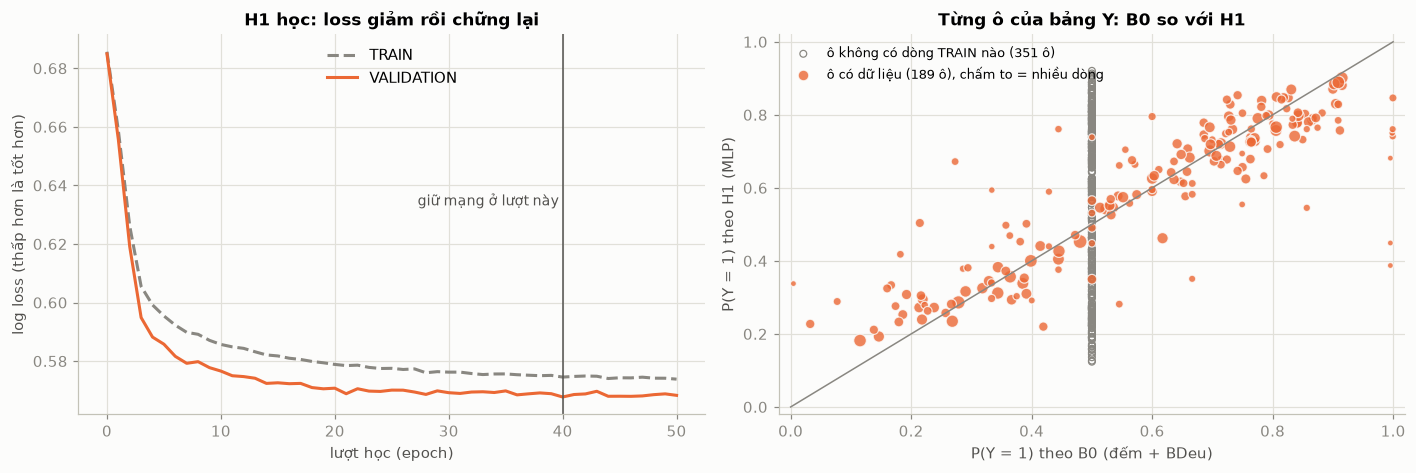

In [26]:
def plot_h1(h1: Model, b0: Model, train: pd.DataFrame) -> None:
    """Vẽ hai hình cho H1: (trái) loss theo từng lượt học; (phải) so từng ô của bảng Y giữa B0 và H1.

    Tham số: h1, b0 — hai mô hình của cùng seed; train — TRAIN (để đếm số dòng của từng ô).
    """
    history = h1.info["history"]
    best_epoch = int(history["val_loss"].idxmin())
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.4))
    # ----- Trái: đường học -----
    left.plot(history["epoch"], history["train_loss"], color=MUTED, linestyle="--", label="TRAIN")
    left.plot(history["epoch"], history["val_loss"], color=COLOR["H1"], label="VALIDATION")
    left.axvline(best_epoch, color=INK_SOFT, linewidth=1)
    left.text(best_epoch, 0.55, "giữ mạng ở lượt này ", transform=left.get_xaxis_transform(), color=INK_SOFT, ha="right", fontsize=9)
    left.set_xlabel("lượt học (epoch)")
    left.set_ylabel("log loss (thấp hơn là tốt hơn)")
    left.set_title("H1 học: loss giảm rồi chững lại")
    left.legend(loc="upper center")
    # ----- Phải: mỗi chấm là một ô của bảng Y -----
    parents = b0.y_parents
    counts = train.groupby(parents).size().rename("n").reset_index()
    both = b0.y_table.rename(columns={"p1": "b0"}).merge(h1.y_table.rename(columns={"p1": "h1"}), on=parents)
    both = both.merge(counts, on=parents, how="left").fillna({"n": 0})
    seen, empty = both[both["n"] > 0], both[both["n"] == 0]
    right.plot([0, 1], [0, 1], color=MUTED, linewidth=1)                 # đường chéo: hai mô hình cho cùng xác suất
    right.scatter(empty["b0"], empty["h1"], s=20, facecolors="none", edgecolors=MUTED, linewidths=0.8,
                  label=f"ô không có dòng TRAIN nào ({len(empty)} ô)")
    right.scatter(seen["b0"], seen["h1"], s=10 + 5 * np.sqrt(seen["n"]), color=COLOR["H1"], alpha=0.8, edgecolors="#fcfcfb", linewidths=0.8,
                  label=f"ô có dữ liệu ({len(seen)} ô), chấm to = nhiều dòng")
    right.set_xlabel("P(Y = 1) theo B0 (đếm + BDeu)")
    right.set_ylabel("P(Y = 1) theo H1 (MLP)")
    right.set_title("Từng ô của bảng Y: B0 so với H1")
    right.set_xlim(-0.02, 1.02)
    right.set_ylim(-0.02, 1.02)
    right.legend(loc="upper left", fontsize=8.5)
    fig.tight_layout()
    fig.savefig(OUT / "h1_seed0.png")


plot_h1(H1_0, B0_0, train0)

**Cách đọc hình.**

- *Trái:* hai đường cùng giảm nghĩa là mạng đang học được quy luật thật. Khi đường VALIDATION (cam) thôi giảm trong lúc đường TRAIN (xám) vẫn giảm, mạng bắt đầu học vẹt, và early stopping dừng tại đó.
- *Phải:* chấm nằm trên đường chéo là ô mà hai mô hình cho cùng xác suất. Chấm to (ô nhiều dữ liệu) nằm sát đường chéo: ở đâu có đủ dữ liệu thì đếm và MLP đồng ý với nhau. Các vòng tròn rỗng xếp thành một cột dọc tại 0,5: đó là các ô trống, B0 chỉ biết trả về 0,5 còn H1 đưa ra một dự đoán dựa trên các ô tương tự.

<a id="10"></a>
## 10. H2: DAG bằng neural network

**Mục tiêu.** Tìm DAG bằng neural network (NOTEARS-MLP) thay cho Hill Climbing. Mọi thứ khác giữ như B0: cùng ràng buộc, cùng cách điền CPD (BDeu). Khác biệt giữa H2 và B0 vì thế chỉ đến từ **cách tìm DAG**.

**Ý tưởng.** Hill Climbing thử từng mũi tên một. NOTEARS đổi bài toán thành "vặn núm liên tục":

1. **Mỗi nút có một mạng nhỏ** đoán nút đó từ 13 nút còn lại. Nếu mạng của nút *j* dựa nhiều vào nút *i* (các trọng số nối từ *i* lớn) thì coi như có mũi tên *i → j*. Gom lại được ma trận A, với A[i, j] = **độ mạnh** của mũi tên i → j.
2. **Phạt thưa (L1):** nếu để tự do, mạng nào cũng dùng tất cả các nút khác. Phạt L1 ép các trọng số không cần thiết về 0, chỉ để lại cạnh thật sự hữu ích.
3. **Phạt vòng kín:** có một hàm h(A) bằng 0 **đúng khi** đồ thị không có vòng kín, và càng lớn khi vòng càng nhiều, càng mạnh. Thuật toán tối ưu "độ khớp dữ liệu + phạt" và tăng dần mức phạt vòng kín (nhân 10 mỗi khi h giảm chậm) cho đến khi h gần 0 (dưới `h2_h_tol`).
4. **Ràng buộc mục 6:** trọng số của các cạnh bị cấm được nhân với 0 (ma trận `MASK`), nên chúng không bao giờ xuất hiện.
5. **Cắt ngưỡng:** giữ mũi tên có độ mạnh lớn hơn một ngưỡng. Thử 5 ngưỡng và để VALIDATION chọn, theo **đúng quy tắc** đã dùng cho B0 (hàm `score_candidates`).

**Một lựa chọn cần nói rõ.** Hạn coupon T chỉ phụ thuộc yếu vào kịch bản (phần lớn là ngẫu nhiên), nên các cạnh "kịch bản → T" yếu hơn hẳn các cạnh khác. Với mức phạt L1 chung, NOTEARS hay xoá sạch parents của T, tức xoá luôn cấu trúc confounding mà bài toán cần mô tả. Vì vậy phạt L1 cho các cạnh **đi vào T** được giảm 10 lần (`h2_l1_scale_T = 0.1`). Con số này lấy từ bản đầy đủ trước đó (notebook 03), nơi ba mức 1,0 / 0,3 / 0,1 được so trên VALIDATION: mức 0,1 được chọn ở 4/5 seed, còn mức 1,0 làm T mất hết parents ở 3/5 seed. Trong bản đó, lựa chọn này không làm đổi parent set của Y nên không làm đổi ATE của H2.

In [27]:
def notears_init(seed: int) -> dict:
    """Tạo trọng số ban đầu cho 14 mạng nhỏ (mỗi nút một mạng) và các ma trận phụ trợ.

    Tham số: seed — hạt giống cho trọng số ngẫu nhiên ban đầu.
    Trả về: dict gồm
        W1  (14, hidden, D)  lớp 1 của mạng từng nút; D = tổng số cột one-hot của 14 nút
        b1  (14, hidden)     hệ số tự do của lớp 1
        W2, b2               lớp ra của từng nút (danh sách 14 phần tử vì mỗi nút có số mức khác nhau)
        mask (14, 14)        mask[i, j] = 1 nếu mũi tên i → j được phép
        col_mask (14, D)     col_mask[j, c] = 1 nếu nút chứa cột one-hot c được phép làm cha của nút j
        col_to_node (D, 14)  cột one-hot c thuộc nút nào (để gom các cột của cùng một nút)
        l1_weight (14,)      hệ số nhân phạt L1 theo nút đích (T nhận mức nhẹ hơn)
    """
    torch.manual_seed(seed)
    sizes = [len(STATES[n]) for n in NODES]                           # số mức của từng nút
    d, D, hidden = len(NODES), sum(sizes), CFG.h2_hidden
    node_of_col = torch.tensor(np.repeat(np.arange(d), sizes))        # cột one-hot thứ c thuộc nút nào
    mask = torch.tensor(MASK)
    l1_weight = torch.ones(d)
    l1_weight[NODES.index("T")] = CFG.h2_l1_scale_T
    return {"W1": (torch.randn(d, hidden, D) * 0.1).requires_grad_(True),
            "b1": torch.zeros(d, hidden, requires_grad=True),
            "W2": [(torch.randn(k, hidden) * 0.1).requires_grad_(True) for k in sizes],
            "b2": [torch.zeros(k, requires_grad=True) for k in sizes],
            "mask": mask, "col_mask": mask[node_of_col, :].T.contiguous(),
            "col_to_node": torch.nn.functional.one_hot(node_of_col, d).float(), "l1_weight": l1_weight}


def notears_adjacency(p: dict) -> torch.Tensor:
    """Tính ma trận độ mạnh A từ trọng số lớp 1: A[i, j] lớn nghĩa là mạng của nút j dựa nhiều vào nút i.

    Tham số: p — dict từ notears_init().
    Trả về: tensor 14 × 14; ô của cạnh bị cấm luôn bằng 0.
    """
    w = p["W1"] * p["col_mask"][:, None, :]            # chặn các cột đầu vào không được phép
    per_col = (w ** 2).sum(dim=1)                      # (14, D): với nút đích j, tổng bình phương trọng số của từng cột đầu vào
    per_node = per_col @ p["col_to_node"]              # (14, 14): gom các cột one-hot của cùng một nút nguồn → [j, i]
    return torch.sqrt(per_node.T + 1e-12) * p["mask"]  # chuyển vị để chỉ số là [i, j] = i → j


def notears_data_loss(p: dict, X: torch.Tensor, idx: torch.Tensor) -> torch.Tensor:
    """Độ khớp dữ liệu: tổng log loss của 14 mạng, mỗi mạng đoán một nút từ các nút còn lại.

    Tham số: p — trọng số; X — one-hot của cả 14 nút (n × D); idx — số thứ tự mức của từng nút ở từng dòng (n × 14).
    Trả về: một số (tensor vô hướng); càng nhỏ là càng khớp.
    """
    total = torch.zeros(())
    for j in range(len(NODES)):
        w1 = p["W1"][j] * p["col_mask"][j]                             # mạng của nút j chỉ được nhìn các nút được phép làm cha
        hidden = torch.relu(X @ w1.T + p["b1"][j])                     # lớp ẩn
        logits = hidden @ p["W2"][j].T + p["b2"][j]                    # điểm cho từng mức của nút j
        total = total + torch.nn.functional.cross_entropy(logits, idx[:, j])
    return total


def notears_cycle(A: torch.Tensor) -> torch.Tensor:
    """Độ "có vòng kín" của đồ thị: h(A) = trace(exp(A ∘ A)) − số nút. Bằng 0 đúng khi không có vòng kín nào.

    Tham số: A — ma trận độ mạnh.
    Trả về: một số không âm (tensor vô hướng).
    """
    return torch.trace(torch.matrix_exp(A * A)) - A.shape[0]


def notears_closure(optimizer: torch.optim.Optimizer, p: dict, X: torch.Tensor, idx: torch.Tensor, rho: float, alpha: float) -> torch.Tensor:
    """Hàm mục tiêu cho một bước tối ưu = độ khớp dữ liệu + phạt vòng kín + phạt thưa (L1) + phạt trọng số lớn (L2).

    Tham số: optimizer — bộ tối ưu LBFGS; p — trọng số; X, idx — dữ liệu; rho, alpha — mức phạt vòng kín hiện tại.
    Trả về: giá trị hàm mục tiêu (đã tính gradient). LBFGS gọi hàm này nhiều lần trong một bước.
    """
    optimizer.zero_grad()
    h = notears_cycle(notears_adjacency(p))
    l1 = (p["l1_weight"][:, None, None] * p["W1"] * p["col_mask"][:, None, :]).abs().sum()
    l2 = (p["W1"] ** 2).sum()
    for w2 in p["W2"]:
        l2 = l2 + (w2 ** 2).sum()
    objective = notears_data_loss(p, X, idx) + 0.5 * rho * h * h + alpha * h + CFG.h2_lambda1 * l1 + 0.5 * CFG.h2_lambda2 * l2
    objective.backward()
    return objective


def notears_learn(train: pd.DataFrame, seed: int, verbose: bool = False) -> tuple[np.ndarray, pd.DataFrame]:
    """Chạy NOTEARS-MLP có mask trên TRAIN.

    Tham số: train — tập TRAIN; seed — hạt giống; verbose — True thì in tiến trình từng vòng.
    Trả về: (ma trận độ mạnh A 14 × 14 với A[i, j] = độ mạnh của NODES[i] → NODES[j], bảng nhật ký từng vòng).
    """
    p = notears_init(seed)
    X = torch.tensor(onehot(train, NODES))
    index_columns = []
    for node in NODES:                                   # đổi mỗi giá trị thành số thứ tự của nó trong STATES
        position = {state: k for k, state in enumerate(STATES[node])}
        index_columns.append(train[node].map(position).to_numpy().astype(np.int64))
    idx = torch.tensor(np.stack(index_columns, axis=1))
    trainable = [p["W1"], p["b1"]] + p["W2"] + p["b2"]
    rho, alpha, h = 1.0, 0.0, np.inf                     # rho, alpha: mức phạt vòng kín; h: độ có vòng hiện tại
    log = []
    for step in range(CFG.h2_max_outer):
        # Tối ưu với mức phạt hiện tại. Nếu vòng kín chưa giảm xuống dưới 1/4 lần trước thì nhân mức phạt lên 10 và làm lại.
        while rho < CFG.h2_rho_max:
            optimizer = torch.optim.LBFGS(trainable, lr=1.0, max_iter=CFG.h2_inner_steps, line_search_fn="strong_wolfe")
            # LBFGS cần một hàm không tham số; functools.partial "điền sẵn" các tham số thay cho việc viết hàm lồng
            optimizer.step(functools.partial(notears_closure, optimizer, p, X, idx, rho, alpha))
            with torch.no_grad():
                h_new = float(notears_cycle(notears_adjacency(p)))
            if h_new > 0.25 * h:
                rho *= 10
            else:
                break
        h = h_new
        alpha += rho * h
        with torch.no_grad():
            fit = float(notears_data_loss(p, X, idx))
        log.append({"vòng": step, "h (độ có vòng)": h, "rho (mức phạt)": rho, "độ khớp": fit})
        if verbose:
            print(f"  vòng {step:2d}: h = {h:.2e} | mức phạt rho = {rho:.0e} | độ khớp = {fit:.4f}")
        if h <= CFG.h2_h_tol or rho >= CFG.h2_rho_max:
            break
    with torch.no_grad():
        A = notears_adjacency(p).numpy()
    assert np.all(A[MASK == 0] == 0), "cạnh bị cấm phải có độ mạnh bằng 0"
    return A, pd.DataFrame(log)


def threshold_dag(A: np.ndarray, threshold: float) -> list[tuple[str, str]]:
    """Đổi ma trận độ mạnh thành DAG: giữ cạnh mạnh hơn ngưỡng, phá vòng kín nếu còn, thêm cạnh bắt buộc.

    Tham số: A — ma trận độ mạnh; threshold — ngưỡng giữ cạnh.
    Trả về: danh sách mũi tên của một DAG.
    """
    graph = nx.DiGraph()
    graph.add_nodes_from(NODES)
    for i, u in enumerate(NODES):
        for j, v in enumerate(NODES):
            if A[i, j] > threshold:
                graph.add_edge(u, v, weight=float(A[i, j]))
    while not nx.is_directed_acyclic_graph(graph):          # nếu còn vòng kín: bỏ cạnh yếu nhất của vòng đó
        cycle = list(nx.find_cycle(graph))
        weights = [graph.edges[edge]["weight"] for edge in cycle]
        graph.remove_edge(*cycle[int(np.argmin(weights))])
    for u, v in REQUIRED:                                   # luật 10: T → Y phải có
        if not graph.has_edge(u, v):
            graph.add_edge(u, v)
    return sorted(graph.edges())


def build_h2(train: pd.DataFrame, val: pd.DataFrame, seed: int, verbose: bool = False) -> Model:
    """Xây H2: NOTEARS-MLP học ma trận độ mạnh → thử 5 ngưỡng → VALIDATION chọn DAG → điền bảng xác suất bằng BDeu.

    Tham số: train, val — dữ liệu của một seed; seed — hạt giống của NOTEARS; verbose — in tiến trình.
    Trả về: Model tên "H2".
    """
    start = time.time()
    A, log = notears_learn(train, seed, verbose)
    candidates, threshold_of = {}, {}
    for threshold in CFG.h2_thresholds:
        name = f"ngưỡng {threshold:.2f}"
        candidates[name] = threshold_dag(A, threshold)
        threshold_of[name] = threshold
    ranking = score_candidates(candidates, train, val)       # cùng quy tắc chọn với B0
    chosen = ranking.iloc[0]["ứng viên"]
    edges = candidates[chosen]
    assert check_dag(edges) == [], check_dag(edges)
    bn = fit_bn(edges, train)
    table = y_table_of(bn)
    parents = [c for c in table.columns if c != "p1"]
    found_TY = bool(A[NODES.index("T"), NODES.index("Y")] > threshold_of[chosen])      # NOTEARS có tự tìm ra T → Y không?
    info = {"A": A, "log": log, "ranking": ranking, "chosen": chosen, "threshold": threshold_of[chosen], "found_TY": found_TY}
    return Model("H2", edges, bn, parents, table, time.time() - start, info)


H2_0 = build_h2(train0, val0, seed=0, verbose=True)
print(f"NOTEARS chạy {len(H2_0.info['log'])} vòng; tổng thời gian H2: {H2_0.fit_seconds:.0f} giây.")
with pd.option_context("display.max_colwidth", 90):
    display(H2_0.info["ranking"].round(4))

  vòng  0: h = 3.20e-01 | mức phạt rho = 1e+00 | độ khớp = 10.8358


  vòng  1: h = 3.66e-02 | mức phạt rho = 1e+02 | độ khớp = 11.1326


  vòng  2: h = 5.52e-03 | mức phạt rho = 1e+03 | độ khớp = 11.2843


  vòng  3: h = 5.55e-04 | mức phạt rho = 1e+04 | độ khớp = 11.3279


  vòng  4: h = 1.29e-04 | mức phạt rho = 1e+05 | độ khớp = 11.3423


  vòng  5: h = 3.15e-05 | mức phạt rho = 1e+06 | độ khớp = 11.3450


  vòng  6: h = 4.77e-06 | mức phạt rho = 1e+08 | độ khớp = 11.3479


NOTEARS chạy 7 vòng; tổng thời gian H2: 85 giây.


,ứng viên,hợp lệ,số cạnh,cha của Y,cha của T,val log-loss Y,val LL cả mạng
0,ngưỡng 0.15,True,31,"T, coupon, destination, habit_match, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather",0.5830,-10.2544
1,ngưỡng 0.20,True,27,"T, coupon, habit_match","coupon, destination, direction_same, dist, passenger, time_bin, weather",0.5907,-10.4450
2,ngưỡng 0.30,True,23,"T, coupon, habit_match","coupon, direction_same, dist, passenger, time_bin, weather",0.5907,-10.5012
3,ngưỡng 0.10,True,33,"T, coupon, destination, habit_match, passenger, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather",0.6095,-10.2464
4,ngưỡng 0.05,True,39,"T, coupon, destination, direction_same, gender, habit_match, passenger, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather",0.6535,-10.1502


**Cách đọc kết quả.**

- *Nhật ký:* `h` giảm dần về 0 nghĩa là các vòng kín đang bị loại; `rho` tăng là mức phạt được siết lại. `độ khớp` tăng nhẹ là cái giá của việc bỏ bớt cạnh.
- *Bảng ngưỡng:* ngưỡng thấp giữ nhiều cạnh, ngưỡng cao giữ ít. Dòng đầu là DAG được chọn. Cột `cha của T` cho biết H2 có tìm lại được các mũi tên kịch bản → T không.

Hình dưới là ma trận độ mạnh A: hàng là nút **đi**, cột là nút **đến**. Ô xám là cạnh bị cấm (luôn bằng 0). Ô có ghi số là cạnh được giữ lại ở ngưỡng đã chọn.

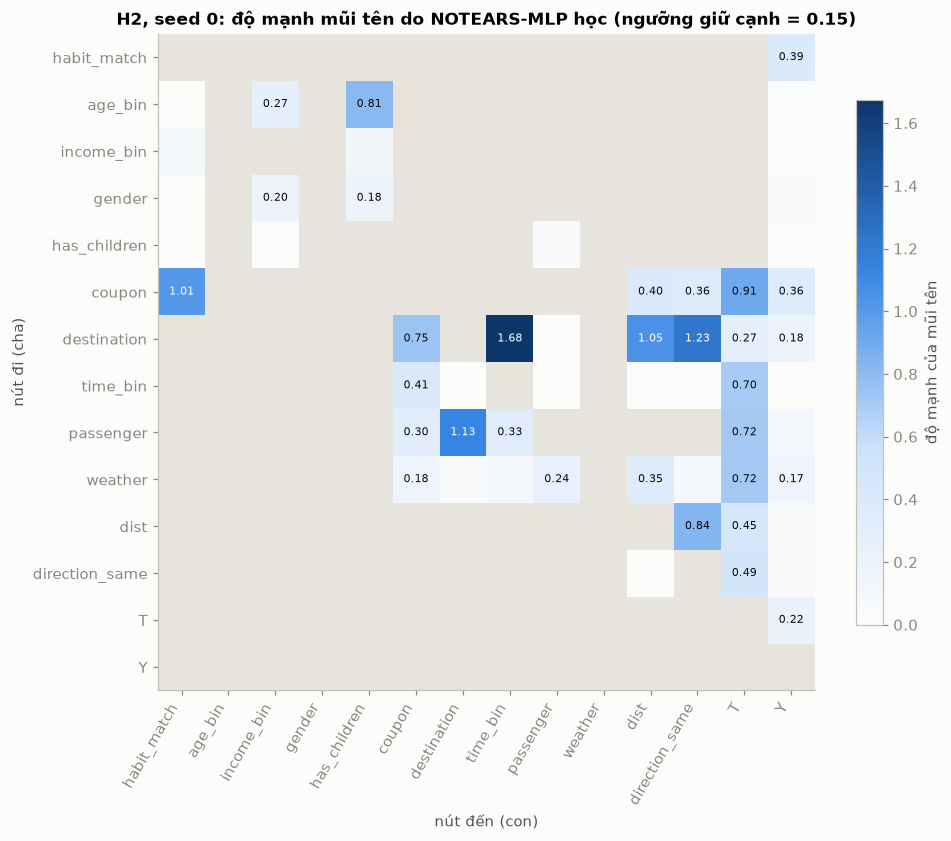

In [28]:
def plot_adjacency(A: np.ndarray, threshold: float, title: str) -> None:
    """Vẽ ma trận độ mạnh của H2 dạng bản đồ nhiệt; ô bị cấm tô xám; ghi số cho các ô vượt ngưỡng.

    Tham số: A — ma trận độ mạnh 14 × 14; threshold — ngưỡng đã chọn; title — tiêu đề.
    """
    cmap = LinearSegmentedColormap.from_list("blue", ["#fcfcfb", "#cde2fb", "#3987e5", "#0d366b"])   # một màu, nhạt → đậm
    cmap.set_bad("#e6e4dd")                                    # màu cho ô bị cấm
    fig, ax = plt.subplots(figsize=(9.2, 7.6))
    image = ax.imshow(np.ma.masked_where(MASK == 0, A), cmap=cmap, vmin=0, vmax=float(A.max()))
    for i in range(len(NODES)):
        for j in range(len(NODES)):
            if MASK[i, j] == 1 and A[i, j] > threshold:
                ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="#ffffff" if A[i, j] > 0.55 * A.max() else INK)
    ax.set_xticks(range(len(NODES)))
    ax.set_xticklabels(NODES, rotation=60, ha="right")
    ax.set_yticks(range(len(NODES)))
    ax.set_yticklabels(NODES)
    ax.set_xlabel("nút đến (con)")
    ax.set_ylabel("nút đi (cha)")
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.8, label="độ mạnh của mũi tên")
    fig.tight_layout()
    fig.savefig(OUT / "h2_adjacency_seed0.png")


plot_adjacency(H2_0.info["A"], H2_0.info["threshold"], f"H2, seed 0: độ mạnh mũi tên do NOTEARS-MLP học (ngưỡng giữ cạnh = {H2_0.info['threshold']:.2f})")

DAG của H2: 31 cạnh | lỗi ràng buộc: [] | NOTEARS tự tìm ra T → Y: True
Cha của Y: T, coupon, destination, habit_match, weather
Cha của T: coupon, destination, direction_same, dist, passenger, time_bin, weather
So với B0: 25 cạnh chung, 16 cạnh chỉ B0 có, 6 cạnh chỉ H2 có.


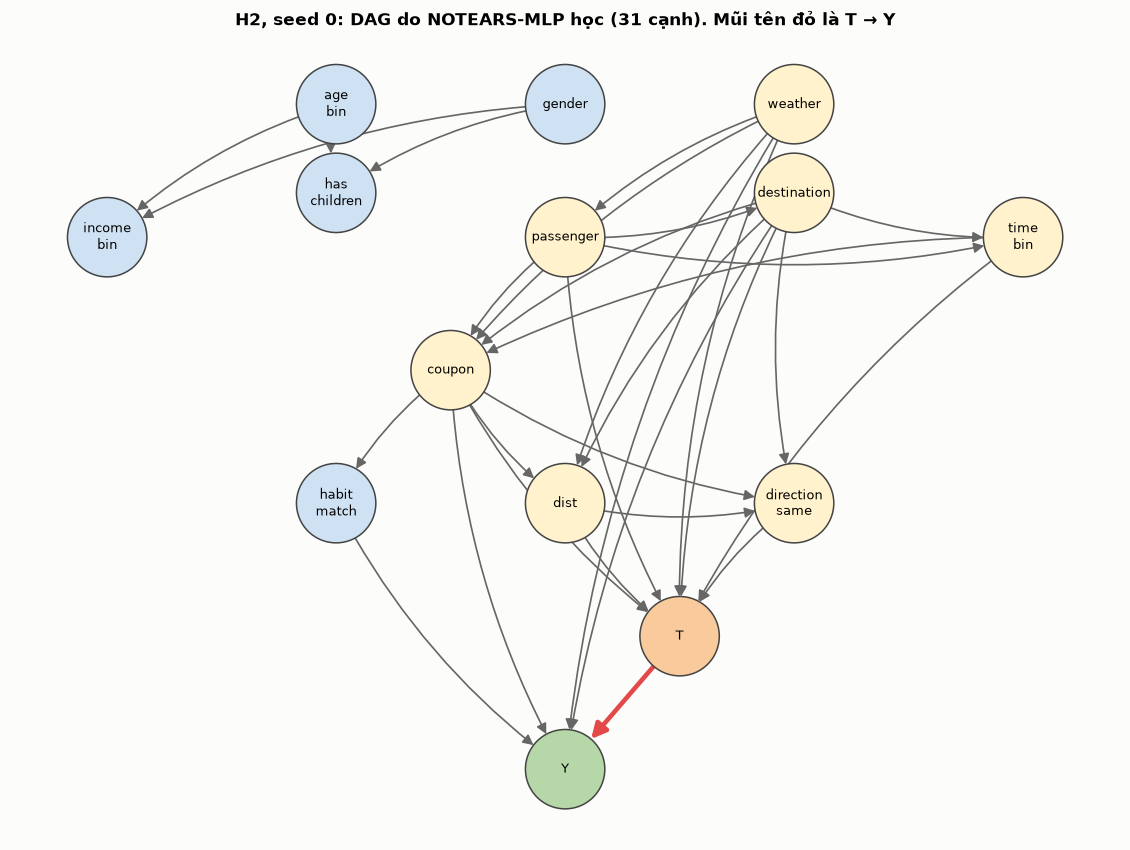

In [29]:
print(f"DAG của H2: {len(H2_0.edges)} cạnh | lỗi ràng buộc: {check_dag(H2_0.edges)} | NOTEARS tự tìm ra T → Y: {H2_0.info['found_TY']}")
print("Cha của Y:", ", ".join(sorted(H2_0.y_parents)))
print("Cha của T:", ", ".join(sorted(H2_0.bn.get_parents("T"))))
edges_b0, edges_h2 = set(B0_0.edges), set(H2_0.edges)
print(f"So với B0: {len(edges_b0 & edges_h2)} cạnh chung, {len(edges_b0 - edges_h2)} cạnh chỉ B0 có, {len(edges_h2 - edges_b0)} cạnh chỉ H2 có.")
draw_dag(H2_0.edges, f"H2, seed 0: DAG do NOTEARS-MLP học ({len(H2_0.edges)} cạnh). Mũi tên đỏ là T → Y")
plt.savefig(OUT / "dag_h2_seed0.png")

DAG đã khác B0 nên phải **nhận diện lại** bằng DoWhy (đề bài yêu cầu: *re-identify if the adjustment set changes*), rồi mới so sánh ba mô hình trên seed 0.

In [30]:
_, ESTIMAND_H2 = dowhy_identify(H2_0.edges, train0)
adjust_dowhy_h2 = sorted(ESTIMAND_H2.get_backdoor_variables())
adjust_model_h2 = sorted(p for p in H2_0.y_parents if p != "T")
print("H2, tập điều chỉnh DoWhy chọn  :", adjust_dowhy_h2, "| chặn hết cửa sau:", backdoor_ok(H2_0.edges, adjust_dowhy_h2))
print("H2, tập điều chỉnh mô hình dùng:", adjust_model_h2, "| chặn hết cửa sau:", backdoor_ok(H2_0.edges, adjust_model_h2))
print("B0, tập điều chỉnh (để so sánh) :", adjust_model)
print("Đối chiếu can thiệp với pgmpy cho H2: lệch lớn nhất =", f"{check_do_with_pgmpy(H2_0, test0)['lệch'].max():.1e}")
pd.DataFrame([summary_row(m, val0, test0) for m in (B0_0, H1_0, H2_0)]).set_index("mô hình").round(4)

H2, tập điều chỉnh DoWhy chọn  : ['coupon', 'destination', 'weather'] | chặn hết cửa sau: True
H2, tập điều chỉnh mô hình dùng: ['coupon', 'destination', 'habit_match', 'weather'] | chặn hết cửa sau: True
B0, tập điều chỉnh (để so sánh) : ['coupon', 'destination', 'direction_same', 'habit_match', 'time_bin']
Đối chiếu can thiệp với pgmpy cho H2: lệch lớn nhất = 1.1e-16


,số cạnh,số cha của Y,số ô bảng Y,auroc,macro_f1,brier,log_loss,threshold,risk_1d,risk_2h,ate
mô hình,,,,,,,,,,,
B0,41,6,540,0.7201,0.6786,0.2093,0.6175,0.50,0.6519,0.4892,-0.1627
H1,41,6,540,0.7324,0.6763,0.2048,0.5986,0.51,0.6585,0.4891,-0.1694
H2,31,5,270,0.7240,0.6840,0.2083,0.6111,0.51,0.6459,0.5015,-0.1443


**Cách đọc kết quả.** Bảng cuối đặt ba mô hình cạnh nhau trên seed 0. Đây mới là **một** cách chia dữ liệu, nên chưa kết luận được mô hình nào hơn: chênh lệch nhỏ có thể chỉ do may rủi của lần chia. Mục 11 lặp lại toàn bộ cho 5 seed để xem chênh lệch nào **lặp lại** được.

<a id="11"></a>
## 11. Chạy 5 lần

**Mục tiêu.** Lặp lại quy trình của mục 8–10 cho cả 5 seed và thu mọi con số cần cho ba bảng kết quả.

Với mỗi seed (một cách chia dữ liệu), hàm `run_seed` làm 6 việc:

| Việc | Hàm | Dùng cho |
|---|---|---|
| 1. Học B0, H1, H2 trên TRAIN và VALIDATION | `build_b0`, `build_h1`, `build_h2` | mọi bảng |
| 2. Chấm dự đoán Y trên TEST | `evaluate_prediction` | Bảng A |
| 3. Tính ATE trên nhóm TEST | `ate_from_table` | Bảng B |
| 4. Bootstrap để có CI 95% của ATE | `bootstrap_ate` | Bảng B |
| 5. DoWhy: nhận diện, ước lượng tham chiếu, 2 refuter | `dowhy_report` | Bảng B, C |
| 6. Thử placebo trên chính mô hình | `placebo_ate` | Bảng C |

**Bootstrap là gì?** Ta chỉ có một bộ dữ liệu. Nếu làm lại khảo sát với nhóm người khác thì ATE sẽ khác đi một chút, nhưng khác bao nhiêu? Bootstrap giả lập việc "làm lại khảo sát": rút ngẫu nhiên **có hoàn lại** đúng bằng số người của TRAIN (có người được rút hai lần, có người không được rút), học lại bảng Y trên mẫu đó, tính lại ATE. Lặp 100 lần được 100 con số ATE. Khoảng chứa 95% số ở giữa (từ phân vị 2,5% đến 97,5%) là **95% confidence interval (CI 95%)**. Theo đề bài: rút theo **người** (vì các dòng của một người không độc lập, giả định G6), **giữ nguyên DAG** và **giữ nguyên nhóm TEST**. CI này vì thế đo độ bất định của CPD, không đo độ bất định của việc tìm DAG.

**Refuter là gì?** Là phép thử "cố tình phá" để xem ước lượng có phản ứng đúng không. Đề bài yêu cầu ít nhất hai phép thử của DoWhy:

- **Placebo treatment:** thay cột T thật bằng một cột T **bị xáo trộn ngẫu nhiên** (không còn liên quan gì đến Y). Hiệu ứng tính lại phải **xấp xỉ 0**. Nếu vẫn ra hiệu ứng lớn thì phương pháp đang "bịa" ra hiệu ứng.
- **Data subset:** bỏ ngẫu nhiên 20% dữ liệu rồi ước lượng lại. Hiệu ứng phải **gần như không đổi**. Nếu đổi nhiều thì kết quả phụ thuộc vào vài dòng cá biệt.

Hai phép thử của DoWhy chạy trên **ước lượng của DoWhy** (hồi quy tuyến tính của Y theo T và adjustment set mà DoWhy tìm được trên DAG đó). Để thử trực tiếp ba mô hình của ta, `placebo_ate` làm phép thử placebo tương tự bằng chính bảng Y của từng mô hình.

In [31]:
def refit_y_table(model: Model, data: pd.DataFrame, val: pd.DataFrame, seed: int) -> pd.DataFrame:
    """Học lại RIÊNG bảng Y của một mô hình trên một bộ dữ liệu khác, giữ nguyên DAG (dùng cho bootstrap và placebo).

    Tham số: model — mô hình gốc; data — bộ dữ liệu thay cho TRAIN; val — VALIDATION (H1 cần để dừng sớm); seed — hạt giống của MLP.
    Trả về: "bảng Y" mới, cùng dạng với model.y_table.
    """
    if model.name == "H1":                                   # H1: huấn luyện lại MLP
        net, _ = train_mlp(onehot(data, model.y_parents), as_int(data["Y"]), onehot(val, model.y_parents), as_int(val["Y"]), seed)
        return mlp_y_table(net, model.y_parents)
    estimator = BayesianEstimator(model.bn, data[NODES], state_names=STATES)     # B0 và H2: đếm lại + BDeu
    return cpd_to_y_table(estimator.estimate_cpd("Y", prior_type="BDeu", equivalent_sample_size=CFG.ess))


def bootstrap_ate(model: Model, train: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame, seed: int) -> np.ndarray:
    """Bootstrap theo người: rút lại người của TRAIN, học lại bảng Y, tính lại ATE trên TEST.

    Tham số: model — mô hình gốc (DAG giữ nguyên); train, val, test — dữ liệu của seed; seed — hạt giống.
    Trả về: mảng CFG.n_boot giá trị ATE. Ba mô hình của cùng seed nhận đúng cùng các mẫu bootstrap.
    """
    rng = np.random.default_rng(seed)
    people = train["resp_id"].unique()
    rows_of = train.groupby("resp_id").indices             # mã người → vị trí các dòng của người đó trong TRAIN
    ates = []
    for _ in range(CFG.n_boot):
        drawn = rng.choice(people, size=len(people), replace=True)               # rút người, có hoàn lại
        boot = train.iloc[np.concatenate([rows_of[person] for person in drawn])].reset_index(drop=True)
        ates.append(ate_from_table(refit_y_table(model, boot, val, seed), test)["ate"])
    return np.array(ates)


def placebo_ate(model: Model, train: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame, seed: int) -> np.ndarray:
    """Placebo trên chính mô hình: xáo trộn cột T của TRAIN, học lại bảng Y, tính lại ATE (kỳ vọng xấp xỉ 0).

    Tham số: như bootstrap_ate().
    Trả về: mảng CFG.n_placebo giá trị ATE giả.
    """
    rng = np.random.default_rng(1000 + seed)
    ates = []
    for _ in range(CFG.n_placebo):
        fake = train.copy()
        fake["T"] = rng.permutation(fake["T"].to_numpy())  # T giả: giữ đủ số coupon 2 giờ nhưng gán bừa cho các dòng
        ates.append(ate_from_table(refit_y_table(model, fake, val, seed), test)["ate"])
    return np.array(ates)


def dowhy_report(edges: list[tuple[str, str]], train: pd.DataFrame, seed: int) -> dict:
    """Chạy trọn bộ DoWhy cho một DAG: nhận diện → ước lượng tham chiếu → hai refuter.

    Tham số: edges — các mũi tên của DAG; train — TRAIN; seed — hạt giống của refuter.
    Trả về: dict gồm tập điều chỉnh, văn bản nhận diện, ATE tham chiếu và kết quả hai refuter (hiệu ứng mới, p-value).
    """
    model, estimand = dowhy_identify(edges, train)
    # Ước lượng tham chiếu: hồi quy tuyến tính của Y theo T và tập điều chỉnh; hệ số của T chính là ATE.
    # need_conditional_estimates=False: tắt một nhánh tính phụ của DoWhy bị lỗi với pandas 3.
    estimate = model.estimate_effect(estimand, method_name="backdoor.linear_regression", control_value=0, treatment_value=1,
                                     target_units="ate", method_params={"need_conditional_estimates": False})
    placebo = model.refute_estimate(estimand, estimate, method_name="placebo_treatment_refuter", placebo_type="permute",
                                    num_simulations=CFG.n_refute, random_seed=seed)
    subset = model.refute_estimate(estimand, estimate, method_name="data_subset_refuter", subset_fraction=CFG.subset_fraction,
                                   num_simulations=CFG.n_refute, random_seed=seed)
    return {"adjust": sorted(estimand.get_backdoor_variables()), "text": str(estimand), "ate": float(estimate.value),
            "placebo_effect": float(placebo.new_effect), "placebo_p": float(placebo.refutation_result["p_value"]),
            "subset_effect": float(subset.new_effect), "subset_p": float(subset.refutation_result["p_value"])}


def save_artifacts(seed: int, models: list[Model], reports: dict) -> None:
    """Lưu mọi thứ đề bài yêu cầu cho một seed: cạnh DAG, bảng Y, checkpoint MLP, ma trận độ mạnh, văn bản nhận diện.

    Tham số: seed — seed vừa chạy; models — [B0, H1, H2]; reports — kết quả dowhy_report() theo tên mô hình.
    """
    for model in models:
        tag = f"{model.name.lower()}_seed{seed}"
        json.dump([list(edge) for edge in model.edges], open(OUT / f"edges_{tag}.json", "w"))
        model.y_table.to_csv(OUT / f"cpd_y_{tag}.csv", index=False)
        if model.name == "B0":
            model.info["ranking"].to_csv(OUT / f"b0_candidates_seed{seed}.csv", index=False)
        if model.name == "H1":
            torch.save(model.info["net"].state_dict(), OUT / f"h1_seed{seed}.pt")
        if model.name == "H2":
            pd.DataFrame(model.info["A"], index=NODES, columns=NODES).to_csv(OUT / f"h2_adjacency_seed{seed}.csv")
            model.info["ranking"].to_csv(OUT / f"h2_thresholds_seed{seed}.csv", index=False)
        if model.name != "H1":                               # H1 dùng chung DAG với B0 nên dùng chung văn bản nhận diện
            (OUT / f"identification_{tag}.txt").write_text(reports[model.name]["text"], encoding="utf-8")


def run_seed(seed: int) -> list[dict]:
    """Chạy toàn bộ quy trình cho một seed.

    Tham số: seed — một seed trong CFG.seeds.
    Trả về: 3 dict (B0, H1, H2), mỗi dict là một dòng của bảng kết quả thô RUNS.
    """
    set_seed(seed)
    train, val, test = get_split(df, SPLITS[seed])
    # ----- 1. Học ba mô hình trên CÙNG dữ liệu -----
    b0 = build_b0(train, val)
    h1 = build_h1(b0, train, val, seed)
    h2 = build_h2(train, val, seed)
    notes = {"B0": b0.info["chosen"], "H1": f"MLP {h1.info['n_params']} trọng số, {len(h1.info['history'])} lượt học",
             "H2": f"{h2.info['chosen']}, tự tìm T → Y: {h2.info['found_TY']}"}
    # ----- 5. DoWhy cho từng DAG (H1 dùng chung DAG với B0) -----
    reports = {"B0": dowhy_report(b0.edges, train, seed)}
    reports["H1"] = reports["B0"]
    reports["H2"] = dowhy_report(h2.edges, train, seed)
    naive = naive_difference(train)["diff"]
    rows = []
    for model in (b0, h1, h2):
        row = {"seed": seed, "model": model.name, "config": notes[model.name], "n_edges": len(model.edges),
               "y_parents": ", ".join(sorted(model.y_parents)), "t_parents": ", ".join(sorted(model.bn.get_parents("T"))),
               "dag_valid": check_dag(model.edges) == [], "fit_seconds": model.fit_seconds}
        row.update(evaluate_prediction(model, val, test))                        # 2. dự đoán
        start = time.time()
        row.update(ate_from_table(model.y_table, test))                          # 3. can thiệp
        row["query_ms"] = 1000 * (time.time() - start)
        boot = bootstrap_ate(model, train, val, test, seed)                      # 4. bootstrap
        row["ci_low"], row["ci_high"], row["boot_sd"] = float(np.quantile(boot, 0.025)), float(np.quantile(boot, 0.975)), float(boot.std(ddof=1))
        adjust = sorted(p for p in model.y_parents if p != "T")
        report = reports[model.name]
        row.update({"adjust_model": ", ".join(adjust), "adjust_ok": backdoor_ok(model.edges, adjust),
                    "adjust_dowhy": ", ".join(report["adjust"]), "ate_dowhy": report["ate"], "naive_train": naive,
                    "dowhy_placebo": report["placebo_effect"], "dowhy_placebo_p": report["placebo_p"],
                    "dowhy_subset": report["subset_effect"], "dowhy_subset_p": report["subset_p"]})
        placebo = placebo_ate(model, train, val, test, seed)                     # 6. placebo trên mô hình
        row["bn_placebo_mean"], row["bn_placebo_max_abs"] = float(placebo.mean()), float(np.abs(placebo).max())
        row["do_check_max_gap"] = float(check_do_with_pgmpy(model, test)["lệch"].max())
        rows.append(row)
    save_artifacts(seed, [b0, h1, h2], reports)
    return rows


start_all = time.time()
all_rows = []
for seed in CFG.seeds:
    start = time.time()
    all_rows += run_seed(seed)
    print(f"seed {seed}: xong sau {time.time() - start:.0f} giây")
RUNS = pd.DataFrame(all_rows)
RUNS.to_csv(OUT / "runs_raw.csv", index=False)
json.dump({"config": asdict(CFG), "quick": QUICK, "tiers": TIERS, "layers": LAYERS, "allowed_parents": ALLOWED_PARENTS, "required_edges": REQUIRED,
           "n_forbidden_edges": len(FORBIDDEN),
           "source": SOURCE, "env": ENV}, open(OUT / "config.json", "w"), ensure_ascii=False, indent=1)
print(f"Tổng thời gian {len(CFG.seeds)} seed: {(time.time() - start_all) / 60:.1f} phút.")
print(f"Mọi DAG hợp lệ: {bool(RUNS['dag_valid'].all())} | mọi tập điều chỉnh chặn hết cửa sau: {bool(RUNS['adjust_ok'].all())} | "
      f"lệch lớn nhất giữa tra bảng và pgmpy do(): {RUNS['do_check_max_gap'].max():.1e}")
with pd.option_context("display.max_colwidth", 80):
    display(RUNS[["seed", "model", "config", "n_edges", "y_parents", "t_parents"]])

seed 0: xong sau 231 giây


seed 1: xong sau 269 giây


seed 2: xong sau 258 giây


seed 3: xong sau 187 giây


seed 4: xong sau 302 giây
Tổng thời gian 5 seed: 20.8 phút.
Mọi DAG hợp lệ: True | mọi tập điều chỉnh chặn hết cửa sau: True | lệch lớn nhất giữa tra bảng và pgmpy do(): 1.1e-16


,seed,model,config,n_edges,y_parents,t_parents
0,0,B0,"HC k2, tối đa 6 cha",41,"T, coupon, destination, direction_same, habit_match, time_bin","coupon, destination, dist, passenger, time_bin, weather"
1,0,H1,"MLP 1153 trọng số, 51 lượt học",41,"T, coupon, destination, direction_same, habit_match, time_bin","coupon, destination, dist, passenger, time_bin, weather"
2,0,H2,"ngưỡng 0.15, tự tìm T → Y: True",31,"T, coupon, destination, habit_match, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather"
3,1,B0,"HC k2, tối đa 6 cha",40,"T, coupon, destination, direction_same, habit_match","coupon, destination, dist, passenger, time_bin, weather"
4,1,H1,"MLP 1057 trọng số, 119 lượt học",40,"T, coupon, destination, direction_same, habit_match","coupon, destination, dist, passenger, time_bin, weather"
5,1,H2,"ngưỡng 0.15, tự tìm T → Y: True",29,"T, coupon, destination, habit_match, weather","coupon, destination, direction_same, dist, passenger, time_bin, weather"
6,2,B0,"HC k2, tối đa 6 cha",41,"T, coupon, destination, direction_same, habit_match, time_bin","coupon, destination, dist, passenger, time_bin, weather"
7,2,H1,"MLP 1153 trọng số, 50 lượt học",41,"T, coupon, destination, direction_same, habit_match, time_bin","coupon, destination, dist, passenger, time_bin, weather"
8,2,H2,"ngưỡng 0.15, tự tìm T → Y: True",30,"T, coupon, destination, habit_match","coupon, destination, direction_same, dist, passenger, time_bin, weather"
9,3,B0,"HC k2, tối đa 4 cha",35,"T, coupon, destination, habit_match","coupon, destination, dist, weather"


**Cách đọc kết quả.** Mỗi seed cho 3 dòng (B0, H1, H2). Cột `config` ghi cấu hình được VALIDATION chọn. So `y_parents` giữa các seed để thấy parent set của Y có ổn định không, và so `t_parents` giữa B0 với H2 để thấy hai cách học DAG có đồng ý về "cái gì quyết định hạn coupon" không. Ba dòng kiểm tra phía trên bảng phải cho `True`, `True` và một độ lệch xấp xỉ 0.

**Kết quả của lần chạy này.**

- Cả 15 mô hình (3 mô hình × 5 seed) đều qua `check_dag`, mọi adjustment set đều chặn hết backdoor path, và "ép T rồi tra bảng" trùng với `do()` của pgmpy (lệch cỡ 10⁻¹⁶, tức sai số làm tròn của máy).
- **B0:** VALIDATION chọn hàm điểm K2 ở cả 5 seed. Y luôn có parents `T`, `coupon`, `destination`, `habit_match`; `direction_same` có thêm ở 4/5 seed, `time_bin` ở 2/5 seed.
- **H2:** ngưỡng 0,15 được chọn ở cả 5 seed, và NOTEARS **tự tìm ra** cạnh T → Y ở cả 5 seed (độ mạnh của cạnh này vượt ngưỡng, không cần luật 10 ép vào). Y luôn có parents `T`, `coupon`, `destination`, `habit_match`; `weather` có thêm ở 2/5 seed (seed 0 và 1). Số parents của Y trong H2 ít hơn hoặc bằng B0 ở mọi seed.
- **Parents của T:** H2 giữ đủ 7 biến kịch bản ở mọi seed. B0 giữ 6 biến ở 4 seed và 4 biến ở seed 3. Hai cách học DAG đồng ý rằng hạn coupon do kịch bản quyết định.
- Ở seed 3, B0 và H2 chọn **cùng** parent set của Y, nên bảng Y, các chỉ số dự đoán và ATE của hai mô hình trùng nhau hoàn toàn.

<a id="12"></a>
## 12. Bảng A: dự đoán

**Mục tiêu.** So khả năng **dự đoán Y** của ba mô hình trên TEST (ôn lại ý nghĩa 4 chỉ số ở mục 8.4).

**Cách so sánh.** Ba mô hình của cùng một seed dùng chung dữ liệu, nên so theo **cặp**: lấy chỉ số của H1 (hoặc H2) trừ chỉ số của B0 **trong từng seed**, rồi nhìn 5 hiệu đó. Cách này loại được phần may rủi do cách chia dữ liệu, vì cả hai mô hình cùng hưởng một "đề dễ" hay cùng chịu một "đề khó".

In [32]:
def mean_sd_table(runs: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Tóm tắt qua các seed: trung bình ± độ lệch chuẩn của từng cột, cho từng mô hình.

    Tham số: runs — bảng kết quả thô; columns — các cột số cần tóm tắt.
    Trả về: bảng 3 dòng (B0, H1, H2), mỗi ô là chuỗi "trung bình ± độ lệch chuẩn".
    """
    rows = []
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name]
        row = {"mô hình": name}
        for col in columns:
            row[col] = f"{part[col].mean():.4f} ± {part[col].std(ddof=1):.4f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("mô hình")


def paired_differences(runs: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Hiệu theo cặp cùng seed: H1 − B0 và H2 − B0 cho từng cột.

    Tham số: runs — bảng kết quả thô; columns — các cột số cần so.
    Trả về: bảng mỗi dòng là một (cột, phép so), gồm hiệu trung bình, độ lệch chuẩn của hiệu, hiệu nhỏ nhất, lớn nhất
            và số seed có hiệu dương.
    """
    rows = []
    for col in columns:
        wide = runs.pivot(index="seed", columns="model", values=col)       # mỗi dòng một seed, mỗi cột một mô hình
        for other in ("H1", "H2"):
            diff = wide[other] - wide["B0"]
            rows.append({"chỉ số": col, "so sánh": f"{other} − B0", "hiệu trung bình": diff.mean(), "độ lệch chuẩn": diff.std(ddof=1),
                         "nhỏ nhất": diff.min(), "lớn nhất": diff.max(), "số seed hiệu > 0": f"{int((diff > 0).sum())}/{len(diff)}"})
    return pd.DataFrame(rows)


METRICS = ["auroc", "macro_f1", "brier", "log_loss"]
TABLE_A = RUNS[["seed", "model"] + METRICS + ["threshold"]]
TABLE_A.to_csv(OUT / "table_A.csv", index=False)
TABLE_A_MEAN = mean_sd_table(RUNS, METRICS)
TABLE_A_PAIRED = paired_differences(RUNS, METRICS)
TABLE_A_MEAN.to_csv(OUT / "table_A_mean_sd.csv")
TABLE_A_PAIRED.to_csv(OUT / "table_A_paired.csv", index=False)
print("Bảng A.1: từng lần chạy (mỗi seed một dòng, mỗi mô hình một nhóm cột)")
display(RUNS.pivot(index="seed", columns="model", values=METRICS).round(4))
print("Bảng A.2: trung bình ± độ lệch chuẩn qua các seed")
display(TABLE_A_MEAN)
print("Bảng A.3: hiệu theo cặp (cùng seed) so với B0")
display(TABLE_A_PAIRED.round(4))

Bảng A.1: từng lần chạy (mỗi seed một dòng, mỗi mô hình một nhóm cột)


auroc                 macro_f1                   brier                 log_loss                
model      B0      H1      H2       B0      H1      H2      B0      H1      H2       B0      H1      H2
seed                                                                                                   
0      0.7201  0.7324  0.7240   0.6786  0.6763  0.6840  0.2093  0.2048  0.2083   0.6175  0.5986  0.6111
1      0.7514  0.7555  0.7553   0.6911  0.6949  0.6959  0.1968  0.1956  0.1960   0.5827  0.5766  0.5844
2      0.7413  0.7421  0.7372   0.6848  0.6880  0.6911  0.2033  0.2020  0.2035   0.5970  0.5906  0.5952
3      0.7365  0.7317  0.7365   0.6834  0.6760  0.6834  0.2042  0.2068  0.2042   0.5963  0.6013  0.5963
4      0.7474  0.7498  0.7460   0.6985  0.6987  0.6911  0.1990  0.1984  0.1999   0.5852  0.5833  0.5866

Bảng A.2: trung bình ± độ lệch chuẩn qua các seed


,auroc,macro_f1,brier,log_loss
mô hình,,,,
B0,0.7394 ± 0.0122,0.6873 ± 0.0077,0.2025 ± 0.0049,0.5957 ± 0.0137
H1,0.7423 ± 0.0105,0.6868 ± 0.0104,0.2015 ± 0.0046,0.5901 ± 0.0103
H2,0.7398 ± 0.0117,0.6891 ± 0.0053,0.2024 ± 0.0046,0.5947 ± 0.0105


Bảng A.3: hiệu theo cặp (cùng seed) so với B0


,chỉ số,so sánh,hiệu trung bình,độ lệch chuẩn,nhỏ nhất,lớn nhất,số seed hiệu > 0
0,auroc,H1 − B0,0.0029,0.0062,-0.0049,0.0123,4/5
1,auroc,H2 − B0,0.0004,0.0035,-0.0041,0.0039,2/5
2,macro_f1,H1 − B0,-0.0005,0.0046,-0.0074,0.0038,3/5
3,macro_f1,H2 − B0,0.0018,0.0057,-0.0075,0.0064,3/5
4,brier,H1 − B0,-0.0010,0.0025,-0.0045,0.0026,1/5
5,brier,H2 − B0,-0.0001,0.0008,-0.0010,0.0009,2/5
6,log_loss,H1 − B0,-0.0057,0.0087,-0.0189,0.0050,1/5
7,log_loss,H2 − B0,-0.0010,0.0033,-0.0064,0.0017,2/5


**Cách đọc bảng.**

- *A.1:* đọc theo hàng ngang để so ba mô hình trong cùng một seed.
- *A.2:* `0,7300 ± 0,0100` nghĩa là trung bình 5 seed là 0,73 và các seed dao động quanh đó khoảng 0,01.
- *A.3:* với AUROC và macro-F1, hiệu **dương** là tốt hơn B0; với Brier và log loss, hiệu **âm** là tốt hơn B0. Một khác biệt đáng tin khi (a) cùng dấu ở hầu hết các seed (cột cuối là 0/5 hoặc 5/5) và (b) hiệu trung bình lớn hơn hẳn độ lệch chuẩn của nó. Chỉ có 5 lần chạy nên đây là bằng chứng mô tả, không phải kiểm định thống kê.

**Kết quả của lần chạy này.**

- Ba mô hình dự đoán **gần như ngang nhau**: AUROC trung bình 0,739 (B0), 0,742 (H1), 0,740 (H2); log loss 0,596, 0,590, 0,595.
- **H1 so với B0:** H1 nhỉnh hơn ở 4/5 seed, cả về AUROC (trung bình +0,003) lẫn log loss (trung bình −0,006). Nhưng hiệu trung bình nhỏ hơn độ lệch chuẩn của chính nó (0,006 và 0,009), và ở seed 3 thì H1 kém hơn B0. Kết luận thận trọng: MLP giúp một chút, chưa đủ để nói là hơn hẳn.
- **H2 so với B0:** không có khác biệt nhất quán (AUROC trung bình xấp xỉ 0: hơn ở 2 seed, bằng ở seed 3, kém ở 2 seed), và ở seed nào hai mô hình cũng lệch nhau không quá 0,004. Lý do: ở mọi seed, H2 cho Y ba parents `coupon`, `destination`, `habit_match` giống B0; hai mô hình chỉ khác nhau ở các parents phụ (`direction_same`, `time_bin`, `weather`).
- Chênh lệch **giữa các seed** (độ lệch chuẩn của AUROC khoảng 0,012) lớn hơn chênh lệch **giữa các mô hình** (khoảng 0,003). Nếu chỉ chạy một seed thì rất dễ kết luận nhầm. Đó là lý do đề bài yêu cầu ít nhất 5 lần chạy theo cặp.
- Một chi tiết khi đọc cột cuối của A.3: ở seed 3, H2 trùng B0 nên hiệu bằng 0 và không được đếm là "hiệu > 0".

<a id="13"></a>
## 13. Bảng B: intervention

**Mục tiêu.** Trả lời câu hỏi của bài: tỉ lệ chấp nhận nếu mọi coupon hạn 1 ngày, nếu mọi coupon hạn 2 giờ, và hiệu của chúng (ATE), kèm CI 95%.

Các cột của bảng:

| Cột | Nghĩa |
|---|---|
| `risk_1d`, `risk_2h` | P(Y = 1 khi do(T = 1 ngày)), P(Y = 1 khi do(T = 2 giờ)), tính trên nhóm TEST |
| `ate` | `risk_2h − risk_1d` |
| `ci_low`, `ci_high` | CI 95% của ATE (bootstrap theo người, DAG cố định) |
| `adjust_model` | adjustment set mô hình dùng = parents của Y trừ T |
| `adjust_dowhy` | adjustment set DoWhy tìm được trên cùng DAG |
| `ate_dowhy` | ATE tham chiếu của DoWhy (hồi quy tuyến tính với `adjust_dowhy`), độc lập với Bayesian Network |
| `naive_train` | hiệu thô trên TRAIN, chưa điều chỉnh (mục 5.1) |

In [33]:
EFFECT_COLS = ["risk_1d", "risk_2h", "ate", "ci_low", "ci_high"]
TABLE_B = RUNS[["seed", "model"] + EFFECT_COLS + ["adjust_model", "adjust_dowhy", "ate_dowhy", "naive_train"]]
TABLE_B.to_csv(OUT / "table_B.csv", index=False)
TABLE_B_MEAN = mean_sd_table(RUNS, ["risk_1d", "risk_2h", "ate", "ci_low", "ci_high", "ate_dowhy", "naive_train"])
TABLE_B_PAIRED = paired_differences(RUNS, ["ate"])
TABLE_B_MEAN.to_csv(OUT / "table_B_mean_sd.csv")
print("Bảng B.1: từng lần chạy")
with pd.option_context("display.max_colwidth", 70):
    display(TABLE_B.round(4))
print("Bảng B.2: trung bình ± độ lệch chuẩn qua các seed")
display(TABLE_B_MEAN)
print("Bảng B.3: hiệu ATE theo cặp (cùng seed) so với B0")
display(TABLE_B_PAIRED.round(4))

Bảng B.1: từng lần chạy


,seed,model,risk_1d,risk_2h,ate,ci_low,ci_high,adjust_model,adjust_dowhy,ate_dowhy,naive_train
0,0,B0,0.6519,0.4892,-0.1627,-0.1908,-0.1424,"coupon, destination, direction_same, habit_match, time_bin","coupon, destination, direction_same, habit_match, time_bin",-0.1674,-0.1468
1,0,H1,0.6585,0.4891,-0.1694,-0.1964,-0.1501,"coupon, destination, direction_same, habit_match, time_bin","coupon, destination, direction_same, habit_match, time_bin",-0.1674,-0.1468
2,0,H2,0.6459,0.5015,-0.1443,-0.1681,-0.1242,"coupon, destination, habit_match, weather","coupon, destination, weather",-0.1670,-0.1468
3,1,B0,0.6353,0.4810,-0.1542,-0.1821,-0.1356,"coupon, destination, direction_same, habit_match","coupon, destination, direction_same, habit_match",-0.1639,-0.1433
4,1,H1,0.6354,0.4773,-0.1581,-0.1817,-0.1349,"coupon, destination, direction_same, habit_match","coupon, destination, direction_same, habit_match",-0.1639,-0.1433
5,1,H2,0.6295,0.4843,-0.1452,-0.1725,-0.1240,"coupon, destination, habit_match, weather","coupon, destination, weather",-0.1635,-0.1433
6,2,B0,0.6553,0.4797,-0.1756,-0.2020,-0.1559,"coupon, destination, direction_same, habit_match, time_bin","coupon, destination, direction_same, habit_match, time_bin",-0.1803,-0.1568
7,2,H1,0.6479,0.4806,-0.1673,-0.1946,-0.1510,"coupon, destination, direction_same, habit_match, time_bin","coupon, destination, direction_same, habit_match, time_bin",-0.1803,-0.1568
8,2,H2,0.6638,0.4876,-0.1762,-0.2017,-0.1562,"coupon, destination, habit_match","coupon, destination",-0.1736,-0.1568
9,3,B0,0.6603,0.4817,-0.1785,-0.1993,-0.1549,"coupon, destination, habit_match","coupon, destination, habit_match",-0.1720,-0.1583


Bảng B.2: trung bình ± độ lệch chuẩn qua các seed


,risk_1d,risk_2h,ate,ci_low,ci_high,ate_dowhy,naive_train
mô hình,,,,,,,
B0,0.6506 ± 0.0094,0.4864 ± 0.0085,-0.1643 ± 0.0125,-0.1896 ± 0.0118,-0.1438 ± 0.0114,-0.1690 ± 0.0074,-0.1493 ± 0.0078
H1,0.6486 ± 0.0096,0.4856 ± 0.0066,-0.1630 ± 0.0056,-0.1869 ± 0.0079,-0.1426 ± 0.0079,-0.1690 ± 0.0074,-0.1493 ± 0.0078
H2,0.6509 ± 0.0137,0.4908 ± 0.0089,-0.1601 ± 0.0165,-0.1848 ± 0.0153,-0.1386 ± 0.0159,-0.1669 ± 0.0067,-0.1493 ± 0.0078


Bảng B.3: hiệu ATE theo cặp (cùng seed) so với B0


,chỉ số,so sánh,hiệu trung bình,độ lệch chuẩn,nhỏ nhất,lớn nhất,số seed hiệu > 0
0,ate,H1 − B0,0.0013,0.0097,-0.0067,0.0148,2/5
1,ate,H2 − B0,0.0042,0.0096,-0.0059,0.0184,2/5


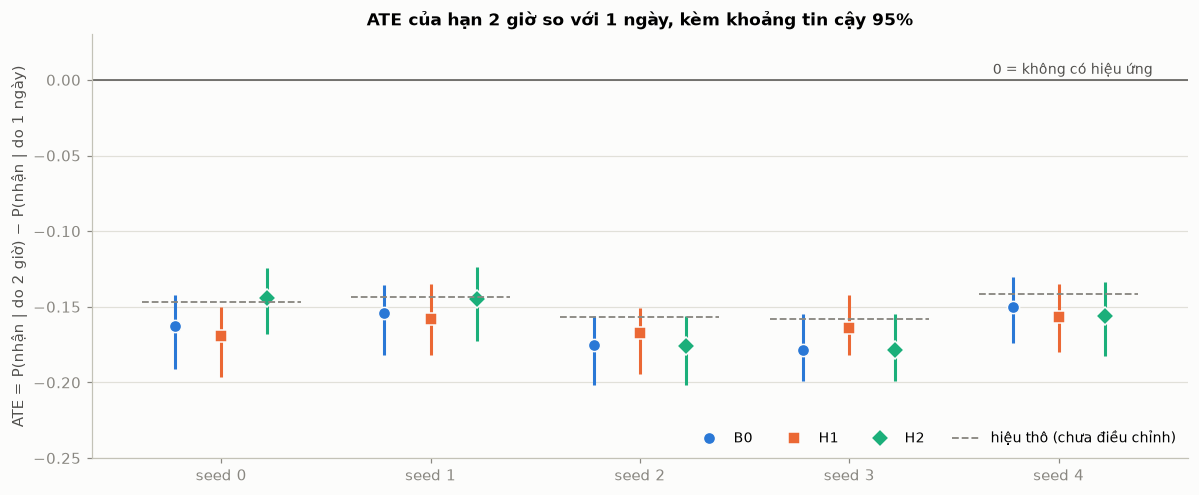

In [34]:
def plot_ate(runs: pd.DataFrame) -> None:
    """Vẽ ATE của ba mô hình ở từng seed, kèm khoảng tin cậy 95%; đường xám là hiệu thô chưa điều chỉnh.

    Tham số: runs — bảng kết quả thô.
    """
    seeds = sorted(runs["seed"].unique())
    offsets = {"B0": -0.22, "H1": 0.0, "H2": 0.22}            # đặt ba mô hình lệch nhau một chút để không đè lên nhau
    fig, ax = plt.subplots(figsize=(11, 4.6))
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name].set_index("seed").loc[seeds]
        x = np.arange(len(seeds)) + offsets[name]
        ax.vlines(x, part["ci_low"], part["ci_high"], color=COLOR[name], linewidth=2)            # thanh dọc = CI 95%
        ax.plot(x, part["ate"], MARKER[name], color=COLOR[name], markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=1, label=name)
    naive = runs.groupby("seed")["naive_train"].first().loc[seeds].to_numpy()
    ax.hlines(naive, np.arange(len(seeds)) - 0.38, np.arange(len(seeds)) + 0.38, color=MUTED, linewidth=1.2, linestyle="--", label="hiệu thô (chưa điều chỉnh)")
    ax.axhline(0, color=INK_SOFT, linewidth=1)
    ax.text(len(seeds) - 0.55, 0.004, "0 = không có hiệu ứng", color=INK_SOFT, ha="right", fontsize=9)
    ax.set_xticks(np.arange(len(seeds)))
    ax.set_xticklabels([f"seed {s}" for s in seeds])
    ax.set_ylabel("ATE = P(nhận | do 2 giờ) − P(nhận | do 1 ngày)")
    ax.set_title("ATE của hạn 2 giờ so với 1 ngày, kèm khoảng tin cậy 95%")
    ax.set_ylim(min(-0.25, float(runs["ci_low"].min()) - 0.02), 0.03)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower right", ncol=4, fontsize=9)
    fig.tight_layout()
    fig.savefig(OUT / "ate_by_seed.png")


plot_ate(RUNS)

**Cách đọc bảng và hình.**

- Mỗi chấm là ATE của một mô hình ở một seed; thanh dọc là CI 95%. Thanh **không chạm vạch 0** nghĩa là với mức tin cậy 95%, hiệu ứng khác 0.
- Ba chấm của cùng một seed nằm gần nhau và các thanh chồng lên nhau nghĩa là ba mô hình **đồng ý** về hiệu ứng.
- Vạch xám đứt là hiệu thô. Khoảng cách giữa vạch xám và các chấm là phần lệch do confounding mà việc điều chỉnh đã sửa.
- `ate_dowhy` là một ước lượng độc lập (hồi quy tuyến tính thay cho Bayesian Network). Nó gần với ATE của ba mô hình thì kết luận ít phụ thuộc vào cách mô hình hoá.

**Kết quả của lần chạy này.**

- Nếu mọi coupon có hạn 1 ngày, khoảng **65%** được chấp nhận. Nếu mọi coupon có hạn 2 giờ, chỉ còn khoảng **49%**. ATE trung bình là −0,164 (B0), −0,163 (H1) và −0,160 (H2).
- **Cả 15 CI 95% đều nằm hẳn dưới 0.** Trung bình qua 5 seed, CI 95% của B0 là [−0,190; −0,144], tức rộng khoảng ±0,023 quanh ước lượng.
- **Ba mô hình đồng ý với nhau:** hiệu ATE theo cặp là +0,001 (H1 − B0) và +0,004 (H2 − B0), đều nhỏ hơn nhiều so với độ rộng ±0,023 của CI.
- **Điều chỉnh có tác dụng:** hiệu thô là −0,149, còn ATE đã điều chỉnh là khoảng −0,16. Chiều lệch giống phép tính tay ở mục 5.3.
- **Ước lượng độc lập của DoWhy** (hồi quy tuyến tính) cho −0,169 trên DAG của B0 và −0,167 trên DAG của H2, cùng cỡ với ba mô hình.
- **Adjustment set:** trên DAG của B0, DoWhy tìm ra đúng tập mà mô hình dùng (parents của Y trừ T) ở cả 5 seed. Trên DAG của H2, tập của DoWhy ở cả 5 seed là tập của mô hình bỏ đi `habit_match`. Cả hai tập đều chặn hết backdoor path nên đều hợp lệ; chúng chỉ khác nhau ở một biến không bắt buộc phải điều chỉnh.

<a id="14"></a>
## 14. Bảng C: độ tin cậy và chi phí

**Mục tiêu.** Trả lời ba câu hỏi phụ mà đề bài yêu cầu: (C.1) kết quả có **ổn định** qua các lần chạy không; (C.2, C.3) ước lượng có **qua được các phép thử phá** không; (C.4) mỗi mô hình **tốn bao nhiêu thời gian**.

In [35]:
def stability_table(runs: pd.DataFrame) -> pd.DataFrame:
    """C.1: độ ổn định của cấu trúc và của ATE qua các seed, cho từng mô hình.

    Tham số: runs — bảng kết quả thô.
    Trả về: bảng 3 dòng (B0, H1, H2).
    """
    rows = []
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name]
        common = part["y_parents"].value_counts()
        rows.append({"mô hình": name, "số cạnh (ít nhất – nhiều nhất)": f"{part['n_edges'].min()} – {part['n_edges'].max()}",
                     "số bộ cha của Y khác nhau": part["y_parents"].nunique(),
                     "bộ cha của Y hay gặp nhất": f"{common.index[0]} ({common.iloc[0]}/{len(part)} seed)",
                     "ATE trung bình": part["ate"].mean(), "ATE độ lệch chuẩn": part["ate"].std(ddof=1),
                     "ATE nhỏ nhất": part["ate"].min(), "ATE lớn nhất": part["ate"].max(),
                     "số seed ATE < 0": f"{int((part['ate'] < 0).sum())}/{len(part)}",
                     "số seed CI không chứa 0": f"{int(((part['ci_high'] < 0) | (part['ci_low'] > 0)).sum())}/{len(part)}"})
    return pd.DataFrame(rows).set_index("mô hình")


def refuter_table(runs: pd.DataFrame) -> pd.DataFrame:
    """C.2: kết quả hai refuter của DoWhy cho từng DAG ở từng seed (H1 dùng chung DAG với B0 nên không lặp lại).

    Tham số: runs — bảng kết quả thô.
    Trả về: bảng mỗi dòng là một (seed, DAG), kèm cột đạt hay không đạt cho từng phép thử.
    """
    part = runs[runs["model"] != "H1"]
    out = pd.DataFrame({"seed": part["seed"], "DAG của": part["model"], "tập điều chỉnh DoWhy": part["adjust_dowhy"],
                        "ATE DoWhy": part["ate_dowhy"], "placebo: hiệu ứng mới": part["dowhy_placebo"], "placebo: p-value": part["dowhy_placebo_p"],
                        "subset: hiệu ứng mới": part["dowhy_subset"], "subset: p-value": part["dowhy_subset_p"]})
    # Đạt placebo: hiệu ứng giả nhỏ hơn 10% hiệu ứng thật. Đạt subset: hiệu ứng mới lệch dưới 10% so với hiệu ứng thật.
    out["placebo đạt"] = out["placebo: hiệu ứng mới"].abs() < 0.1 * out["ATE DoWhy"].abs()
    out["subset đạt"] = (out["subset: hiệu ứng mới"] - out["ATE DoWhy"]).abs() < 0.1 * out["ATE DoWhy"].abs()
    return out.reset_index(drop=True)


def cost_table(runs: pd.DataFrame) -> pd.DataFrame:
    """C.3 và C.4: placebo trên chính mô hình, thời gian học và thời gian truy vấn, trung bình qua các seed.

    Tham số: runs — bảng kết quả thô.
    Trả về: bảng 3 dòng (B0, H1, H2).
    """
    rows = []
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name]
        rows.append({"mô hình": name, "ATE thật (trung bình)": part["ate"].mean(),
                     "ATE placebo (trung bình)": part["bn_placebo_mean"].mean(), "|ATE placebo| lớn nhất": part["bn_placebo_max_abs"].max(),
                     "thời gian học (giây)": part["fit_seconds"].mean(), "thời gian truy vấn do() trên TEST (ms)": part["query_ms"].mean()})
    return pd.DataFrame(rows).set_index("mô hình")


TABLE_C1, TABLE_C2, TABLE_C34 = stability_table(RUNS), refuter_table(RUNS), cost_table(RUNS)
TABLE_C1.to_csv(OUT / "table_C1_stability.csv")
TABLE_C2.to_csv(OUT / "table_C2_dowhy_refuters.csv", index=False)
TABLE_C34.to_csv(OUT / "table_C3_C4_placebo_cost.csv")
print("Bảng C.1: độ ổn định qua các lần chạy")
with pd.option_context("display.max_colwidth", 90):
    display(TABLE_C1.round(4))
print(f"Bảng C.2: hai refuter của DoWhy ({CFG.n_refute} lần mô phỏng mỗi phép thử)")
with pd.option_context("display.max_colwidth", 60):
    display(TABLE_C2.round(4))
print(f"Bảng C.3 và C.4: placebo trên chính mô hình ({CFG.n_placebo} lần xáo trộn T mỗi seed) và chi phí")
display(TABLE_C34.round(4))
print(f"Phần cứng: {ENV['máy']}, {ENV['số lõi CPU']} lõi CPU, GPU: {ENV['GPU (cuda)']}. Thời gian học của B0 gồm cả 6 lần Hill Climbing và bước chọn;"
      f" của H1 chỉ gồm huấn luyện MLP (DAG lấy từ B0); của H2 gồm NOTEARS và bước chọn ngưỡng.")

Bảng C.1: độ ổn định qua các lần chạy


,số cạnh (ít nhất – nhiều nhất),số bộ cha của Y khác nhau,bộ cha của Y hay gặp nhất,ATE trung bình,ATE độ lệch chuẩn,ATE nhỏ nhất,ATE lớn nhất,số seed ATE < 0,số seed CI không chứa 0
mô hình,,,,,,,,,
B0,35 – 41,3,"T, coupon, destination, direction_same, habit_match, time_bin (2/5 seed)",-0.1643,0.0125,-0.1785,-0.1503,5/5,5/5
H1,35 – 41,3,"T, coupon, destination, direction_same, habit_match, time_bin (2/5 seed)",-0.1630,0.0056,-0.1694,-0.1565,5/5,5/5
H2,29 – 31,2,"T, coupon, destination, habit_match (3/5 seed)",-0.1601,0.0165,-0.1785,-0.1443,5/5,5/5


Bảng C.2: hai refuter của DoWhy (100 lần mô phỏng mỗi phép thử)


,seed,DAG của,tập điều chỉnh DoWhy,ATE DoWhy,placebo: hiệu ứng mới,placebo: p-value,subset: hiệu ứng mới,subset: p-value,placebo đạt,subset đạt
0,0,B0,"coupon, destination, direction_same, habit_match, time_bin",-0.1674,-0.0011,0.92,-0.1669,0.92,True,True
1,0,H2,"coupon, destination, weather",-0.1670,-0.0010,0.92,-0.1665,0.92,True,True
2,1,B0,"coupon, destination, direction_same, habit_match",-0.1639,0.0014,0.94,-0.1644,0.96,True,True
3,1,H2,"coupon, destination, weather",-0.1635,0.0014,0.92,-0.1640,0.94,True,True
4,2,B0,"coupon, destination, direction_same, habit_match, time_bin",-0.1803,0.0007,0.92,-0.1803,1.00,True,True
5,2,H2,"coupon, destination",-0.1736,0.0006,0.94,-0.1734,0.98,True,True
6,3,B0,"coupon, destination, habit_match",-0.1720,-0.0022,0.94,-0.1720,0.96,True,True
7,3,H2,"coupon, destination",-0.1729,-0.0021,0.88,-0.1728,0.94,True,True
8,4,B0,"coupon, destination, direction_same, habit_match",-0.1615,0.0018,0.82,-0.1616,0.98,True,True
9,4,H2,"coupon, destination",-0.1576,0.0018,0.84,-0.1578,0.98,True,True


Bảng C.3 và C.4: placebo trên chính mô hình (20 lần xáo trộn T mỗi seed) và chi phí


,ATE thật (trung bình),ATE placebo (trung bình),|ATE placebo| lớn nhất,thời gian học (giây),thời gian truy vấn do() trên TEST (ms)
mô hình,,,,,
B0,-0.1643,-0.0008,0.0238,3.2430,7.8477
H1,-0.1630,-0.0032,0.0256,3.1218,6.0218
H2,-0.1601,-0.0006,0.0238,83.7274,3.5470


Phần cứng: macOS-27.0.1-arm64-arm-64bit-Mach-O, 8 lõi CPU, GPU: False. Thời gian học của B0 gồm cả 6 lần Hill Climbing và bước chọn; của H1 chỉ gồm huấn luyện MLP (DAG lấy từ B0); của H2 gồm NOTEARS và bước chọn ngưỡng.


**Cách đọc bảng.**

- *C.1:* `số bộ cha của Y khác nhau` = 1 nghĩa là seed nào cũng chọn cùng một parent set cho Y. `ATE độ lệch chuẩn` nhỏ và mọi seed cùng dấu thì kết luận không phụ thuộc vào cách chia dữ liệu.
- *C.2:* phép thử placebo **đạt** khi hiệu ứng mới xấp xỉ 0 (ở đây: nhỏ hơn 10% hiệu ứng thật). Phép thử subset **đạt** khi hiệu ứng mới gần hiệu ứng thật (lệch dưới 10%). Về `p-value` của DoWhy: nó trả lời câu hỏi "kết quả có khớp với điều kỳ vọng không", nên p-value **lớn** (trên 0,05) là tốt, ngược với thói quen đọc p-value thông thường.
- *C.3:* cũng là phép thử placebo, nhưng làm trực tiếp trên bảng Y của từng mô hình. `ATE placebo` phải nhỏ hơn hẳn `ATE thật`.
- *C.4:* thời gian truy vấn rất nhỏ vì intervention chỉ là tra bảng.

**Kết quả của lần chạy này.**

- **C.1 Ổn định:** với cả ba mô hình, ATE âm ở 5/5 seed và CI không chứa 0 ở 5/5 seed. Độ lệch chuẩn của ATE qua các seed là 0,013 (B0), 0,006 (H1), 0,016 (H2), nhỏ so với độ lớn 0,16 của hiệu ứng. Cấu trúc thì kém ổn định hơn: qua 5 seed, B0 cho 3 parent set của Y khác nhau, H2 cho 2. ATE vẫn gần như không đổi vì `coupon`, `destination` và `habit_match` luôn có mặt ở cả hai cách học DAG; các seed chỉ khác nhau ở các parents phụ (`direction_same`, `time_bin` với B0; `weather` với H2). Điều này khớp với mục 5.3, nơi riêng `coupon` đã sửa phần lớn độ lệch của so sánh thô.
- **C.2 Refuter của DoWhy:** đạt ở cả 10 trường hợp (5 seed × 2 DAG). Với T bị xáo trộn, hiệu ứng rơi về trong khoảng ±0,002 (hiệu ứng thật là −0,17). Khi bỏ 20% dữ liệu, hiệu ứng lệch không quá 0,001. Mọi p-value đều từ 0,80 trở lên.
- **C.3 Placebo trên mô hình:** ATE placebo trung bình xấp xỉ 0 (từ −0,003 đến −0,001). Giá trị xa 0 nhất trong 100 lần xáo trộn của mỗi mô hình là khoảng 0,025, vẫn nhỏ hơn ATE thật hơn 6 lần.
- **C.4 Chi phí:** trong lần chạy này, học B0 mất khoảng 3 giây, H1 cần thêm khoảng 3 giây để huấn luyện MLP, H2 mất khoảng 84 giây. Intervention query trên cả nhóm TEST mất 4–8 mili giây. 5 seed chạy hết khoảng 21 phút trên CPU 8 lõi, không cần GPU. Các con số này **không so được** với notebook 04 (2 giây; 0,5 giây; 11 giây; 5 seed hết 5,4 phút): lần chạy này diễn ra khi máy đang bận việc khác. Bằng chứng là H1 huấn luyện đúng cùng một mạng với cùng số lượt học như notebook 04 mà thời gian huấn luyện trung bình vẫn dài hơn khoảng 6 lần (từ 1,2 đến 12 lần tuỳ seed). Điều đọc được chỉ là thứ tự: H2 tốn thời gian nhất.

Cần nhớ giới hạn của các phép thử này: chúng phát hiện lỗi của **phương pháp ước lượng** (bịa ra hiệu ứng, phụ thuộc vào vài dòng cá biệt), nhưng **không** phát hiện được confounder bị bỏ sót (giả định G2).

<a id="15"></a>
## 15. Kết luận

Ô dưới đây gom các con số chính từ ba bảng để phần kết luận luôn khớp với lần chạy hiện tại.

In [36]:
def final_summary(runs: pd.DataFrame) -> pd.DataFrame:
    """Gom các con số chính của ba mô hình (trung bình qua các seed) thành một bảng để viết kết luận.

    Tham số: runs — bảng kết quả thô.
    Trả về: bảng 3 dòng (B0, H1, H2).
    """
    rows = []
    for name in ("B0", "H1", "H2"):
        part = runs[runs["model"] == name]
        rows.append({"mô hình": name, "AUROC": part["auroc"].mean(), "log loss": part["log_loss"].mean(),
                     "P(nhận | do 1 ngày)": part["risk_1d"].mean(), "P(nhận | do 2 giờ)": part["risk_2h"].mean(),
                     "ATE": part["ate"].mean(), "CI 95% thấp (trung bình)": part["ci_low"].mean(), "CI 95% cao (trung bình)": part["ci_high"].mean(),
                     "thời gian học (giây)": part["fit_seconds"].mean()})
    return pd.DataFrame(rows).set_index("mô hình")


SUMMARY = final_summary(RUNS)
SUMMARY.to_csv(OUT / "summary.csv")
print(f"Hiệu thô trên TRAIN (trung bình các seed): {RUNS.groupby('seed')['naive_train'].first().mean():+.4f} | "
      f"ATE DoWhy trên DAG của B0: {RUNS[RUNS['model'] == 'B0']['ate_dowhy'].mean():+.4f} | trên DAG của H2: {RUNS[RUNS['model'] == 'H2']['ate_dowhy'].mean():+.4f}")
SUMMARY.round(4)

Hiệu thô trên TRAIN (trung bình các seed): -0.1493 | ATE DoWhy trên DAG của B0: -0.1690 | trên DAG của H2: -0.1669


,AUROC,log loss,P(nhận | do 1 ngày),P(nhận | do 2 giờ),ATE,CI 95% thấp (trung bình),CI 95% cao (trung bình),thời gian học (giây)
mô hình,,,,,,,,
B0,0.7394,0.5957,0.6506,0.4864,-0.1643,-0.1896,-0.1438,3.2430
H1,0.7423,0.5901,0.6486,0.4856,-0.1630,-0.1869,-0.1426,3.1218
H2,0.7398,0.5947,0.6509,0.4908,-0.1601,-0.1848,-0.1386,83.7274


**Đặt hạn coupon 2 giờ thay cho 1 ngày làm giảm xác suất tài xế chấp nhận coupon khoảng 16 điểm phần trăm: từ khoảng 65% xuống khoảng 49%.**

| Bằng chứng | Kết quả | Xem ở |
|---|---|---|
| Ba mô hình cho cùng câu trả lời | ATE = −0,164 (B0), −0,163 (H1), −0,160 (H2) | Bảng B |
| Hiệu ứng khác 0 một cách rõ ràng | cả 15 CI 95% nằm dưới 0; CI trung bình của B0 là [−0,190; −0,144] | Bảng B |
| Không phụ thuộc cách chia dữ liệu | ATE âm ở 5/5 seed, độ lệch chuẩn qua các seed từ 0,006 đến 0,016 | Bảng C.1 |
| Một phương pháp độc lập đồng ý | DoWhy (hồi quy tuyến tính): −0,169 và −0,167 | Bảng B |
| Phương pháp không "bịa" ra hiệu ứng | xáo trộn T thì hiệu ứng về xấp xỉ 0; bỏ 20% dữ liệu thì hiệu ứng không đổi | Bảng C.2, C.3 |
| Khớp với phép tính tay | điều chỉnh theo loại quán và điểm đến bằng pandas: −0,159 (seed 0) | mục 5.3 |

Con số này chỉ được đọc là **hiệu ứng nhân quả** khi các giả định ở mục 2.3 đúng, quan trọng nhất là G2 (không còn nguyên nhân chung nào của T và Y bị bỏ sót). Dữ liệu ủng hộ G1 (mục 5.4) nhưng không thể chứng minh G2.

### 15.2 So sánh ba mô hình

| | B0 | H1 | H2 |
|---|---|---|---|
| Khác B0 ở đâu | (mốc so sánh) | bảng Y tính bằng MLP | DAG học bằng NOTEARS-MLP |
| AUROC | 0,739 | 0,742 | 0,740 |
| Log loss | 0,596 | 0,590 | 0,595 |
| ATE | −0,164 | −0,163 | −0,160 |
| Độ lệch chuẩn của ATE qua 5 seed | 0,013 | 0,006 | 0,016 |
| Thời gian học (máy đang bận, xem Bảng C.4) | 3,2 giây | 3,1 giây (cộng DAG của B0) | 83,7 giây |

- **H1 (thay bảng đếm bằng MLP):** dự đoán nhỉnh hơn B0 ở 4/5 seed nhưng mức hơn rất nhỏ (AUROC +0,003), còn ATE gần như trùng B0. Hai mô hình khác nhau chủ yếu ở các ô không có dữ liệu, nơi bảng đếm chỉ trả về 0,5 còn MLP ngoại suy từ các ô tương tự. ATE của H1 cũng ít dao động giữa các seed nhất, dù với 5 lần chạy thì đây mới là quan sát, chưa phải kết luận chắc chắn.
- **H2 (học DAG bằng NOTEARS-MLP):** tự tìm ra cạnh T → Y ở 5/5 seed và giữ đủ các mũi tên kịch bản → T. H2 chọn cho Y ít parents hơn hoặc bằng B0, dự đoán ngang B0, ATE gần 0 hơn một chút (−0,160), và là mô hình tốn thời gian học nhất (gấp khoảng 26 lần B0 trong lần chạy này, khoảng 5 lần trong notebook 04).
- **Bài học chung:** trên bộ dữ liệu nhỏ, toàn biến phân loại như bộ này, thay thành phần truyền thống bằng neural network **không làm đổi kết luận nhân quả**. Giá trị chính của H1 và H2 ở đây là vai trò kiểm tra chéo: hai cách tính CPD và hai cách học DAG khác hẳn nhau, dưới cùng ràng buộc, đi đến cùng một câu trả lời. Nếu chỉ được chọn một mô hình thì B0 là đủ: đơn giản nhất, nhanh, và mọi con số đều lần ngược được về phép đếm.

### 15.3 Hạn chế

1. **Giả định G2 không kiểm chứng được.** Dữ liệu không ghi lại quy tắc mà bảng hỏi dùng để gán hạn coupon. Nếu quy tắc đó liên quan đến một yếu tố ảnh hưởng Y mà 12 biến của ta không có, ATE sẽ bị chệch. Các refuter không phát hiện được chuyện này.
2. **Y là ý định khai trong tình huống giả định (G5),** không phải hành vi thật. Hiệu ứng ngoài đời có thể khác.
3. **Chỉ có 580 người trả lời,** mỗi người trả lời nhiều dòng. Bootstrap đã rút theo người, nhưng CI ở Bảng B được tính với **DAG giữ cố định**, nên chưa gồm phần bất định của việc tìm DAG. Phần đó chỉ thấy được qua dao động giữa 5 seed (Bảng C.1).
4. **Bảng Y thưa:** ở seed 0, 351/540 ô của B0 không có dòng TRAIN nào. B0 trả về 0,5 ở các ô đó, còn H1 ngoại suy từ các ô tương tự. Cả hai đều không có dữ liệu để kiểm chứng tại đó.
5. **H2 có một lựa chọn chủ động:** phạt L1 cho các cạnh đi vào T được giảm 10 lần (mục 10), con số lấy từ bản đầy đủ trước đó chứ không dò lại ở đây. Cạnh T → Y cũng là cạnh bắt buộc, dù trong lần chạy này NOTEARS tự tìm ra nó ở cả 5 seed.
6. **Rời rạc hoá:** tuổi, thu nhập, giờ trong ngày được gộp thành 3–4 mức. Cách gộp khác có thể cho CPD khác.
7. **Ước lượng tham chiếu của DoWhy** dùng hồi quy tuyến tính cho Y nhị phân, và coi các dòng là độc lập. Nó chỉ dùng để đối chiếu.
8. **Chỉ 5 lần chạy:** các so sánh giữa ba mô hình là bằng chứng mô tả, không phải kiểm định thống kê.
9. **Bộ luật ở mục 6 là hiểu biết đưa vào, không phải điều dữ liệu chứng minh.** Chiều của các mũi tên giữa những biến kịch bản (ví dụ bối cảnh → coupon) là quy ước mô hình hoá: trong bảng hỏi, cả tình huống lẫn coupon được tạo ra cùng lúc. Các luật này không đụng đến parents được phép của T và của Y, nên không trực tiếp quyết định adjustment set.


### 15.4 Bộ luật chặt hơn làm đổi gì so với notebook 04

Notebook 04 dùng bộ luật 4 tầng (cấm 65/182 mũi tên); notebook này cấm 127/182. Cùng dữ liệu, cùng 5 cách chia, cùng cấu hình (trừ `h2_h_tol`, xem cuối mục). Các con số dưới đây lấy từ `artifacts/coupon_simple/` và `artifacts/coupon_rules/`.

| | Luật cũ (notebook 04) | Luật mới (notebook này) |
|---|---|---|
| Số mũi tên bị cấm | 65/182 | 127/182 |
| B0: số cạnh của DAG (trung bình 5 seed) | 40,8 | 39,4 |
| B0: số cạnh mà luật mới coi là vô lý | 13,8 | 0 |
| H2: số cạnh của DAG (trung bình 5 seed) | 30,2 | 30,0 |
| H2: số cạnh mà luật mới coi là vô lý | 7,4 | 0 |
| B0: ATE / AUROC | −0,164 / 0,739 | −0,164 / 0,739 |
| H1: ATE / AUROC | −0,163 / 0,742 | −0,163 / 0,742 |
| H2: ATE / AUROC | −0,156 / 0,736 | −0,160 / 0,740 |
| H2 − B0: hiệu ATE theo cặp | +0,008 | +0,004 |
| H2: độ lệch chuẩn của ATE qua 5 seed | 0,014 | 0,016 |
| H2: số parent set của Y khác nhau | 3 | 2 |

- **Các cạnh vô lý đã biến mất.** Trong notebook 04, DAG của B0 có `passenger → weather`, `destination → weather`, `time_bin → weather`, `has_children → age_bin`, `habit_match → coupon` ở cả 5 seed; DAG của H2 có `coupon → time_bin`, `coupon → destination`, `dist → destination`, `dist → passenger`, `habit_match → coupon` ở cả 5 seed. Khoảng một phần ba số cạnh của B0 và một phần tư số cạnh của H2 thuộc loại này.
- **B0 và H1 không đổi một con số nào về Y.** Parents của T và parents của Y giống hệt notebook 04 ở cả 5 seed, nên Bảng A, Bảng B và các phép thử placebo của hai mô hình này trùng với notebook 04. Lý do: các cạnh vô lý đều nằm giữa các covariates với nhau, còn bộ luật mới không thu hẹp parents được phép của T và của Y.
- **H2 đổi parents của Y ở 2/5 seed:** seed 2 bỏ `weather`, seed 4 thêm `destination`. Sau thay đổi, Y của H2 luôn có `coupon`, `destination`, `habit_match` như B0, nên H2 tiến gần B0 hơn cả về ATE (hiệu theo cặp +0,008 → +0,004) lẫn dự đoán (AUROC 0,736 → 0,740). Đổi lại, ATE của H2 dao động giữa các seed nhiều hơn một chút (0,014 → 0,016) vì ATE ở seed 2 đổi từ −0,157 sang −0,176.
- **Cái giá:** mạng mô tả 14 biến kém đi một chút. Ở seed 0, log-likelihood trên VALIDATION của DAG mà B0 chọn giảm từ −9,95 xuống −10,25. Các liên hệ giữa covariates giờ phải vẽ theo chiều có nghĩa, và chiều đó đôi khi cần bảng CPD lớn hơn (ví dụ `habit_match` nhận tới 5 parents). Với H2 thì con số này lại nhích lên (−10,39 → −10,25).
- **PC** (chỉ chạy thử ở mục 8.1) giữ được 6 cạnh, so với 29 cạnh trong notebook 04.
- **Ước lượng tham chiếu của DoWhy** đổi rất ít: −0,170 → −0,169 trên DAG của B0, −0,167 → −0,167 trên DAG của H2.
- **Một thay đổi cấu hình:** `h2_h_tol` đổi từ 1e-8 sang 1e-5. Với mask chặt hơn, mức 1e-8 (nhỏ hơn độ phân giải của số float32) làm mức phạt vòng kín tăng mãi cho đến khi phép tính hỏng. Mọi DAG của H2 vẫn qua `check_dag`, tức không có vòng kín.

**Kết luận của mục này:** bộ luật chặt hơn làm DAG **dễ giải thích hơn** (không còn mũi tên nào trái với hiểu biết thông thường) mà **không làm đổi câu trả lời nhân quả**: ATE vẫn khoảng −0,16 ở cả ba mô hình.


**Tài liệu tham khảo.**

- Wang, T., Rudin, C., Doshi-Velez, F., Liu, Y., Klampfl, E., MacNeille, P. (2017). *A Bayesian framework for learning rule sets for interpretable classification.* JMLR 18. (nguồn dữ liệu UCI 603)
- Pearl, J. (2009). *Causality*, 2nd ed. Cambridge University Press. (do(), tiêu chí backdoor)
- Koller, D., Friedman, N. (2009). *Probabilistic Graphical Models: Principles and Techniques.* MIT Press. (Bayesian Network, học cấu trúc và tham số)
- Heckerman, D., Geiger, D., Chickering, D. (1995). *Learning Bayesian networks: the combination of knowledge and statistical data.* Machine Learning 20. (BDeu)
- Zheng, X., Aragam, B., Ravikumar, P., Xing, E. (2018). *DAGs with NO TEARS: continuous optimization for structure learning.* NeurIPS. (hàm phạt vòng kín)
- Zheng, X., Dan, C., Aragam, B., Ravikumar, P., Xing, E. (2020). *Learning sparse nonparametric DAGs.* AISTATS. (NOTEARS-MLP)
- Sharma, A., Kiciman, E. (2020). *DoWhy: an end-to-end library for causal inference.* arXiv:2011.04216.
- Ankan, A., Textor, J. (2024). *pgmpy: a Python toolkit for Bayesian networks.* JMLR 25.